# Exploratory Data Analysis Starter

## Import packages

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scipy.stats as stats

# Shows plots in jupyter notebook
%matplotlib inline

# Set plot style
sns.set(color_codes=True)

pd.set_option('display.max_columns', None)

---

## Loading data with Pandas

We need to load `client_data.csv` and `price_data.csv` into individual dataframes so that we can work with them in Python. For this notebook and all further notebooks, it will be assumed that the CSV files will the placed in the same file location as the notebook. If they are not, please adjust the directory within the `read_csv` method accordingly.

In [2]:
client_df = pd.read_csv('client_data (1).csv')
price_df = pd.read_csv('price_data (1).csv')

In [3]:
print(client_df.shape)
print(price_df.shape)

(14606, 26)
(193002, 8)


**Observation**
- client_df: 14,606 rows and 26 columns.
- price_df: 193,002 rows and 8 columns.

In [4]:
client_df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.0,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,0.0,16.27,0.145711,0.000000,44.311378,f,0.0,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.0,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0


In [5]:
client_df.tail(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
14603,10e6828ddd62cbcf687cb74928c4c2d2,foosdfpfkusacimwkcsosbicdxkicaua,1844,0,179,2012-02-08,2016-02-07,2012-02-08,2015-02-09,190.39,179,0.0,129.60,0.116900,0.100015,40.606701,f,18.05,39.84,39.84,1,20.38,4,lxidpiddsbxsbosboudacockeimpuepw,15.935,1
14604,1cf20fd6206d7678d5bcafd28c53b4db,foosdfpfkusacimwkcsosbicdxkicaua,131,0,0,2012-08-30,2016-08-30,2012-08-30,2015-08-31,19.34,0,0.0,7.18,0.145711,0.000000,44.311378,f,0.00,13.08,13.08,1,0.96,3,lxidpiddsbxsbosboudacockeimpuepw,11.000,0
14605,563dde550fd624d7352f3de77c0cdfcd,MISSING,8730,0,0,2009-12-18,2016-12-17,2009-12-18,2015-12-21,762.41,0,0.0,1.07,0.167086,0.088454,45.311378,f,0.00,11.84,11.84,1,96.34,6,ldkssxwpmemidmecebumciepifcamkci,10.392,0


In [6]:
price_df.head(3)

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0


In [7]:
price_df.tail(3)

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
192999,16f51cdc2baa19af0b940ee1b3dd17d5,2015-10-01,0.119916,0.102232,0.076257,40.728885,24.43733,16.291555
193000,16f51cdc2baa19af0b940ee1b3dd17d5,2015-11-01,0.119916,0.102232,0.076257,40.728885,24.43733,16.291555
193001,16f51cdc2baa19af0b940ee1b3dd17d5,2015-12-01,0.119916,0.102232,0.076257,40.728885,24.43733,16.291555


# Functions

In [8]:
def null_features(df):
    # Prepare dataset EDA values
    summary = pd.DataFrame(df.dtypes, columns=['dtypes']).reset_index()
    summary['Name'] = summary['index']
    summary = summary[['Name', 'dtypes']]

    # Function to safely count uniques, ignoring columns with unhashable types (like lists)
    def safe_nunique(col):
        try:
            return col.nunique()
        except TypeError:
            return None  # or np.nan if you prefer

    # Calculate uniques with safe check
    summary['Uniques'] = summary['Name'].apply(lambda col_name: safe_nunique(df[col_name]))
    summary['Null'] = df.isna().sum().values
    summary['Null(%)'] = round((summary['Null'] / len(df) * 100), 1).astype(str) + '%'

    # Add a column to indicate whether the feature has missing values
    summary['Has Null'] = summary['Null'] > 0

    # Sort by Null count (descending) and Name (ascending)
    summary = summary.sort_values(by=['Null', 'Name'], ascending=[False, True]).reset_index(drop=True)
    summary.index = range(1, len(summary) + 1)

    return summary


In [8]:

def analyze_column(df, feature, top_n=None, threshold=None,
                   customer_level=False, id_col='id'):
    """
    Numerical column analysis with value distribution and churn statistics.
    """

    import warnings
    import pandas as pd
    warnings.filterwarnings("ignore")

    data = df.copy()

    # Aggregate monthly records at customer level
    if customer_level:
        data = (
            data.groupby(id_col)
            .agg({
                feature: 'mean',
                'churn': 'first'
            })
            .reset_index()
        )

    col = data[feature].copy()

    print('-' * 50)
    print(f"Quick Glance of '{feature}':")
    display(col.head())

    print('-' * 50)
    print(f"Meta-data for '{feature}':")
    print(f"{'Data Type':15}: {col.dtype}")
    print(f"{'Cardinality':15}: {col.nunique(dropna=True)}")
    print(f"{'Missing Data':15}: {col.isna().sum():,} rows ({col.isna().mean() * 100:.2f} %)")
    print(f"{'Available Data':15}: {col.count():,} / {len(col):,} rows")

    if pd.api.types.is_numeric_dtype(col):

        print('-' * 50)
        print(f"Descriptive Statistics for '{feature}':")
        display(col.describe())

        print('-' * 50)
        print(f"Top Frequent Values in '{feature}':")

        value_counts = col.value_counts().to_frame(name='count')
        total = col.count()

        value_counts['percentage'] = (
            value_counts['count'] / total * 100
        ).round(2)

        value_counts['cum_percent'] = (
            value_counts['percentage'].cumsum()
        ).round(2)

        churn_stats = (
            data.groupby(feature, dropna=False)['churn']
            .agg(['count', 'sum', 'mean'])
        )

        churn_stats['Retained (%)'] = (1 - churn_stats['mean']) * 100
        churn_stats['Churned (%)'] = churn_stats['mean'] * 100
        churn_stats['Total Customers'] = churn_stats['count']

        churn_stats = churn_stats[
            ['Retained (%)', 'Churned (%)', 'Total Customers']
        ]

        value_counts = value_counts.join(churn_stats)

        if threshold is not None:
            value_counts = value_counts[
                value_counts['cum_percent'] <= threshold
            ]

        if top_n is not None:
            display(value_counts.head(top_n))
        else:
            display(value_counts)

        if threshold is not None:
            print(
                f"\n{len(value_counts)} Values in '{feature}' "
                f"with cumulative percentage ≤ {threshold}%:"
            )


In [9]:

def cat_summary(data, var, top_n=None, threshold=None):
    """
    Categorical summary with category distribution and churn percentages.
    """
    import pandas as pd
    import warnings
    warnings.filterwarnings("ignore")

    col = data[var].copy()

    print('-' * 50)
    print('Quick Glance:')
    display(col.head())

    print('-' * 50)
    print('Meta-data')
    print(f"{'Data Type':15}: {col.dtype}")
    print(f"{'Cardinality':15}: {col.nunique(dropna=True)} categories")
    print(f"{'Missing Data':15}: {col.isna().sum():,} rows ({col.isna().mean() * 100:.2f} %)")
    print(f"{'Available Data':15}: {col.count():,} / {len(col):,} rows")

    print('-' * 50)
    print('Summary:')
    display(col.describe().rename("").to_frame())

    print('-' * 50)
    print('Categories Distribution:')

    # Category counts and percentages
    vc = col.value_counts()
    total = col.count()

    percentage = (vc / total * 100).round(2)
    cum_percent = percentage.cumsum().round(2)

    vc_df = pd.DataFrame({
        'count': vc,
        'percentage': percentage,
        'cum_percent': cum_percent
    })

    # Churn percentages within each category
    churn_pct = pd.crosstab(
        col,
        data['churn'],
        normalize='index'
    ) * 100

    churn_pct = churn_pct.reindex(columns=[0, 1], fill_value=0)

    churn_pct.columns = ['Retained (%)', 'Churned (%)']

    # Total customers in each category
    total_customers = col.value_counts().rename('Total Customers')

    # Combine all columns
    vc_df = vc_df.join(churn_pct)
    vc_df = vc_df.join(total_customers)

    # Apply threshold first
    if threshold is not None:
        vc_df = vc_df[vc_df['cum_percent'] <= threshold]

    # Apply top_n filter
    if top_n is not None:
        vc_df = vc_df.head(top_n)

    # Format total customers
    vc_df['Total Customers'] = vc_df['Total Customers'].map('{:,}'.format)

    display(vc_df)

    if threshold is not None:
        values_list = vc_df.index.tolist()
        print(
            f"\n{len(values_list)} Categories in '{var}' "
            f"with cumulative percentage ≤ {threshold}%:"
        )
        print(values_list)


In [10]:

def datetime_summary(df, feature, churn_col='churn', top_n=None):
    """
    Analyze date metadata, year/month distributions, and churn percentages.
    """
    import pandas as pd
    import warnings
    warnings.filterwarnings("ignore")

    col = pd.to_datetime(df[feature], errors='coerce')

    print('-' * 60)
    print(f"Quick Glance of '{feature}':")
    display(col.head())

    print('-' * 60)
    print(f"Meta-data for '{feature}':")
    print(f"{'Data Type':15}: {col.dtype}")
    print(f"{'Cardinality':15}: {col.nunique():,}")
    print(f"{'Missing Data':15}: {col.isna().sum():,} rows ({col.isna().mean()*100:.2f}%)")
    print(f"{'Available Data':15}: {col.count():,} / {len(col):,} rows")

    print('-' * 60)
    print(f"Date Range of '{feature}':")
    print(f"Minimum Date: {col.min()}")
    print(f"Maximum Date: {col.max()}")

    # Year-wise distribution
    print('-' * 60)
    print(f"Year-wise Distribution of '{feature}':")

    year_summary = pd.DataFrame({
        'count': col.dt.year.value_counts().sort_index()
    })

    year_summary['percentage'] = (
        year_summary['count'] / col.count() * 100
    )
    year_summary['cum_percentage'] = year_summary['percentage'].cumsum()

    # Month-wise distribution
    month_summary = pd.DataFrame({
        'count': col.dt.month.value_counts().sort_index()
    })

    month_summary['percentage'] = (
        month_summary['count'] / col.count() * 100
    )
    month_summary['cum_percentage'] = month_summary['percentage'].cumsum()

    # Churn analysis
    if churn_col in df.columns:
        temp = pd.DataFrame({
            'year': col.dt.year,
            'month': col.dt.month,
            'churn': df[churn_col]
        })

        for summary, period in [
            (year_summary, 'year'),
            (month_summary, 'month')
        ]:
            churn_summary = temp.groupby(period)['churn'].agg(
                retained=lambda x: (x == 0).sum(),
                churned=lambda x: (x == 1).sum()
            )

            summary = summary.join(churn_summary)
            summary['Total Customers'] = (
                summary['retained'] + summary['churned']
            )

            summary['Retained (%)'] = (
                summary['retained'] / summary['Total Customers'] * 100
            )
            summary['Churned (%)'] = (
                summary['churned'] / summary['Total Customers'] * 100
            )

            summary.drop(
                columns=['retained', 'churned'],
                inplace=True
            )

            if period == 'year':
                year_summary = summary
            else:
                month_summary = summary

    # Round percentages
    year_summary = year_summary.round(2)
    month_summary = month_summary.round(2)

    if top_n is not None:
        display(year_summary.head(top_n))
    else:
        display(year_summary)

    print('-' * 60)
    print(f"Month-wise Distribution of '{feature}':")
    display(month_summary)


In [11]:
# gives detailed summary of numeric features
def num_summary(data, var):
  import warnings
  warnings.filterwarnings("ignore")

  col = data.loc[:, var].copy()

  # quantiles
  print('-'*50)
  print('Percentiles:')
  display(
      col
      .quantile([0.0, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0])
      .rename(index=lambda val: f"{val * 100:.0f}")
      .rename("value")
      .rename_axis(index="percentile")
      .to_frame()
  )

  # central tendancy
  print('-'*50)
  print('Central Tendancy:')
  display(
      pd
      .Series({
          "mean": col.mean(),
          "trimmed mean (5%)": stats.trim_mean(col.dropna().values, 0.05),
          "trimmed mean (10%)": stats.trim_mean(col.dropna().values, 0.1),
          "median": col.median()
      })
      .rename("value")
      .to_frame()
  )

  # spread
  print('-'*50)
  print('Measure of Spread:')
  std = col.std()
  q1 = col.quantile(0.25)
  q3 = col.quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5 * iqr
  upper_bound = q3 + 1.5 * iqr
  display(
      pd
      .Series({
          "var": col.var(),
          "std": std,
          "IQR": iqr,
          "lower_bound": lower_bound,
          "upper_bound": upper_bound,
          "mad": stats.median_abs_deviation(col.dropna()),
          "coef_variance": std / col.mean()
      })
      .rename("value")
      .to_frame()
  )

  # skewness and kurtosis
  print('-'*50)
  print('Skewness and Kurtosis:')
  display(
      pd
      .Series({
          "skewness": col.skew(),
          "kurtosis": col.kurtosis()
      })
      .rename("value")
      .to_frame()
  )

  alpha = 0.05
  # test for normality to chk numerical columns follows the normal distribution or not
  print('-'*50)
  print('Hypothesis Testing for Normality:')

  from scipy.stats import jarque_bera

  # Jarque-Bera Test
  print('Jarque-Bera Test:')
  jb_test = jarque_bera(col.dropna().values)
  jb_statistic = jb_test.statistic
  jb_pvalue = jb_test.pvalue

  alpha = 0.05  # significance level

  print(f"{'Significance Level':21}: {alpha}")
  print(f"{'Null Hypothesis':21}: The data is normally distributed")
  print(f"{'Alternate Hypothesis':21}: The data is not normally distributed")
  print(f"{'p-value':21}: {jb_pvalue}")
  print(f"{'Test Statistic':21}: {jb_statistic}")

  if jb_pvalue < alpha:
      print(f"- Since p-value is less than alpha ({alpha}), we Reject the Null Hypothesis at {alpha * 100}% significance level")
      print("- CONCLUSION: We conclude that the data sample is not normally distributed")
  else:
      print(f"- Since p-value is greater than alpha ({alpha}), we Fail to Reject the Null Hypothesis at {alpha * 100}% significance level")
      print("- CONCLUSION: We conclude that the data sample is normally distributed")


  # anderson-darling test
  print('-'*50)
  print('Anderson-Darling Test:')
  ad_test = stats.anderson(col.dropna().values, dist="norm")
  ad_statistic = ad_test.statistic
  ad_critical = ad_test.critical_values[2]
  print(f"{'Significance Level':21}: {alpha}")
  print(f"{'Null Hypothesis':21}: The data is normally distributed")
  print(f"{'Alternate Hypothesis':21}: The data is not normally distributed")
  print(f"{'Critical Value':21}: {ad_critical}")
  print(f"{'Test Statistic':21}: {ad_statistic}")
  if ad_statistic >= ad_critical:
    print(f"- Since the Test-statistic is greater than Critical Value, we Reject the Null Hypothesis at {alpha * 100}% significance level")
    print("- CONCLUSION: We conclude that the data sample is not normally distributed")
  else:
    print(f"- Since the Test-statistic is less than Critical Value, we Fail to Reject the Null Hypothesis at {alpha * 100}% significance level")
    print("- CONCLUSION: We conclude that the data sample is normally distributed")

In [12]:
def plot_stacked_bars(dataframe, title_, size_=(18, 10), rot_=0, legend_="upper right"):
    """
    Plot stacked bars with annotations
    """
    ax = dataframe.plot(
        kind="bar",
        stacked=True,
        figsize=size_,
        rot=rot_,
        title=title_
    )

    # Annotate bars
    annotate_stacked_bars(ax, textsize=14)
    # Rename legend
    plt.legend(["Retention", "Churn"], loc=legend_)
    # Labels
    plt.ylabel("Company base (%)")
    plt.show()

def annotate_stacked_bars(ax, pad=0.99, colour="white", textsize=13):
    """
    Add value annotations to the bars
    """

    # Iterate over the plotted rectanges/bars
    for p in ax.patches:
        
        # Calculate annotation
        value = str(round(p.get_height(),1))
        # If value is 0 do not annotate
        if value == '0.0':
            continue
        ax.annotate(
            value,
            ((p.get_x()+ p.get_width()/2)*pad-0.05, (p.get_y()+p.get_height()/2)*pad),
            color=colour,
            size=textsize
        )

def plot_distribution(dataframe, column, ax, bins_=50):
    """
    Plot variable distirbution in a stacked histogram of churned or retained company
    """
    # Create a temporal dataframe with the data to be plot
    temp = pd.DataFrame({"Retention": dataframe[dataframe["churn"]==0][column],
    "Churn":dataframe[dataframe["churn"]==1][column]})
    # Plot the histogram
    temp[["Retention","Churn"]].plot(kind='hist', bins=bins_, ax=ax, stacked=True)
    # X-axis label
    ax.set_xlabel(column)
    # Change the x-axis to plain style
    ax.ticklabel_format(style='plain', axis='x')

In [13]:
def plot_correlation(df, target_col):
    # Select numerical columns
    numerical_df = df.select_dtypes(include='number')

    # Calculate correlation matrix
    corr_matrix = numerical_df.corr()

    # correlation of every numerical column with churn. and Removes the correlation of churn with itself, which is always 1.0.
    target_corr = corr_matrix[target_col].drop(target_col).sort_values(key=abs, ascending=False)

    # Plot correlation
    plt.figure(figsize=(10, 8))

    sns.barplot(
        x=target_corr.values,
        y=target_corr.index
    )

    plt.title(f'Correlation of Numerical Features with {target_col}')
    plt.xlabel('Correlation')
    plt.ylabel('Features')
    plt.axvline(0, color='black', linewidth=0.8)

    plt.show()

    return target_corr


---
# Descriptive statistics of data

## Client Data Analysis

In [14]:
client_df.describe()

,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,pow_max,churn
count,1.460600e+04,1.460600e+04,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000
mean,1.592203e+05,2.809238e+04,16090.269752,1868.614880,1399.762906,0.966726,63.086871,0.137283,0.050491,43.130056,152.786896,24.565121,24.562517,1.292346,189.264522,4.997809,18.135136,0.097152
std,5.734653e+05,1.629731e+05,64364.196422,2387.571531,3247.786255,5.108289,66.165783,0.024623,0.049037,4.485988,341.369366,20.231172,20.230280,0.709774,311.798130,1.611749,13.534743,0.296175
min,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,3.300000,0.000000
25%,5.674750e+03,0.000000e+00,0.000000,494.995000,0.000000,0.000000,16.180000,0.116340,0.000000,40.606701,0.000000,14.280000,14.280000,1.000000,50.712500,4.000000,12.500000,0.000000
50%,1.411550e+04,0.000000e+00,792.500000,1112.875000,314.000000,0.000000,18.795000,0.143166,0.084138,44.311378,37.395000,21.640000,21.640000,1.000000,112.530000,5.000000,13.856000,0.000000
75%,4.076375e+04,0.000000e+00,3383.000000,2401.790000,1745.750000,0.000000,131.030000,0.146348,0.098837,44.311378,193.980000,29.880000,29.880000,1.000000,243.097500,6.000000,19.172500,0.000000
max,6.207104e+06,4.154590e+06,771203.000000,82902.830000,175375.000000,30.000000,599.310000,0.273963,0.195975,59.266378,15042.790000,374.640000,374.640000,32.000000,24570.650000,13.000000,320.000000,1.000000


**Observations:**

- Most numerical features are positively (right) skewed, as their means are higher than their medians.
- `cons_gas_12m`, `forecast_discount_energy` and `forecast_cons_year` have at least 75% of values at zero.
- Several features have maximum values much higher than their 75th percentile, indicating potential extreme values.
- These distributions suggest that many customers have low values, while a smaller number have very high values.
- `nb_prod_act` - The median is 1, indicating that at least half of the customers have one active product or service.
- `num_years_antig` - The mean and median are both approximately 5 years, indicating a similar central value.
- `pow_max` - The maximum value is significantly higher than the 75th percentile, suggesting potential extreme values.
- Customer margins: Gross and net power margins have almost identical mean, median and standard deviation.
- `churn` - The mean is approximately 0.097, indicating that around 9.7% of customers have churned.
  
Conclusion: The dataset contains several skewed features, zero-heavy variables and potential extreme values. It also has an imbalanced target variable, with approximately 9.7% churned customers.

In [10]:
null_features(client_df)

,Name,dtypes,Uniques,Null,Null(%),Has Null
1,channel_sales,object,8,0,0.0%,False
2,churn,int64,2,0,0.0%,False
3,cons_12m,int64,11065,0,0.0%,False
4,cons_gas_12m,int64,2112,0,0.0%,False
5,cons_last_month,int64,4751,0,0.0%,False
6,date_activ,object,1796,0,0.0%,False
7,date_end,object,368,0,0.0%,False
8,date_modif_prod,object,2129,0,0.0%,False
9,date_renewal,object,386,0,0.0%,False
10,forecast_cons_12m,float64,13993,0,0.0%,False


Observations
- All 26 columns have 0 null values.
- No numerical or categorical column requires missing-value imputation.

Data types

It is useful to first understand the data that you're dealing with along with the data types of each column. The data types may dictate how you transform and engineer features.    
To get an overview of the data types within a data frame, use the `info()` method.

In [15]:
client_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  object 
 1   channel_sales                   14606 non-null  object 
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  object 
 6   date_end                        14606 non-null  object 
 7   date_modif_prod                 14606 non-null  object 
 8   date_renewal                    14606 non-null  object 
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year              14606 non-null  int64  
 11  forecast_discount_energy        14606 non-null  float64
 12  forecast_meter_rent_12m         

In [16]:
client_df['id'].unique()

array(['24011ae4ebbe3035111d65fa7c15bc57',
       'd29c2c54acc38ff3c0614d0a653813dd',
       '764c75f661154dac3a6c254cd082ea7d', ...,
       '10e6828ddd62cbcf687cb74928c4c2d2',
       '1cf20fd6206d7678d5bcafd28c53b4db',
       '563dde550fd624d7352f3de77c0cdfcd'], shape=(14606,), dtype=object)

In [17]:
#chk missing values 

#client_df[client_df['id'] == 'MISSING']

client_df['channel_sales'].value_counts()

channel_sales
foosdfpfkusacimwkcsosbicdxkicaua    6754
MISSING                             3725
lmkebamcaaclubfxadlmueccxoimlema    1843
usilxuppasemubllopkaafesmlibmsdf    1375
ewpakwlliwisiwduibdlfmalxowmwpci     893
sddiedcslfslkckwlfkdpoeeailfpeds      11
epumfxlbckeskwekxbiuasklxalciiuu       3
fixdbufsefwooaasfcxdxadsiekoceaa       2
Name: count, dtype: int64

In [18]:
client_df.origin_up.value_counts()

origin_up
lxidpiddsbxsbosboudacockeimpuepw    7097
kamkkxfxxuwbdslkwifmmcsiusiuosws    4294
ldkssxwpmemidmecebumciepifcamkci    3148
MISSING                               64
usapbepcfoloekilkwsdiboslwaxobdp       2
ewxeelcelemmiwuafmddpobolfuxioce       1
Name: count, dtype: int64

**observation**

- channel_sales having 3725 missing values denoted by 'MISSING'
- origin_up having 64 missing values denoted by 'MISSING'

In [19]:
client_df.cons_12m.value_counts()

cons_12m
0          117
2882597     27
3329244     24
1743025     18
6207104     18
          ... 
17292        1
15966        1
26024        1
6395         1
47019        1
Name: count, Length: 11065, dtype: int64

observation:

- cons_12m contains 117 records with a value of 0.

Note: Zero consumption is not necessarily missing data. It may represent customer with no electricity consumption during the last 12 months.

In [20]:
client_df.cons_gas_12m.value_counts()

cons_gas_12m
0          11994
976731        27
867921        24
1959386       18
41532         18
           ...  
11478          1
78921          1
14069          1
43424          1
54946          1
Name: count, Length: 2112, dtype: int64

**Observation:**

- some numerical columns contain records with a value of 0.

**Note:** Zero values are not necessarily missing data. They may represent customers with no electricity or gas consumption 

In [21]:
#convert datetime columns into datetime object
date_cols = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']

client_df[date_cols] = client_df[date_cols].apply(pd.to_datetime)

In [22]:
#check duplicates
client_df.duplicated().sum()

np.int64(0)

In [23]:
client_df['forecast_discount_energy'].value_counts()

forecast_discount_energy
0.0     14094
30.0      260
28.0      102
24.0       83
22.0       47
25.0        7
26.0        5
19.0        2
17.0        2
23.0        2
5.0         1
10.0        1
Name: count, dtype: int64

In [24]:
client_df['forecast_price_pow_off_peak'].value_counts()

forecast_price_pow_off_peak
44.311378    6933
40.606701    4651
45.806878     697
46.305378     615
45.308378     419
41.105201     302
40.939027     237
41.271364     160
58.995952     118
0.000000       94
59.173468      76
44.444710      66
59.266378      42
45.811378      31
40.728885      31
46.311378      30
45.311378      26
53.284378      14
47.302378      10
47.800878       8
46.704178       7
46.803878       6
46.554622       5
41.769863       5
46.306878       3
41.437526       2
37.929294       2
47.306878       2
41.603701       2
41.728885       1
41.273368       1
35.555768       1
42.693430       1
44.306878       1
59.051284       1
41.271868       1
41.603697       1
41.106701       1
41.404305       1
41.395552       1
46.806878       1
Name: count, dtype: int64

In [25]:
client_df['has_gas'].value_counts()

has_gas
f    11955
t     2651
Name: count, dtype: int64

In [26]:
client_df.groupby('has_gas')['churn'].mean() * 100

has_gas
f    10.054371
t     8.185590
Name: churn, dtype: float64

Observations:

- `has_gas = f` – Customers without a gas subscription have a churn rate of approximately **10.05%**.
- `has_gas = t` – Customers with a gas subscription have a churn rate of approximately **8.19%**.

**Conclusion:** Customers without a gas subscription have a slightly higher churn rate than customers with a gas subscription.


In [27]:
client_df['nb_prod_act'].value_counts()

nb_prod_act
1     11431
2      2445
3       523
4       150
5        31
9        11
6         8
8         4
10        2
32        1
Name: count, dtype: int64

In [28]:
client_df['num_years_antig'].value_counts()

num_years_antig
6     4769
4     3982
3     2433
5     2317
7      509
11     185
12     110
8      103
9       92
10      81
13      13
2       11
1        1
Name: count, dtype: int64

In [29]:
analyze_column(client_df, 'cons_12m', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'cons_gas_12m', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'cons_last_month', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'imp_cons', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'churn', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'forecast_cons_12m', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'forecast_cons_year', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'forecast_discount_energy', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'forecast_meter_rent_12m', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'forecast_price_energy_off_peak', top_n=56, threshold=100)
print("=" * 200)

analyze_column(client_df, 'forecast_price_energy_peak', top_n=15, threshold=100)
print("=" * 200)

analyze_column(client_df, 'forecast_price_pow_off_peak', top_n=2, threshold=100)
print("=" * 200)

analyze_column(client_df, 'margin_gross_pow_ele', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'margin_net_pow_ele', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'net_margin', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'num_years_antig', top_n=5, threshold=100)
print("=" * 200)

analyze_column(client_df, 'pow_max', top_n=28, threshold=100)

--------------------------------------------------
Quick Glance of 'cons_12m':


0       0
1    4660
2     544
3    1584
4    4425
Name: cons_12m, dtype: int64

--------------------------------------------------
Meta-data for 'cons_12m':
Data Type      : int64
Cardinality    : 11065
Missing Data   : 0 rows (0.00 %)
Available Data : 14,606 / 14,606 rows
--------------------------------------------------
Descriptive Statistics for 'cons_12m':


count    1.460600e+04
mean     1.592203e+05
std      5.734653e+05
min      0.000000e+00
25%      5.674750e+03
50%      1.411550e+04
75%      4.076375e+04
max      6.207104e+06
Name: cons_12m, dtype: float64

--------------------------------------------------
Top Frequent Values in 'cons_12m':


,count,percentage,cum_percent,Retained (%),Churned (%),Total Customers
cons_12m,,,,,,
0,117,0.80,0.80,91.452991,8.547009,117
2882597,27,0.18,0.98,100.000000,0.000000,27
3329244,24,0.16,1.14,100.000000,0.000000,24
1743025,18,0.12,1.26,100.000000,0.000000,18
6207104,18,0.12,1.38,100.000000,0.000000,18


... (93 outputs left out)

count    14606.000000
mean        18.135136
std         13.534743
min          3.300000
25%         12.500000
50%         13.856000
75%         19.172500
max        320.000000
Name: pow_max, dtype: float64

--------------------------------------------------
Top Frequent Values in 'pow_max':


,count,percentage,cum_percent,Retained (%),Churned (%),Total Customers
pow_max,,,,,,
13.200,2124,14.54,14.54,92.090395,7.909605,2124
10.392,2000,13.69,28.23,91.650000,8.350000,2000
13.856,1504,10.30,38.53,90.625000,9.375000,1504
15.000,583,3.99,42.52,91.938250,8.061750,583
10.350,480,3.29,45.81,92.708333,7.291667,480
19.800,416,2.85,48.66,86.057692,13.942308,416
16.500,405,2.77,51.43,90.370370,9.629630,405
20.000,294,2.01,53.44,89.795918,10.204082,294
12.500,269,1.84,55.28,90.334572,9.665428,269



613 Values in 'pow_max' with cumulative percentage ≤ 100%:


**Observations**

- `cons_12m`: Consumption varies widely across customers, with a median of **14,115.5** and a maximum of **6,207,104**. The distribution is highly right-skewed.
- `cons_gas_12m`: **82.12%** of customers have zero gas consumption, indicating that most customers do not consume gas.
- `cons_last_month`: **34.12%** of customers have zero consumption in the last month. The distribution is highly right-skewed.
- `imp_cons`: **42.24%** of customers have zero consumption, The distribution is extremely right-skewed.
- `churn - `**2categories, 0 = Not Churned, 1 = Churned, 90.28% (13,187)** of customers are retained, while **9.72% (1,419)** have churned. highly **imbalanced** , no missing data    
- `forecast_cons_12m`: The median forecast consumption is **1,112.88**, while the maximum is **82,902.83**, indicating a highly right-skewed distribution.
- `forecast_cons_year`: **42.09%** of customers have zero forecast consumption for the year. The distribution is extremely right-skewed.
- `forecast_discount_energy`: 12 categories, **96.49%** of customers have zero energy discount, so this feature is heavily concentrated at zero.
- `forecast_meter_rent_12m`: The median meter rent is **18.795**, while the mean is **63.09**, indicating a right-skewed distribution.
- `forecast_price_energy_off_peak`: **516 unique values** with no missing data. Values are relatively concentrated, with a median of **0.1432** and a mean of **0.1373**. The distribution is approximately symmetric. The top **54 price values represent approximately 75%** of customers. Most price values have churn rates close to the overall churn rate (**9.72%**), with some variations. Interpret individual category churn rates carefully because some categories have relatively few customers.
- `forecast_price_energy_peak`: **329 unique values** with no missing data. The median is **0.0841**, while the mean is **0.0505**. **48.07%** of customers have a zero peak energy price(large proportion of zero values and high cardinality). The top **15 price values represent approximately 75.69%** of customers. Most major price values have churn rates close to the overall churn rate (**9.72%**), although some variations are observed. Interpret individual category churn rates carefully because some values have relatively few customers.
- `forecast_price_pow_off_peak`: 41 unique values with no missing data. The median is 44.3114, while the mean is 43.1301. The distribution is highly left-skewed. The top 2 price values represent approximately 79.31% of customers. The most frequent value (44.3114) represents 47.47% of customers, followed by 40.6067 at 31.84%. Their churn rates are 8.48% and 11.24%, respectively, compared with the overall churn rate (9.72%). feature may be useful for churn prediction.
- `margin_gross_pow_ele` and `margin_net_pow_ele`: Both features have almost identical distributions, suggesting a very high correlation between them.
- `net_margin`: The mean (**189.26**) is considerably higher than the median (**112.53**), indicating an extremely right-skewed distribution with some very high values.
- `num_years_antig`: 13 unique values with no missing data. The median is 5 years, while the mean is approximately 5 years. Most customers have 3–6 years of tenure. The top 5 tenure values represent approximately 95.91% of customers. Customers with 3 years of tenure have the highest churn rate (13.52%), followed by 4 years (11.85%), while customers with 6 years have a lower churn rate (7.11%).
- `pow_max`: Most customers have subscribed power values around **10.392–13.856**, **698 unique values** with no missing data. The median is **13.856**, while the mean is **18.135**. The distribution is highly right-skewed, with a maximum value of **320**. The top **28 values represent approximately 75.61%** of customers. Most major values have churn rates close to the overall churn rate (**9.72%**), although some variations are observed. A few values, such as **19.8 (13.94%)**, **17.321 (14.16%)**, and **30 (15.84%)**, show higher churn rates.   
This feature has high cardinality and a highly right-skewed distribution, with some potential extreme values. Most customers are concentrated in a limited number of values. Investigate extreme values and analyse churn rates using bins to identify clearer patterns.

**Overall Conclusion**

- **Consumption features:** Mostly right-skewed with zero values and extreme observations. Consider transformations and outlier investigation.
- **Price features:** Some have high cardinality and zero-heavy distributions. Use price bins to analyse churn patterns.
- **Margin features:** `margin_gross_pow_ele` and `margin_net_pow_ele` are nearly identical. Check correlation before retaining both.
- `num_years_antig`**:** Shorter-tenure customers generally show higher churn. This feature may be useful for prediction.
- `pow_max`**&#x20;and&#x20;**`net_margin`**:** Highly right-skewed with potential extreme values. Investigate during preprocessing.
- `churn`**:** Highly imbalanced (90.28% retained vs. 9.72% churned). Use Precision, Recall, F1-score and ROC-AUC rather than relying only on accuracy.

**Overall Takeaway:** Focus on skewness, extreme values, zero-heavy features, and correlated features during preprocessing. Customer tenure may be an important churn predictor, and class imbalance should be considered during model building.

In [30]:
cat_summary(client_df, 'channel_sales', top_n=200, threshold=100)
print("=" * 200)

cat_summary(client_df, 'has_gas', top_n=200, threshold=100)
print("=" * 200)

cat_summary(client_df, 'nb_prod_act', top_n=200, threshold=100)
print("=" * 200)

cat_summary(client_df, 'origin_up', top_n=200, threshold=100)
print("=" * 200)

--------------------------------------------------
Quick Glance:


0    foosdfpfkusacimwkcsosbicdxkicaua
1                             MISSING
2    foosdfpfkusacimwkcsosbicdxkicaua
3    lmkebamcaaclubfxadlmueccxoimlema
4                             MISSING
Name: channel_sales, dtype: object

--------------------------------------------------
Meta-data
Data Type      : object
Cardinality    : 8 categories
Missing Data   : 0 rows (0.00 %)
Available Data : 14,606 / 14,606 rows
--------------------------------------------------
Summary:


,
count,14606
unique,8
top,foosdfpfkusacimwkcsosbicdxkicaua
freq,6754


--------------------------------------------------
Categories Distribution:


,count,percentage,cum_percent,Retained (%),Churned (%),Total Customers
channel_sales,,,,,,
foosdfpfkusacimwkcsosbicdxkicaua,6754,46.24,46.24,87.859046,12.140954,"6,754"
MISSING,3725,25.50,71.74,92.402685,7.597315,"3,725"
lmkebamcaaclubfxadlmueccxoimlema,1843,12.62,84.36,94.411286,5.588714,"1,843"
usilxuppasemubllopkaafesmlibmsdf,1375,9.41,93.77,89.963636,10.036364,"1,375"
ewpakwlliwisiwduibdlfmalxowmwpci,893,6.11,99.88,91.601344,8.398656,893
sddiedcslfslkckwlfkdpoeeailfpeds,11,0.08,99.96,100.000000,0.000000,11
epumfxlbckeskwekxbiuasklxalciiuu,3,0.02,99.98,100.000000,0.000000,3
fixdbufsefwooaasfcxdxadsiekoceaa,2,0.01,99.99,100.000000,0.000000,2


... (15 outputs left out)

,
count,14606
unique,6
top,lxidpiddsbxsbosboudacockeimpuepw
freq,7097


--------------------------------------------------
Categories Distribution:


,count,percentage,cum_percent,Retained (%),Churned (%),Total Customers
origin_up,,,,,,
lxidpiddsbxsbosboudacockeimpuepw,7097,48.59,48.59,87.417219,12.582781,"7,097"
kamkkxfxxuwbdslkwifmmcsiusiuosws,4294,29.40,77.99,93.991616,6.008384,"4,294"
ldkssxwpmemidmecebumciepifcamkci,3148,21.55,99.54,91.613723,8.386277,"3,148"
MISSING,64,0.44,99.98,93.750000,6.250000,64
usapbepcfoloekilkwsdiboslwaxobdp,2,0.01,99.99,100.000000,0.000000,2
ewxeelcelemmiwuafmddpobolfuxioce,1,0.01,100.00,100.000000,0.000000,1



6 Categories in 'origin_up' with cumulative percentage ≤ 100%:
['lxidpiddsbxsbosboudacockeimpuepw', 'kamkkxfxxuwbdslkwifmmcsiusiuosws', 'ldkssxwpmemidmecebumciepifcamkci', 'MISSING', 'usapbepcfoloekilkwsdiboslwaxobdp', 'ewxeelcelemmiwuafmddpobolfuxioce']


**Observations**

- `channel_sales`: 4 major categories represent **74.38%** of customers, with churn rates ranging from **5.59% to 12.14%**. Additionally, **25.50%** of customers have a `MISSING` channel value. No actual missing values.
- `origin_up`: 3 major campaigns represent **99.54%** of customers, with churn rates ranging from **6.01% to 12.58%**. No actual missing values.
- `has_gas`: 2 categories. Customers without gas (**81.85%**) have slightly higher churn (**10.05%**) than customers with gas (**18.15%**, churn **8.19%**). No missing values.
- `nb_prod_act`: **78.26%** of customers have 1 active product, while **98.58%** have 1–3 products. Churn rates are similar across these groups (**8.51%–9.98%**). No missing values.

**Overall Conclusion**

`channel_sales` and `origin_up` show more noticeable differences in churn rates, while `has_gas` and `nb_prod_act` show relatively smaller differences. These features may be useful for churn prediction. Rare categories should be interpreted carefully because they contain very few customers.

In [31]:
date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

for col in date_cols:
    datetime_summary(client_df, col, top_n=20)
    print("=" * 200)

------------------------------------------------------------
Quick Glance of 'date_activ':


0   2013-06-15
1   2009-08-21
2   2010-04-16
3   2010-03-30
4   2010-01-13
Name: date_activ, dtype: datetime64[ns]

------------------------------------------------------------
Meta-data for 'date_activ':
Data Type      : datetime64[ns]
Cardinality    : 1,796
Missing Data   : 0 rows (0.00%)
Available Data : 14,606 / 14,606 rows
------------------------------------------------------------
Date Range of 'date_activ':
Minimum Date: 2003-05-09 00:00:00
Maximum Date: 2014-09-01 00:00:00
------------------------------------------------------------
Year-wise Distribution of 'date_activ':


,count,percentage,cum_percentage,Total Customers,Retained (%),Churned (%)
date_activ,,,,,,
2003,39,0.27,0.27,39,89.74,10.26
2004,137,0.94,1.20,137,91.24,8.76
2005,189,1.29,2.50,189,94.71,5.29
2006,36,0.25,2.75,36,94.44,5.56
2007,95,0.65,3.40,95,97.89,2.11
2008,124,0.85,4.24,124,95.16,4.84
2009,2690,18.42,22.66,2690,92.23,7.77
2010,3609,24.71,47.37,3609,92.82,7.18
2011,2758,18.88,66.25,2758,90.14,9.86


------------------------------------------------------------
Month-wise Distribution of 'date_activ':


,count,percentage,cum_percentage,Total Customers,Retained (%),Churned (%)
date_activ,,,,,,
1,1332,9.12,9.12,1332,89.04,10.96
2,1317,9.02,18.14,1317,89.37,10.63
3,1073,7.35,25.48,1073,89.93,10.07
4,982,6.72,32.21,982,90.33,9.67
5,1092,7.48,39.68,1092,90.93,9.07
6,1437,9.84,49.52,1437,89.28,10.72
7,1151,7.88,57.40,1151,91.66,8.34
8,1238,8.48,65.88,1238,90.06,9.94
9,1099,7.52,73.40,1099,92.08,7.92


... (14 outputs left out)

------------------------------------------------------------
Meta-data for 'date_renewal':
Data Type      : datetime64[ns]
Cardinality    : 386
Missing Data   : 0 rows (0.00%)
Available Data : 14,606 / 14,606 rows
------------------------------------------------------------
Date Range of 'date_renewal':
Minimum Date: 2013-06-26 00:00:00
Maximum Date: 2016-01-28 00:00:00
------------------------------------------------------------
Year-wise Distribution of 'date_renewal':


,count,percentage,cum_percentage,Total Customers,Retained (%),Churned (%)
date_renewal,,,,,,
2013,25,0.17,0.17,25,96.00,4.00
2014,278,1.90,2.07,278,91.37,8.63
2015,13297,91.04,93.11,13297,90.27,9.73
2016,1006,6.89,100.00,1006,90.06,9.94


------------------------------------------------------------
Month-wise Distribution of 'date_renewal':


,count,percentage,cum_percentage,Total Customers,Retained (%),Churned (%)
date_renewal,,,,,,
1,1100,7.53,7.53,1100,89.82,10.18
2,1338,9.16,16.69,1338,89.54,10.46
3,1388,9.50,26.19,1388,89.27,10.73
4,970,6.64,32.84,970,90.93,9.07
5,923,6.32,39.16,923,89.60,10.40
6,1381,9.46,48.61,1381,89.86,10.14
7,1231,8.43,57.04,1231,91.47,8.53
8,1136,7.78,64.82,1136,90.40,9.60
9,1089,7.46,72.27,1089,91.18,8.82


In [32]:
def num_summary_all(data, columns):

    for col in columns:
        print(f"\n{'#' * 80}")
        print(f"NUMERICAL SUMMARY: {col}")
        print(f"{'#' * 80}")

        num_summary(data, col)


num_cols = [
    'nb_prod_act',
    'cons_12m',
    'cons_gas_12m',
    'cons_last_month',
    'imp_cons',
    'churn',
    'forecast_cons_12m',
    'forecast_cons_year',
    'forecast_discount_energy',
    'forecast_meter_rent_12m',
    'forecast_price_energy_off_peak',
    'forecast_price_energy_peak',
    'forecast_price_pow_off_peak',
    'margin_gross_pow_ele',
    'margin_net_pow_ele',
    'net_margin',
    'num_years_antig',
    'pow_max'
]

num_summary_all(client_df, num_cols)


################################################################################
NUMERICAL SUMMARY: nb_prod_act
################################################################################
--------------------------------------------------
Percentiles:


,value
percentile,
0,1.0
5,1.0
10,1.0
25,1.0
50,1.0
75,1.0
90,2.0
95,2.0
99,4.0


--------------------------------------------------
Central Tendancy:


,value
mean,1.292346
trimmed mean (5%),1.185988
trimmed mean (10%),1.146757
median,1.000000


--------------------------------------------------
Measure of Spread:


,value
var,0.503778
std,0.709774
IQR,0.000000
lower_bound,1.000000
upper_bound,1.000000
mad,0.000000
coef_variance,0.549213


... (135 outputs left out)

,value
var,183.189278
std,13.534743
IQR,6.672500
lower_bound,2.491250
upper_bound,29.181250
mad,3.056000
coef_variance,0.746327


--------------------------------------------------
Skewness and Kurtosis:


,value
skewness,5.786785
kurtosis,59.202563


--------------------------------------------------
Hypothesis Testing for Normality:
Jarque-Bera Test:
Significance Level   : 0.05
Null Hypothesis      : The data is normally distributed
Alternate Hypothesis : The data is not normally distributed
p-value              : 0.0
Test Statistic       : 2213062.066951983
- Since p-value is less than alpha (0.05), we Reject the Null Hypothesis at 5.0% significance level
- CONCLUSION: We conclude that the data sample is not normally distributed
--------------------------------------------------
Anderson-Darling Test:
Significance Level   : 0.05
Null Hypothesis      : The data is normally distributed
Alternate Hypothesis : The data is not normally distributed
Critical Value       : 0.787
Test Statistic       : 1910.8128655462497
- Since the Test-statistic is greater than Critical Value, we Reject the Null Hypothesis at 5.0% significance level
- CONCLUSION: We conclude that the data sample is not normally distributed


Observations – DateTime Features
- activation date is from `2003-05-09` to `2014-09-01`
- `date_activ`**:** Most customers joined between 2009 and 2012. 2012 had the highest activations (3,704; 25.36%). Churn was highest among customers who joined in 2013 (15.28%).
- `date_end`**:** 93.54% of customers have a registered contract end date in 2016. Churn rates were similar in 2016 (9.65%) and 2017 (10.71%).
- `date_modif_prod`**:** 34.05% of customers last modified their product in 2015. Churn was relatively higher for modifications in 2012 (12.06%) and 2013 (12.95%).
- `date_renewal`**:** 91.04% of customers have a renewal date in 2015. Churn rates across renewal years are relatively stable (8.63%–9.94%).
- **Monthly patterns:** Activation, contract-end, modification, and renewal counts vary by month, but churn percentages remain relatively stable, mostly around 8%–11%.
- **Data quality:** All four date columns have zero missing values.

**Overall Conclusion:** Activation year and product modification year show some variation in churn rates and may provide useful features. Monthly patterns and renewal-year differences appear less informative. Treat these as associations, not evidence of causation.

**Observation with Preprocessing**

- **Right-skewed:** Apply `np.log1p()` after checking for non-negative values.
  - Columns: `cons_12m`, `cons_gas_12m`, `cons_last_month`, `imp_cons`, `forecast_cons_12m`, `forecast_cons_year`, `forecast_discount_energy`, `forecast_meter_rent_12m`, `margin_gross_pow_ele`, `margin_net_pow_ele`, `net_margin`, `pow_max`.
- **Left-skewed:** `forecast_price_pow_off_peak` – investigate unusually low values; no transformation initially.
- **Approximately symmetric:** `forecast_price_energy_off_peak`, `forecast_price_energy_peak` – keep unchanged.
- **Moderately skewed:** `num_years_antig` – keep unchanged initially.
- **Target:** `churn` – keep as 0/1; handle class imbalance using class weights or suitable sampling.

**Overall observation:** Most numerical features are non-normally distributed, with strong right skewness, zero-heavy distributions and potential extreme values. The target is imbalanced, with approximately **9.7% churn**.

**Overall action:** Investigate extreme values, apply transformations selectively, and compare model performance before and after preprocessing.

## Price Data Analysis

In [33]:
# IDs present in price_df but not in client_df
price_only = set(price_df['id'].unique()) - set(client_df['id'].unique())

# IDs present in client_df but not in price_df
client_only = set(client_df['id'].unique()) - set(price_df['id'].unique())

print("IDs present in price_df but not in client_df:", len(price_only))
print("IDs present in client_df but not in price_df:", len(client_only))

IDs present in price_df but not in client_df: 1490
IDs present in client_df but not in price_df: 0


Observation:

- price_df has 16,096 unique customer IDs, whereas client_df has 14,606 unique customer IDs. and All 14,606 IDs in client_df are also present in price_df. 
- This means price_df contains 1,490 more unique IDs than client_df.    

In [12]:
null_features(price_df)

,Name,dtypes,Uniques,Null,Null(%),Has Null
1,id,object,16096,0,0.0%,False
2,price_date,object,12,0,0.0%,False
3,price_mid_peak_fix,float64,28,0,0.0%,False
4,price_mid_peak_var,float64,711,0,0.0%,False
5,price_off_peak_fix,float64,66,0,0.0%,False
6,price_off_peak_var,float64,1853,0,0.0%,False
7,price_peak_fix,float64,31,0,0.0%,False
8,price_peak_var,float64,1189,0,0.0%,False


Observations
- All 8 columns have 0 null values.
- No numerical or categorical column requires missing-value imputation.

In [34]:
price_df.describe()

,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
count,193002.000000,193002.000000,193002.000000,193002.000000,193002.000000,193002.000000
mean,0.141027,0.054630,0.030496,43.334477,10.622875,6.409984
std,0.025032,0.049924,0.036298,5.410297,12.841895,7.773592
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.125976,0.000000,0.000000,40.728885,0.000000,0.000000
50%,0.146033,0.085483,0.000000,44.266930,0.000000,0.000000
75%,0.151635,0.101673,0.072558,44.444710,24.339581,16.226389
max,0.280700,0.229788,0.114102,59.444710,36.490692,17.458221


**Observations:**

- `price_off_peak_var`,`price_off_peak_fix` and `price_peak_var` - Both have means close to their medians, indicating relatively balanced distributions.
- `price_mid_peak_var`, `price_peak_fix` and `price_mid_peak_fix` - All have a median of zero, indicating that at least 50% of the observations have zero prices in these categories.
- `price_date` - The data covers the period from January 2015 to December 2015.

In [35]:
price_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193002 entries, 0 to 193001
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  193002 non-null  object 
 1   price_date          193002 non-null  object 
 2   price_off_peak_var  193002 non-null  float64
 3   price_peak_var      193002 non-null  float64
 4   price_mid_peak_var  193002 non-null  float64
 5   price_off_peak_fix  193002 non-null  float64
 6   price_peak_fix      193002 non-null  float64
 7   price_mid_peak_fix  193002 non-null  float64
dtypes: float64(6), object(2)
memory usage: 11.8+ MB


In [36]:
price_df['id'].unique()

array(['038af19179925da21a25619c5a24b745',
       '31f2ce549924679a3cbb2d128ae9ea43',
       '36b6352b4656216bfdb96f01e9a94b4e', ...,
       'd00da2c0c568614b9937791f681cd7d7',
       '045f94f0b7f538a8d8fae11080abb5da',
       '16f51cdc2baa19af0b940ee1b3dd17d5'], shape=(16096,), dtype=object)

In [37]:
#convert datetime columns into datetime object
price_df['price_date'] = pd.to_datetime(price_df['price_date'])

In [38]:
price_df['price_peak_var'].value_counts()

price_peak_var
0.000000    86802
0.103395     5139
0.105428     4766
0.100491     4101
0.106863     2866
            ...  
0.084320        1
0.097577        1
0.085476        1
0.101540        1
0.101143        1
Name: count, Length: 1189, dtype: int64

**Observation:**

- some numerical columns contain records with a value of 0.

**Note:** Zero values are not necessarily missing data.

In [39]:
#check duplicates
price_df.duplicated().sum()

np.int64(0)

In [40]:
merged_price_right_df = pd.merge(client_df,price_df,on='id',how='right')

In [41]:
merged_price_right_df.head()

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,foosdfpfkusacimwkcsosbicdxkicaua,3576.0,0.0,630.0,2013-06-03,2016-06-03,2015-04-29,2015-06-14,531.5,630.0,0.0,19.59,0.14398,0.0,44.311378,f,91.82,21.52,21.52,1.0,52.53,3.0,ldkssxwpmemidmecebumciepifcamkci,13.2,0.0,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,foosdfpfkusacimwkcsosbicdxkicaua,3576.0,0.0,630.0,2013-06-03,2016-06-03,2015-04-29,2015-06-14,531.5,630.0,0.0,19.59,0.14398,0.0,44.311378,f,91.82,21.52,21.52,1.0,52.53,3.0,ldkssxwpmemidmecebumciepifcamkci,13.2,0.0,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,foosdfpfkusacimwkcsosbicdxkicaua,3576.0,0.0,630.0,2013-06-03,2016-06-03,2015-04-29,2015-06-14,531.5,630.0,0.0,19.59,0.14398,0.0,44.311378,f,91.82,21.52,21.52,1.0,52.53,3.0,ldkssxwpmemidmecebumciepifcamkci,13.2,0.0,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,foosdfpfkusacimwkcsosbicdxkicaua,3576.0,0.0,630.0,2013-06-03,2016-06-03,2015-04-29,2015-06-14,531.5,630.0,0.0,19.59,0.14398,0.0,44.311378,f,91.82,21.52,21.52,1.0,52.53,3.0,ldkssxwpmemidmecebumciepifcamkci,13.2,0.0,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,foosdfpfkusacimwkcsosbicdxkicaua,3576.0,0.0,630.0,2013-06-03,2016-06-03,2015-04-29,2015-06-14,531.5,630.0,0.0,19.59,0.14398,0.0,44.311378,f,91.82,21.52,21.52,1.0,52.53,3.0,ldkssxwpmemidmecebumciepifcamkci,13.2,0.0,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0


In [42]:
analyze_column(merged_price_right_df, 'price_off_peak_var', top_n=20, threshold=100,customer_level=True)
print("=" * 200)

analyze_column(merged_price_right_df, 'price_peak_var', top_n=50, threshold=100 ,customer_level=True)
print("=" * 200)

analyze_column(merged_price_right_df, 'price_mid_peak_var', top_n=50, threshold=100 ,customer_level=True)
print("=" * 200)

analyze_column(merged_price_right_df, 'price_off_peak_fix', top_n=40, threshold=100 ,customer_level=True)
print("=" * 200)

analyze_column(merged_price_right_df, 'price_peak_fix', top_n=7, threshold=100 ,customer_level=True)
print("=" * 200)

analyze_column(merged_price_right_df, 'price_mid_peak_fix', top_n=7, threshold=100 ,customer_level=True)
print("=" * 200)

--------------------------------------------------
Quick Glance of 'price_off_peak_var':


0    0.124338
1    0.146426
2    0.181558
3    0.118757
4    0.147926
Name: price_off_peak_var, dtype: float64

--------------------------------------------------
Meta-data for 'price_off_peak_var':
Data Type      : float64
Cardinality    : 5258
Missing Data   : 0 rows (0.00 %)
Available Data : 16,096 / 16,096 rows
--------------------------------------------------
Descriptive Statistics for 'price_off_peak_var':


count    16096.000000
mean         0.141022
std          0.024184
min          0.000000
25%          0.124068
50%          0.147251
75%          0.150171
max          0.278759
Name: price_off_peak_var, dtype: float64

--------------------------------------------------
Top Frequent Values in 'price_off_peak_var':


,count,percentage,cum_percent,Retained (%),Churned (%),Total Customers
price_off_peak_var,,,,,,
0.151210,185,1.15,1.15,90.163934,9.836066,183
0.149855,185,1.15,2.30,88.268156,11.731844,179
0.124338,184,1.14,3.44,86.885246,13.114754,183
0.127797,152,0.94,4.38,87.162162,12.837838,148
0.122696,132,0.82,5.20,86.923077,13.076923,130
0.122756,127,0.79,5.99,92.857143,7.142857,126
0.151217,124,0.77,6.76,91.869919,8.130081,123
0.149913,120,0.75,7.51,94.915254,5.084746,118
0.149797,117,0.73,8.24,96.460177,3.539823,113


... (27 outputs left out)

count    16096.000000
mean         6.411368
std          7.718998
min          0.000000
25%          0.000000
50%          0.000000
75%         16.248109
max         16.818917
Name: price_mid_peak_fix, dtype: float64

--------------------------------------------------
Top Frequent Values in 'price_mid_peak_fix':


,count,percentage,cum_percent,Retained (%),Churned (%),Total Customers
price_mid_peak_fix,,,,,,
0.000000,9330,57.96,57.96,91.361607,8.638393,8960
16.291555,767,4.77,62.73,87.387387,12.612613,666
16.226385,610,3.79,66.52,86.296296,13.703704,540
16.275263,511,3.17,69.69,91.106291,8.893709,461
16.258971,425,2.64,72.33,87.692308,12.307692,390
16.280694,383,2.38,74.71,89.344262,10.655738,366
16.264402,375,2.33,77.04,87.797619,12.202381,336



359 Values in 'price_mid_peak_fix' with cumulative percentage ≤ 100%:


**Observations**

- `price_off_peak_var`**:** Mean is 0.1410 and median is 0.1473. It has 5,258 unique values and most customers have prices around 0.12–0.15. Churn rates vary across price values, with some values showing higher churn.
- `price_peak_var`**:** Mean is 0.0546 and median is 0.0859. Around 41.13% of customers have zero price. Churn is 8.90% for this group, while several non-zero price groups show higher churn.
- `price_mid_peak_var`**:** Mean is 0.0305 and median is 0. Most customers (57.88%) have zero price. Some non-zero price groups show higher churn than the zero-price group (8.65%).
- `price_off_peak_fix`**:** Mean is 43.33 and median is 44.28. Most values are concentrated around 40.6–44.4. Churn varies across price values, with some groups showing rates above 12%.
- `price_peak_fix`**:** Mean is 10.63 and median is 0. Around 57.96% of customers have zero price. The zero-price group has 8.64% churn, while some non-zero groups have churn above 12%.
- `price_mid_peak_fix`**:** Mean is 6.41 and median is 0. Around 57.96% of customers have zero price. Its distribution is similar to `price_peak_fix`, with some non-zero groups showing higher churn.
- **Data quality:** All six price features have zero missing values. Price features have different levels of cardinality, with variable prices having particularly high cardinality.

**Overall Conclusion:** Price features show some variation in churn, particularly across zero and non-zero price groups. Since many features have high cardinality, consider analyzing them using price bins rather than individual values. Retain zero values and evaluate their predictive usefulness during modeling.

Note:
- Use `customer_level=True` when you want to aggregate repeated monthly records by id and count each unique customer only once.   
- Since `merged_price_right_df` contains monthly records, the same customer ID appears multiple times. We first calculate the average price for each unique ID using `groupby('id')`, so `count`**&#x20;represents unique customers**, not monthly records. However, `Total Customers` is lower because 1,490 IDs in `price_df` are not present in `client_df`, meaning churn information is unavailable for those customers. For example, if `count = 185` but `Total Customers = 183`, it means 185 unique customers have that price value, but only 183 have churn information.

In [43]:
date_cols = [
    'price_date'
]

for col in date_cols:
    datetime_summary(merged_price_right_df, col, top_n=20)
    print("=" * 200)

------------------------------------------------------------
Quick Glance of 'price_date':


0   2015-01-01
1   2015-02-01
2   2015-03-01
3   2015-04-01
4   2015-05-01
Name: price_date, dtype: datetime64[ns]

------------------------------------------------------------
Meta-data for 'price_date':
Data Type      : datetime64[ns]
Cardinality    : 12
Missing Data   : 0 rows (0.00%)
Available Data : 193,002 / 193,002 rows
------------------------------------------------------------
Date Range of 'price_date':
Minimum Date: 2015-01-01 00:00:00
Maximum Date: 2015-12-01 00:00:00
------------------------------------------------------------
Year-wise Distribution of 'price_date':


,count,percentage,cum_percentage,Total Customers,Retained (%),Churned (%)
price_date,,,,,,
2015,193002,100.0,100.0,175149,90.29,9.71


------------------------------------------------------------
Month-wise Distribution of 'price_date':


,count,percentage,cum_percentage,Total Customers,Retained (%),Churned (%)
price_date,,,,,,
1,16070,8.33,8.33,14586,90.29,9.71
2,16082,8.33,16.66,14596,90.29,9.71
3,16074,8.33,24.99,14591,90.30,9.70
4,16079,8.33,33.32,14592,90.29,9.71
5,16080,8.33,41.65,14590,90.31,9.69
6,16085,8.33,49.98,14596,90.29,9.71
7,16090,8.34,58.32,14601,90.29,9.71
8,16094,8.34,66.66,14604,90.28,9.72
9,16082,8.33,74.99,14593,90.31,9.69


**Observations**

- `price_date`**:** Contains 12 unique dates, representing monthly electricity prices from January to December 2015.
- **Data quality:** No missing values across 193,002 records.
- **Year-wise:** All records belong to 2015 (100%).
- **Month-wise:** Records are almost equally distributed across all 12 months, with approximately 16,070–16,094 records (8.33%–8.34%) per month.
- **Churn:** Churn rates remain nearly constant across all months (9.69%–9.72%), with approximately 90.3% retained customers.
- `client_df` contains historical customer information (2003–2014), whereas `price_df` provides monthly pricing information for 2015.
- **Customer count:** `count` includes all monthly price records, while `Total Customers` includes only records with available churn information. Since customer IDs repeat across months, these are not unique customer counts.

**Overall Conclusion:** `price_date` shows no meaningful variation in churn rates across months. However, it can be useful for analyzing monthly price changes and creating customer-level features such as average price, price volatility, and price changes over time.


**Mean Strategy for Price Data**

**Reason**

- `client_df` contains one row per customer, whereas `price_df` contains multiple monthly records per customer (up to 12 months of 2015).
- Directly merging both datasets would create multiple rows for each customer.
- This could lead to biased customer-level analysis because the same customer would be counted multiple times.
- Therefore, we calculate the **average price for each customer across the available months of 2015** using `groupby('id').mean()`.
- We then merge these average prices with the customer's churn status from `client_df`.

**Important Note:** Since price data is available only for 2015, these averages represent each customer's pricing during the available 2015 period, not historical prices across multiple years.

In [44]:
def num_summary_all(data, columns):

    for col in columns:
        print(f"\n{'#' * 80}")
        print(f"NUMERICAL SUMMARY: {col}")
        print(f"{'#' * 80}")

        num_summary(data, col)


num_cols = [
    'price_off_peak_var',
    'price_peak_var',
    'price_mid_peak_var',
    'price_off_peak_fix',
    'price_peak_fix',
    'price_mid_peak_fix'
]

num_summary_all(merged_price_right_df, num_cols)


################################################################################
NUMERICAL SUMMARY: price_off_peak_var
################################################################################
--------------------------------------------------
Percentiles:


,value
percentile,
0,0.000000
5,0.111505
10,0.118175
25,0.125976
50,0.146033
75,0.151635
90,0.167798
95,0.170590
99,0.217947


--------------------------------------------------
Central Tendancy:


,value
mean,0.141027
trimmed mean (5%),0.140832
trimmed mean (10%),0.140594
median,0.146033


--------------------------------------------------
Measure of Spread:


,value
var,0.000627
std,0.025032
IQR,0.025659
lower_bound,0.087488
upper_bound,0.190123
mad,0.017702
coef_variance,0.177501


... (39 outputs left out)

,value
var,60.428734
std,7.773592
IQR,16.226389
lower_bound,-24.339583
upper_bound,40.565972
mad,0.000000
coef_variance,1.212732


--------------------------------------------------
Skewness and Kurtosis:


,value
skewness,0.433076
kurtosis,-1.763534


--------------------------------------------------
Hypothesis Testing for Normality:
Jarque-Bera Test:
Significance Level   : 0.05
Null Hypothesis      : The data is normally distributed
Alternate Hypothesis : The data is not normally distributed
p-value              : 0.0
Test Statistic       : 31042.813835543715
- Since p-value is less than alpha (0.05), we Reject the Null Hypothesis at 5.0% significance level
- CONCLUSION: We conclude that the data sample is not normally distributed
--------------------------------------------------
Anderson-Darling Test:
Significance Level   : 0.05
Null Hypothesis      : The data is normally distributed
Alternate Hypothesis : The data is not normally distributed
Critical Value       : 0.787
Test Statistic       : 32842.51661386897
- Since the Test-statistic is greater than Critical Value, we Reject the Null Hypothesis at 5.0% significance level
- CONCLUSION: We conclude that the data sample is not normally distributed


**Observation with Preprocessing**

- **Highly left-skewed:** `price_off_peak_fix` (−2.89) – investigate unusually low values and consider transformation only if needed.
- **Approximately symmetric:** `price_off_peak_var` (−0.31), `price_peak_var` (−0.13), `price_mid_peak_var` (0.37), `price_peak_fix` (0.47), `price_mid_peak_fix` (0.43) – keep unchanged initially.
- **Zero-heavy:** `price_peak_var`, `price_mid_peak_var`, `price_peak_fix`, `price_mid_peak_fix` – retain zero values and consider adding binary indicators (zero/non-zero).
- **Non-normal distributions:** All six features fail the normality tests. Normality is not required for tree-based models.
- **Overall action:** Investigate extreme values and zero-heavy distributions. Avoid automatic log transformations; compare model performance before and after preprocessing.

In [45]:
customer_prices = price_df.groupby('id').agg({
    'price_off_peak_var': 'mean',
    'price_peak_var': 'mean',
    'price_mid_peak_var': 'mean',
    'price_off_peak_fix': 'mean',
    'price_peak_fix': 'mean',
    'price_mid_peak_fix': 'mean'
}).reset_index()

consumption_price = client_df[['id', 'churn']].merge(
    customer_prices, on='id', how='left'
)

**Additional Observation – Dataset Selection**

- `consumption_price`**:** Use this dataset to analyse the relationship between customers' average 2015 prices and their churn status. It contains one row per customer after aggregating monthly prices by `id` and merging with `client_df`.
- `price_df`**:** Use this dataset to analyse pricing independently, such as monthly price distributions and price variations over 2015. The same customer ID can appear multiple times because each customer has monthly price records (up to 12 records for 2015).
- `merged_price_right_df`**:** Use this dataset to analyse monthly pricing alongside customer information, including churn. It is created by merging `price_df` with `client_df` and retains monthly records. Therefore, the same customer ID appears multiple times, and some IDs may have missing churn information because they are not present in `client_df`.

**In short:**

| Dataset                 | Purpose                               | Records per customer |
| ----------------------- | ------------------------------------- | -------------------- |
| `client_df`             | Customer-level analysis               | One row              |
| `price_df`              | Monthly pricing analysis              | Multiple rows        |
| `merged_price_right_df` | Monthly pricing and churn analysis    | Multiple rows        |
| `consumption_price`     | Average 2015 price vs. churn analysis | One row              |

**Important:** For customer-level churn analysis, aggregate monthly prices by `id` first. For monthly price trends, retain the original monthly records.

In [46]:
consumption_price

,id,churn,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,24011ae4ebbe3035111d65fa7c15bc57,1,0.124787,0.100749,0.066530,40.942265,22.352010,14.901340
1,d29c2c54acc38ff3c0614d0a653813dd,0,0.149609,0.007124,0.000000,44.311375,0.000000,0.000000
2,764c75f661154dac3a6c254cd082ea7d,0,0.170512,0.088421,0.000000,44.385450,0.000000,0.000000
3,bba03439a292a1e166f80264c16191cb,0,0.151210,0.000000,0.000000,44.400265,0.000000,0.000000
4,149d57cf92fc41cf94415803a877cb4b,0,0.124174,0.103638,0.072865,40.688156,24.412893,16.275263
...,...,...,...,...,...,...,...,...
14601,18463073fb097fc0ac5d3e040f356987,0,0.144124,0.000000,0.000000,44.370635,0.000000,0.000000
14602,d0a6f71671571ed83b2645d23af6de00,1,0.106799,0.095406,0.070817,59.015674,36.393379,8.345418
14603,10e6828ddd62cbcf687cb74928c4c2d2,1,0.124338,0.103794,0.073160,40.701732,24.421038,16.280694
14604,1cf20fd6206d7678d5bcafd28c53b4db,0,0.149609,0.007124,0.000000,44.311375,0.000000,0.000000


In [47]:
consumption_price['churn'].value_counts()

churn
0    13187
1     1419
Name: count, dtype: int64

In [48]:
consumption_price.shape

(14606, 8)

---

# Data visualization

## Client Data Visualization

In [49]:
client_df['churn'].value_counts()

churn
0    13187
1     1419
Name: count, dtype: int64

Observation:

- Retained customers (`churn = 0`): 13,187
- Churned customers (`churn = 1`): 1,419
- Total customers: 14,606

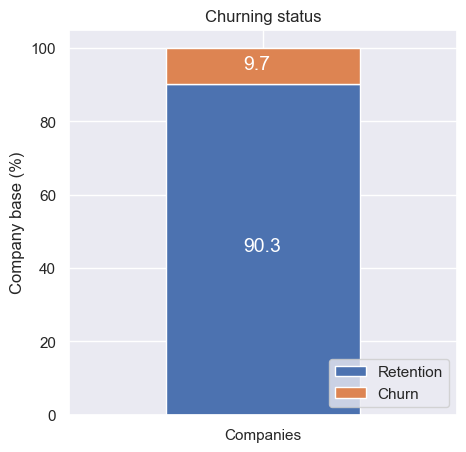

In [50]:
churn = client_df[['id', 'churn']]
churn.columns = ['Companies', 'churn'] #Renames the id column to Companies and Keeps the second column name as churn.
churn_total = churn.groupby(churn['churn']).count()
churn_percentage = churn_total / churn_total.sum() * 100
plot_stacked_bars(churn_percentage.transpose(), "Churning status", (5, 5), legend_="lower right")

Observation:

- Approximately **90.3%** of customers are retained.
- Approximately **9.7%** of customers have churned.
- The dataset is imbalanced, with retained customers significantly outnumbering churned customers.

**Important insight:** Only around 1 in 10 customers have churned, so identifying the factors associated with this smaller group is important for our analysis.

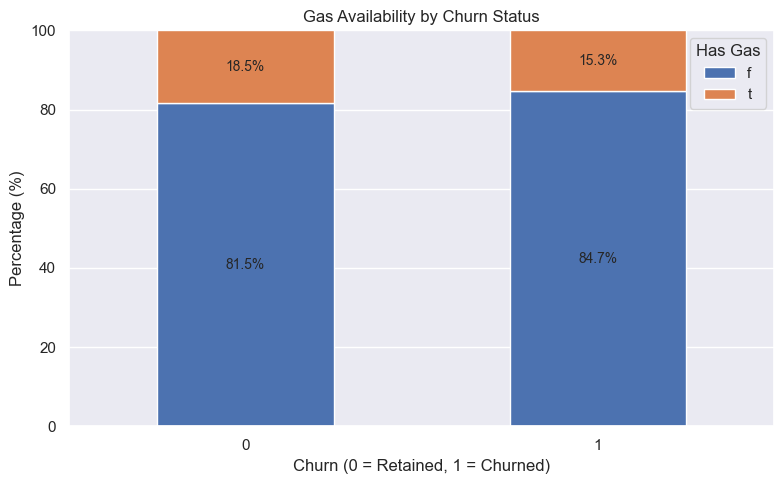

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

churn_gas = pd.crosstab(
    client_df['churn'],
    client_df['has_gas'],
    normalize='index'
) * 100

ax = churn_gas.plot(kind='bar', stacked=True, figsize=(8, 5))

# Display percentages on bars
for container in ax.containers:
    labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=10)

plt.title('Gas Availability by Churn Status')
plt.xlabel('Churn (0 = Retained, 1 = Churned)')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Has Gas')
plt.tight_layout()
plt.show()

Observation

- Among retained customers (`churn = 0`), **81.5%** have only electricity, while **18.5%** have both electricity and gas.
- Among churned customers (`churn = 1`), **84.7%** have only electricity, while **15.3%** have both electricity and gas.
- percentage distribution is almost similar for retained and churned customers.

**Conclusion:** Customers with only electricity have a slightly higher churn proportion within their group than customers having both electricity and gas. 

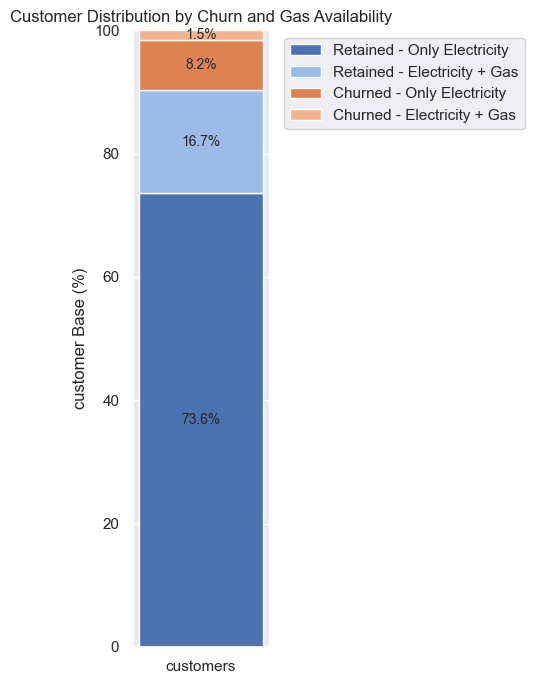

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate overall percentage distribution
data = pd.crosstab(
    client_df['churn'],
    client_df['has_gas'],
    normalize=True
) * 100

# Extract four segments
values = [
    data.loc[0, 'f'],  # Retained - Only electricity
    data.loc[0, 't'],  # Retained - Electricity + Gas
    data.loc[1, 'f'],  # Churned - Only electricity
    data.loc[1, 't']   # Churned - Electricity + Gas
]

labels = [
    'Retained - Only Electricity',
    'Retained - Electricity + Gas',
    'Churned - Only Electricity',
    'Churned - Electricity + Gas'
]

colors = ['#4C72B0', '#9BBCE8', '#DD8452', '#F3B58F']

# Plot single stacked bar
fig, ax = plt.subplots(figsize=(5, 7))

bottom = 0

for value, label, color in zip(values, labels, colors):

    ax.bar(
        'customers',
        value,
        bottom=bottom,
        color=color,
        edgecolor='white',
        label=label
    )

    if value > 0:
        ax.text(
            0,
            bottom + value / 2,
            f'{value:.1f}%',
            ha='center',
            va='center',
            fontsize=10
        )

    bottom += value

ax.set_title('Customer Distribution by Churn and Gas Availability')
ax.set_ylabel('customer Base (%)')
ax.set_ylim(0, 100)

ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

observation:

- 90.3% of customers are retained, while 9.7% have churned.
- 73.6% are retained customers with only electricity.
- 16.7% are retained customers with both electricity and gas.
- 8.2% are churned customers with only electricity.
- 1.5% are churned customers with both electricity and gas.

**Conclusion:** Most churned customers belong to the electricity-only segment.

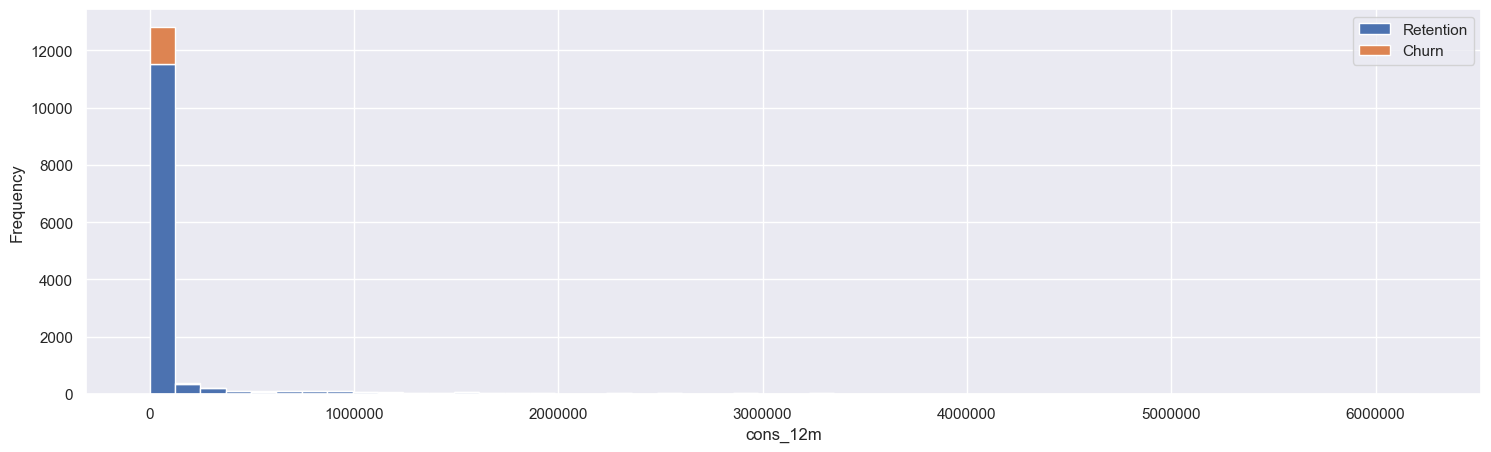

In [53]:
consumption = client_df[['id', 'cons_12m', 'cons_gas_12m', 'cons_last_month', 'imp_cons', 'has_gas', 'churn'
                         ,'forecast_cons_12m','forecast_cons_year','forecast_discount_energy','forecast_meter_rent_12m',
                        'forecast_price_energy_off_peak','forecast_price_energy_peak','forecast_price_pow_off_peak',
                         'margin_gross_pow_ele','margin_net_pow_ele','nb_prod_act','net_margin','num_years_antig','pow_max']].copy()

fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#cons_12m have 0 to 6000000, electricity consumption of the past 12 months
plot_distribution(consumption, 'cons_12m', axs)

observation

- Y-axis represents Frequency, meaning the number of customers falling within each electricity consumption range.
- distribution was highly right-skewed due to a few customers having extremely high consumption. so take a log on it
- Both retained and churned customers are present across different consumption ranges.
- Some customers with zero electricity consumption have also churned.

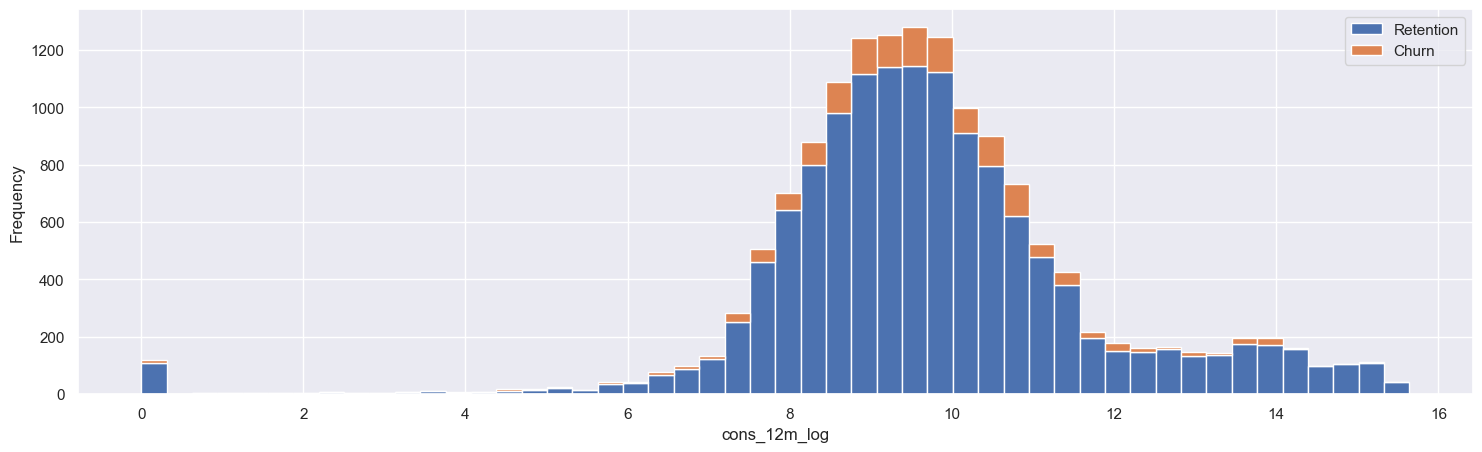

In [54]:
consumption['cons_12m_log'] = np.log1p(consumption['cons_12m'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))
plot_distribution(consumption, 'cons_12m_log', axs)

obervation:  
- Most customers have electricity consumption values between 8 and 11 (log scale).
- Customers with higher electricity consumption appear to show a slightly higher churn tendency in certain consumption ranges

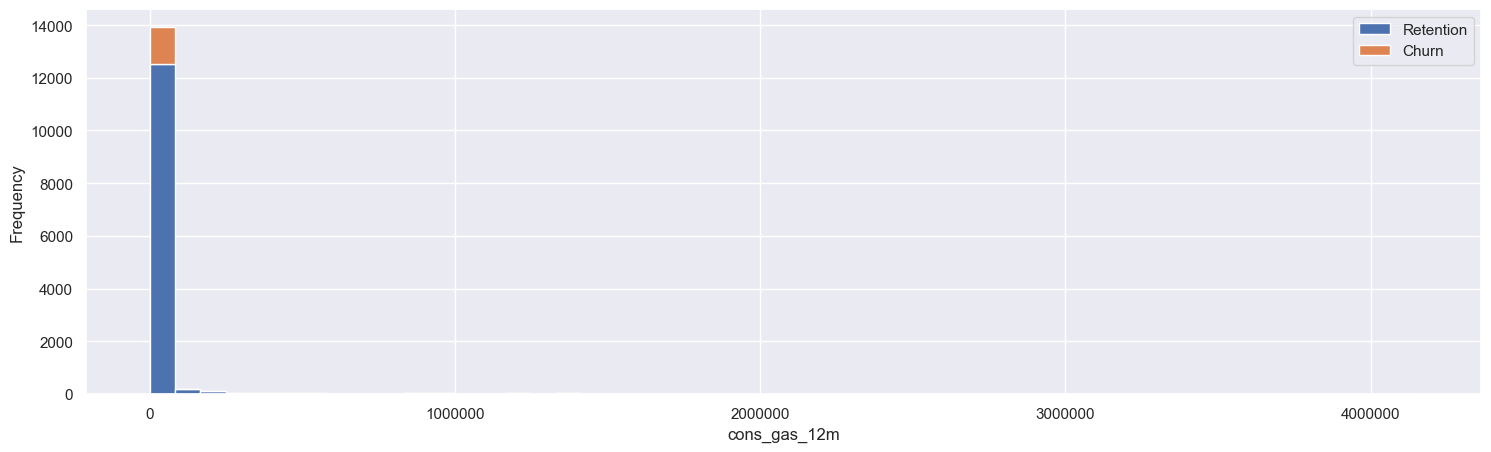

In [55]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#cons_gas_12m have 0 to 4000000, gas consumption of the past 12 months
plot_distribution(consumption, 'cons_gas_12m', axs)

observation

- Y-axis represents Frequency, meaning the number of customers falling within each gas consumption range.
- A very large number of customers have zero gas consumption.
- Only a small proportion of customers consume gas.
- The gas consumption distribution is highly right-skewed.
- Both retained and churned customers exist among customers with zero gas consumption.

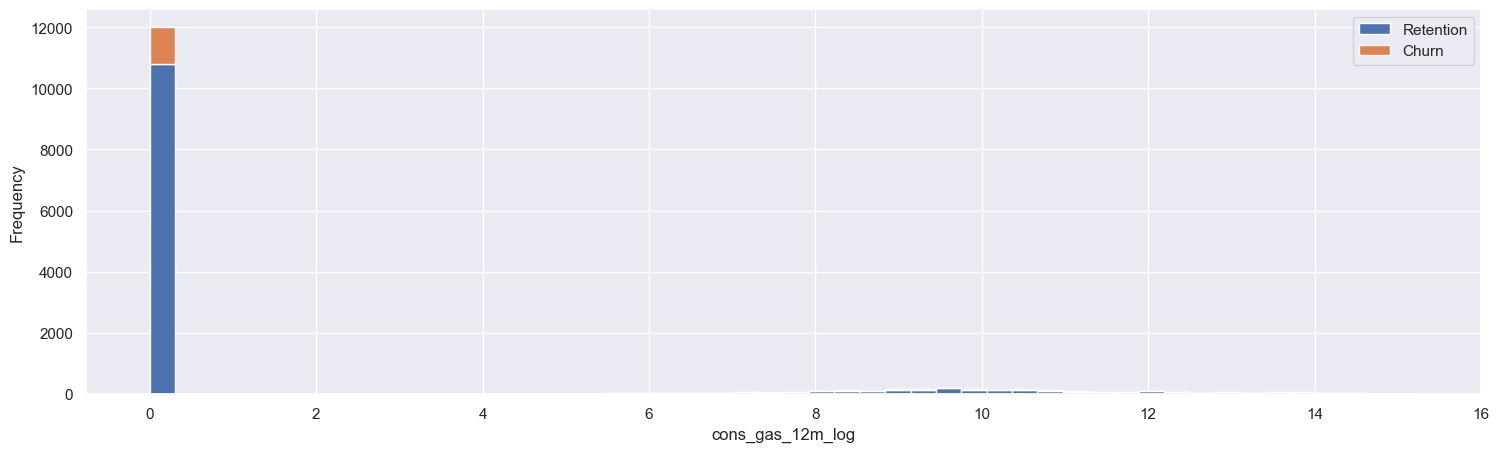

In [56]:
consumption['cons_gas_12m_log'] = np.log1p(consumption['cons_gas_12m'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#cons_gas_12m log scale gas consumption of the past 12 months
plot_distribution(consumption, 'cons_gas_12m_log', axs)

observation

- Even after log transformation, a large spike remains at zero because log1p(0) = 0.
- Both retained and churned customers exist among customers with zero gas consumption.

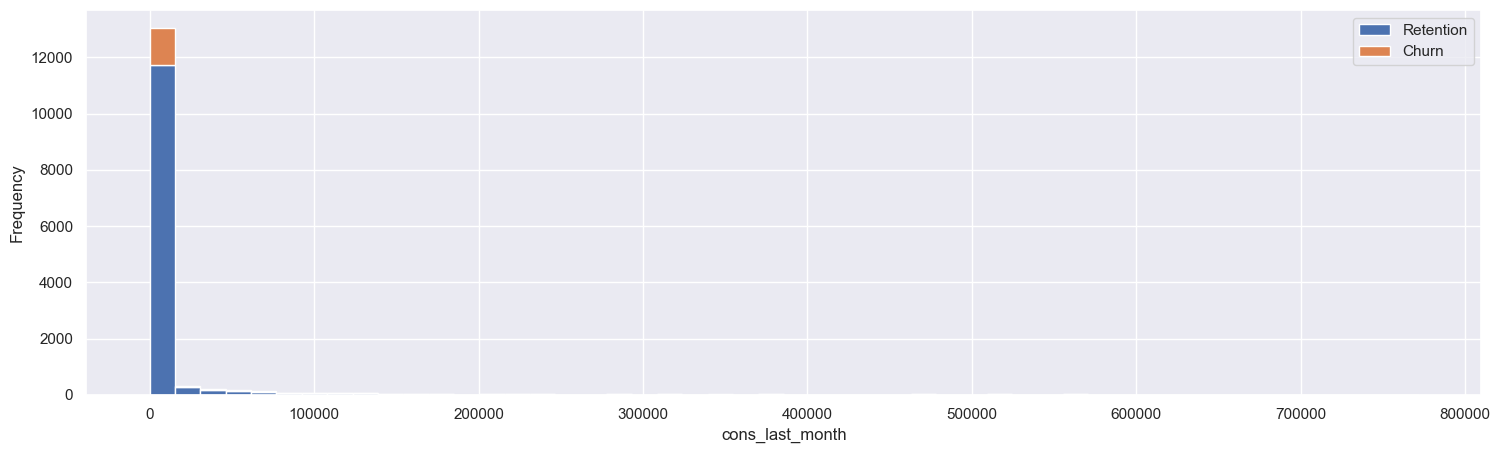

In [57]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#cons_last_month have 0 to 800000, electricity consumption of last month
plot_distribution(consumption, 'cons_last_month', axs)

observation:

- Most customers have zero or very low electricity consumption in the last month.
- The distribution is highly right-skewed, with a few customers having extremely high consumption.
- Both churned and retained customers are present, but retained customers are more than than churned customers.

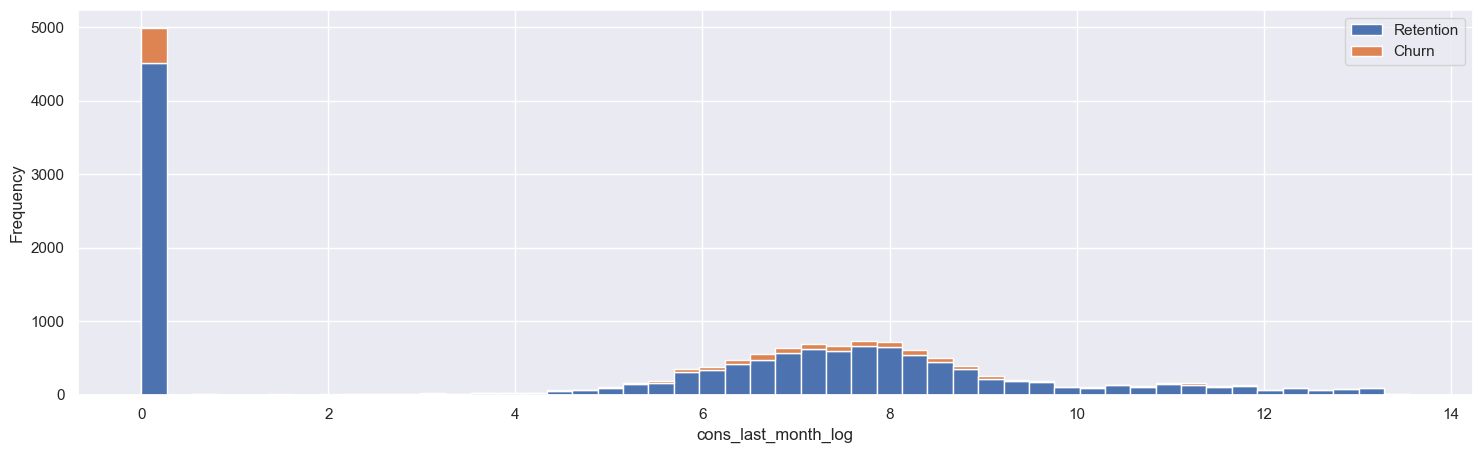

In [58]:
consumption['cons_last_month_log'] = np.log1p(consumption['cons_last_month'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#cons_last_month log scale electricity consumption of the last month
plot_distribution(consumption, 'cons_last_month_log', axs)

observation:

- Both churned and retained customers are present across different consumption ranges.
- Most customers with zero consumption are retained, but the churn proportion appears slightly higher at 0th level.
- Retained customers are considerably higher in number than churned customers across most consumption ranges.

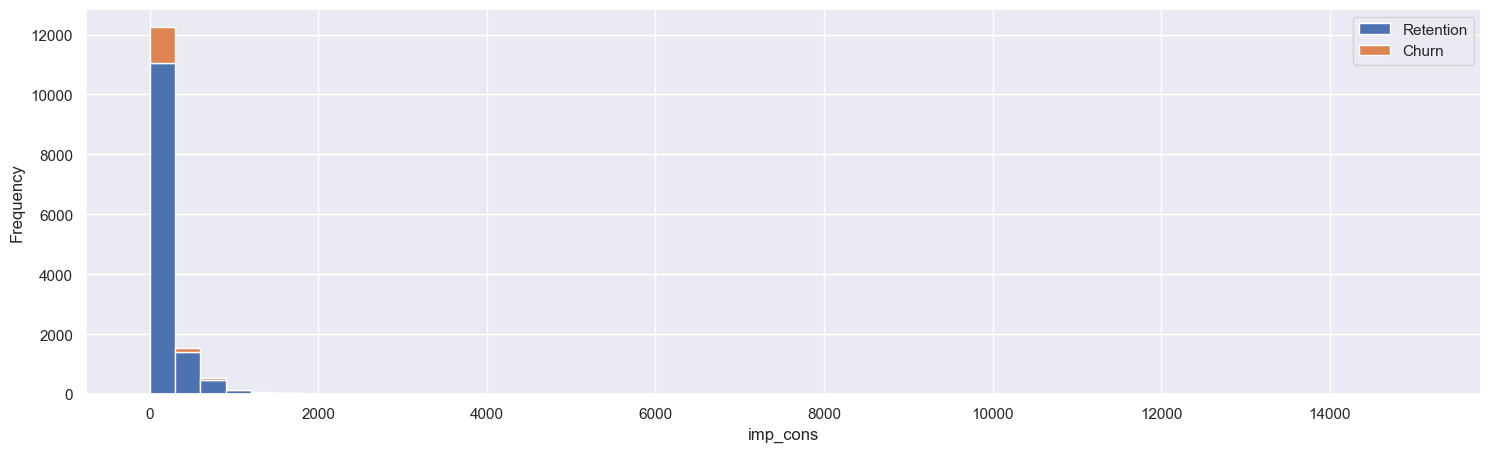

In [59]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#imp_cons have 0 to 14000, current paid consumption
plot_distribution(consumption, 'imp_cons', axs)

Observations:

- Most customers have zero or very low current paid consumption.
- The distribution is highly right-skewed, with a few customers having extremely high values.
- Retained customers are considerably higher in number than churned customers.

Note: The data dictionary defines `imp_cons` as current paid consumption but does not specify its exact unit or whether it refers specifically to electricity or gas.

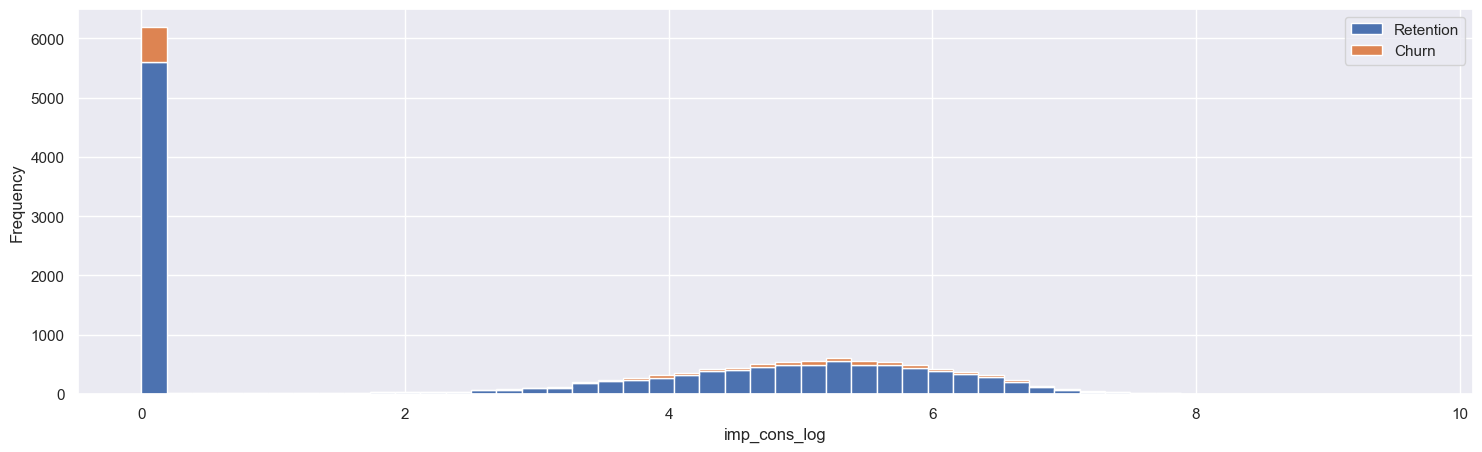

In [60]:
consumption['imp_cons_log'] = np.log1p(consumption['imp_cons'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#imp_cons log scale of current paid consumption
plot_distribution(consumption, 'imp_cons_log', axs)

Observations:

- Log transformation reduces the right skewness and makes the distribution easier to visualize.
- Most customers with positive values are concentrated between 3 and 7 on the log scale.
- Most customers with zero consumption are retained, but the churn proportion appears slightly higher at 0th level.
- Retained customers are considerably higher in number than churned customers across most consumption ranges.

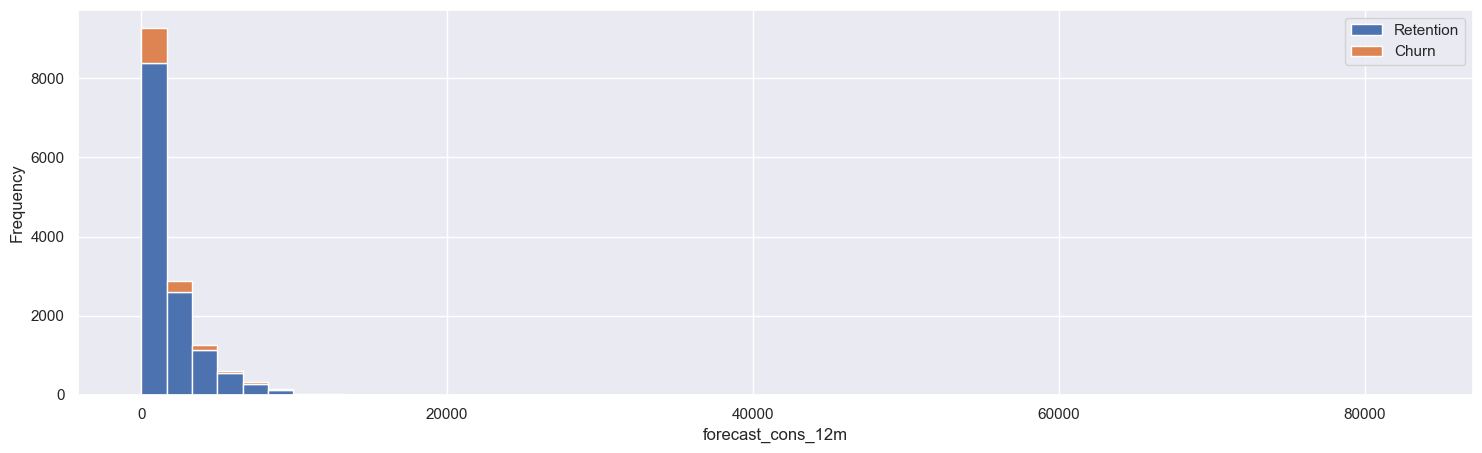

In [61]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#forecast_cons_12m - forecasted electricity consumption for next 12 months
plot_distribution(consumption, 'forecast_cons_12m', axs)

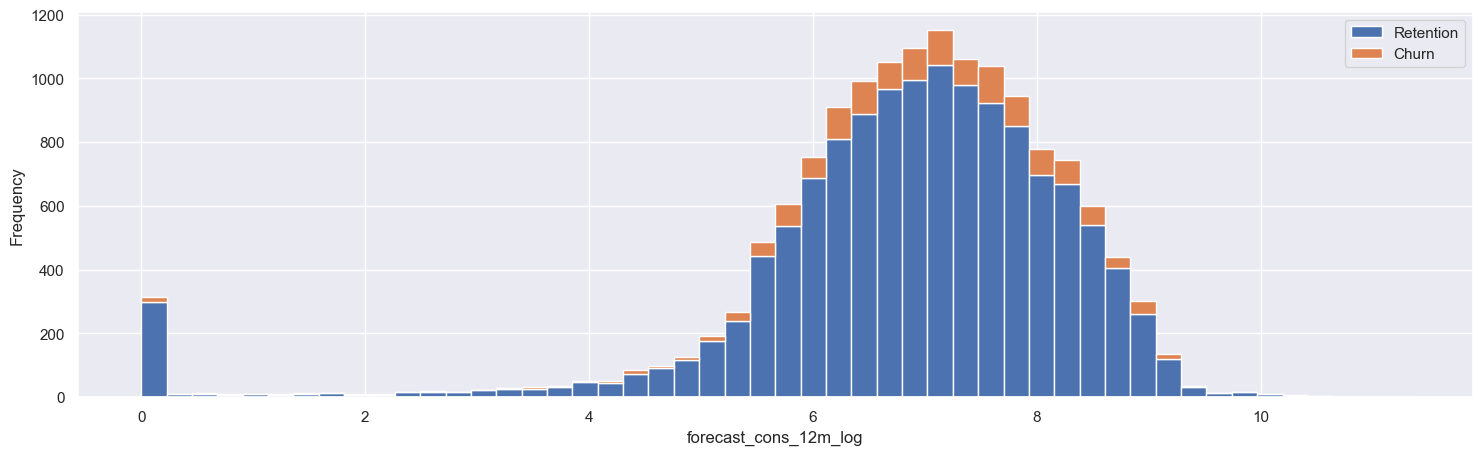

In [62]:
consumption['forecast_cons_12m_log'] = np.log1p(consumption['forecast_cons_12m'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'forecast_cons_12m_log', axs)

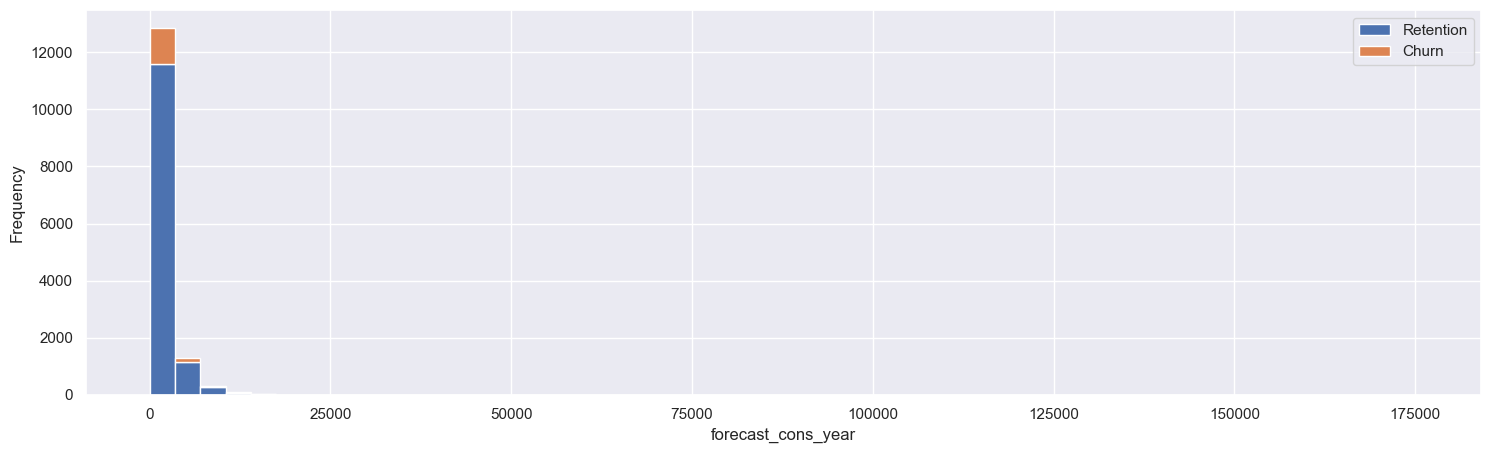

In [63]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#forecast_cons_year - forecasted electricity consumption for the next calendar year
plot_distribution(consumption, 'forecast_cons_year', axs)

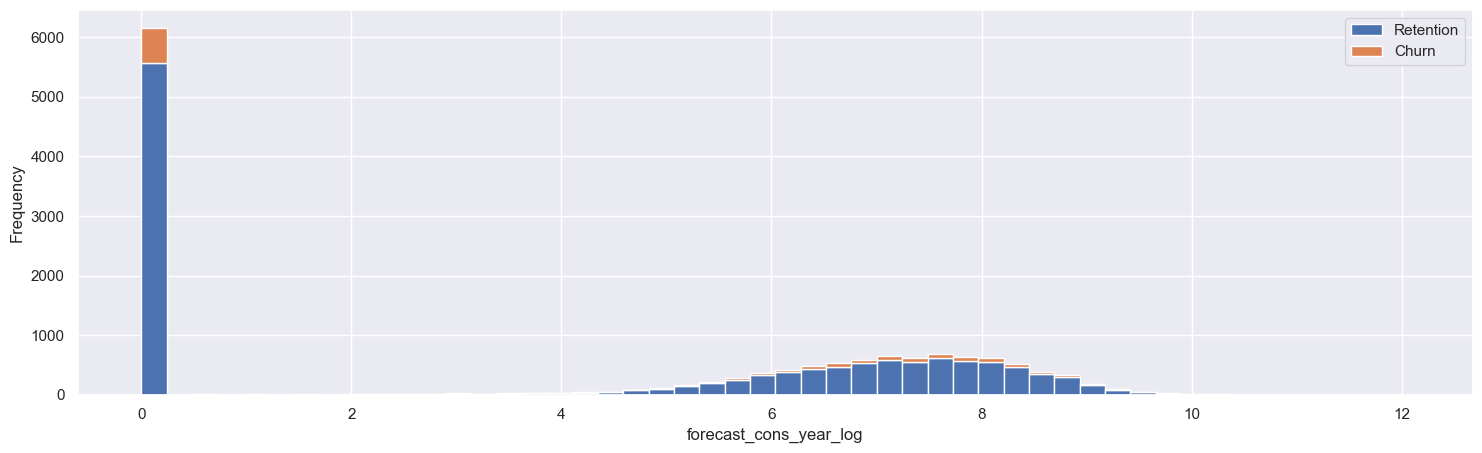

In [64]:
consumption['forecast_cons_year_log'] = np.log1p(consumption['forecast_cons_year'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'forecast_cons_year_log', axs)

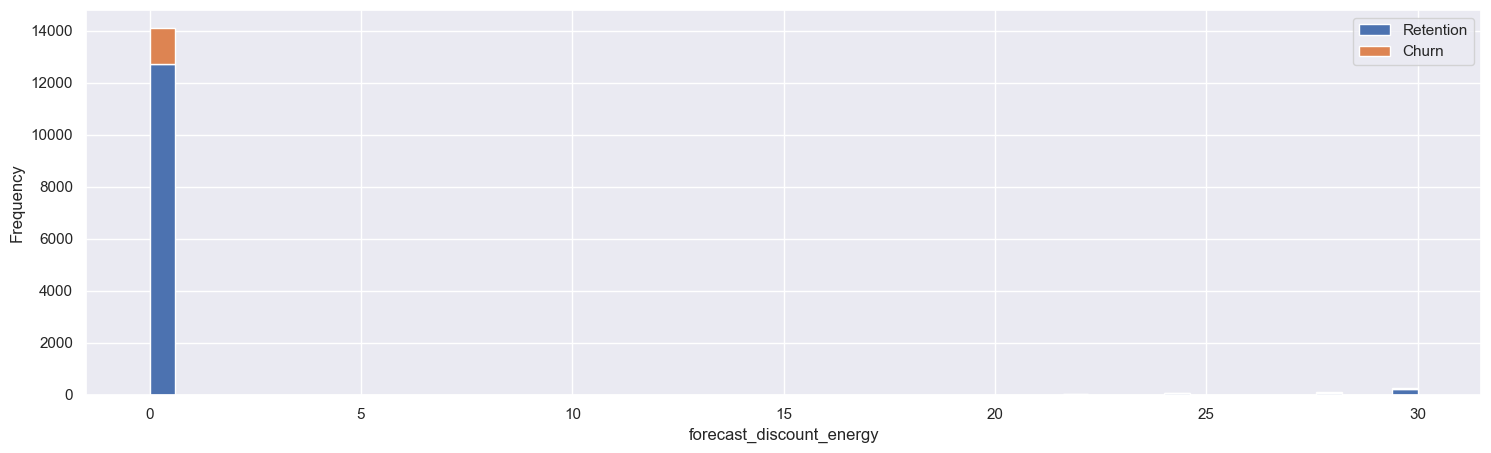

In [65]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#forecast_discount_energy - forecasted value of current discount
plot_distribution(consumption, 'forecast_discount_energy', axs)

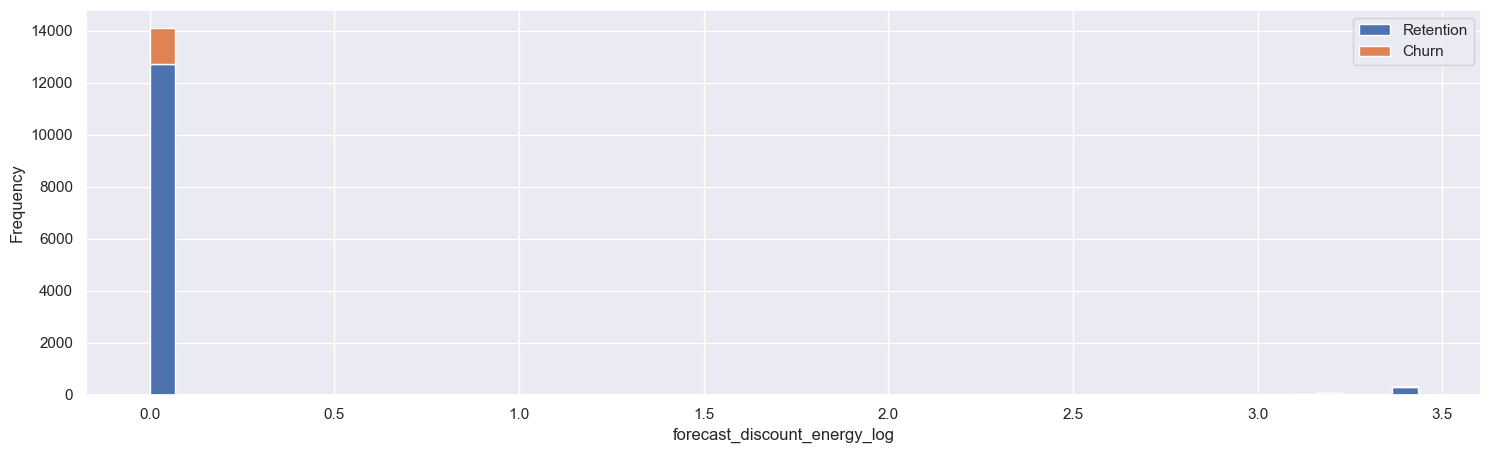

In [66]:
consumption['forecast_discount_energy_log'] = np.log1p(consumption['forecast_discount_energy'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'forecast_discount_energy_log', axs)

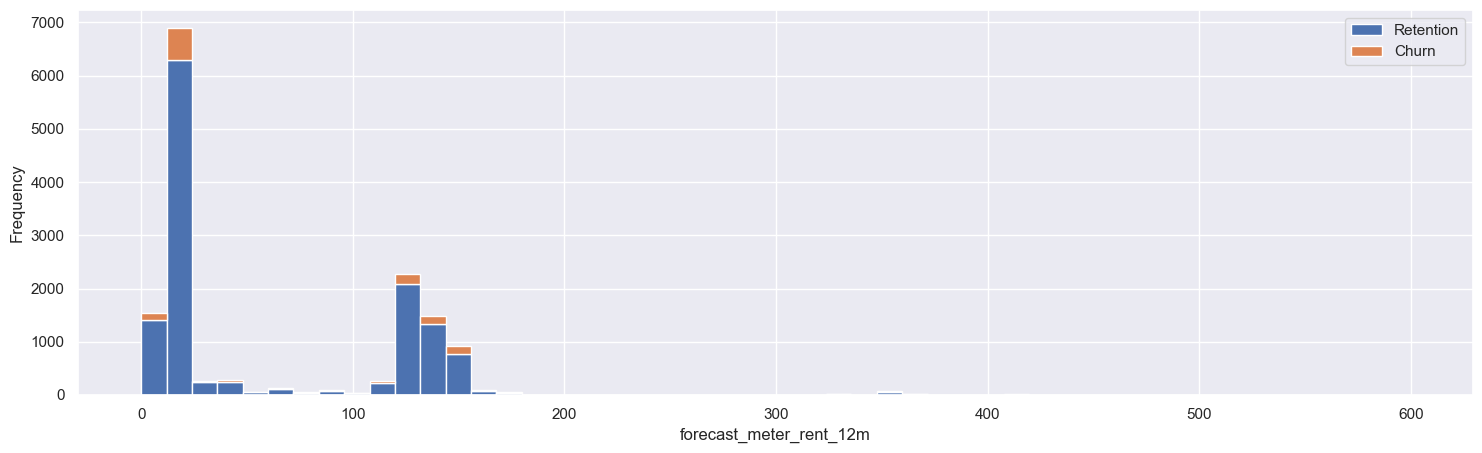

In [67]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#forecast_meter_rent_12m - forecasted bill of meter rental for the next 2 months
plot_distribution(consumption, 'forecast_meter_rent_12m', axs)

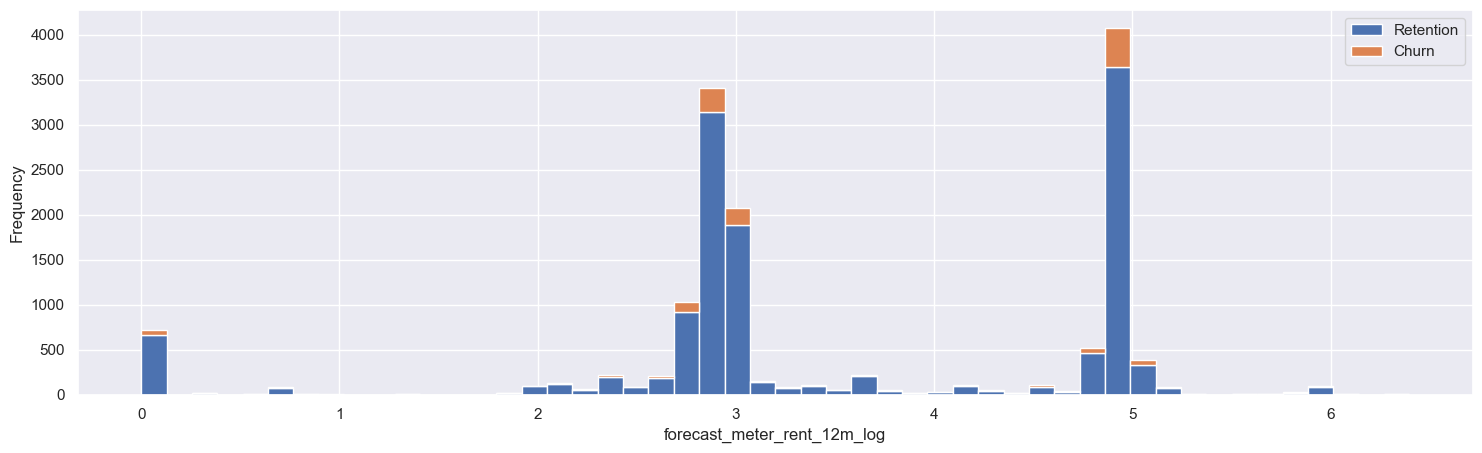

In [68]:
consumption['forecast_meter_rent_12m_log'] = np.log1p(consumption['forecast_meter_rent_12m'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'forecast_meter_rent_12m_log', axs)

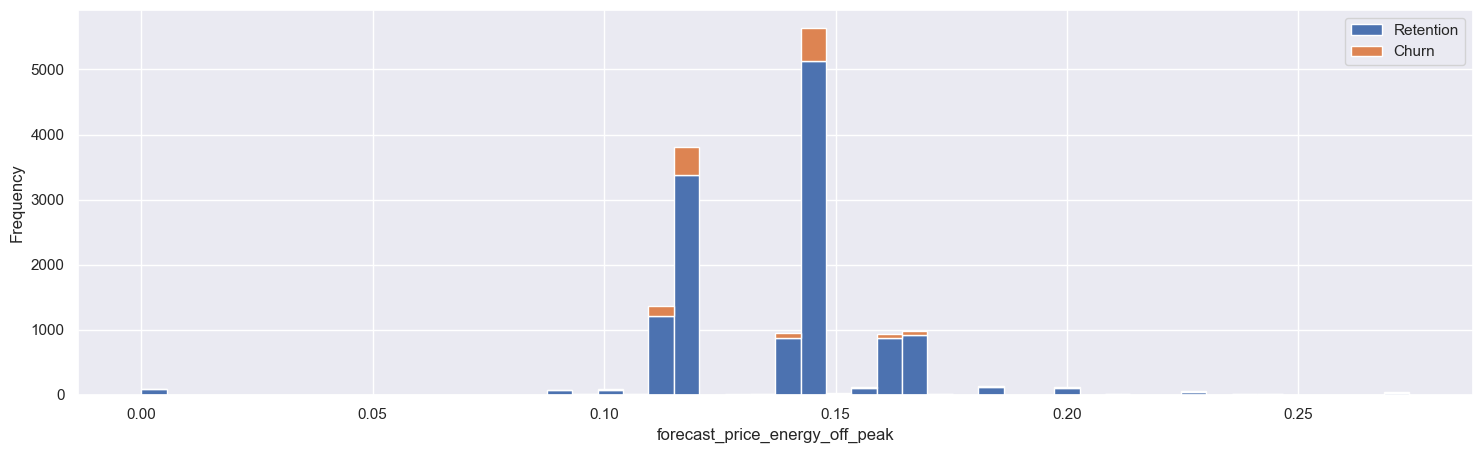

In [69]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#forecast_price_energy_off_peak - forecasted energy price for 1st period (off peak)
plot_distribution(consumption, 'forecast_price_energy_off_peak', axs)

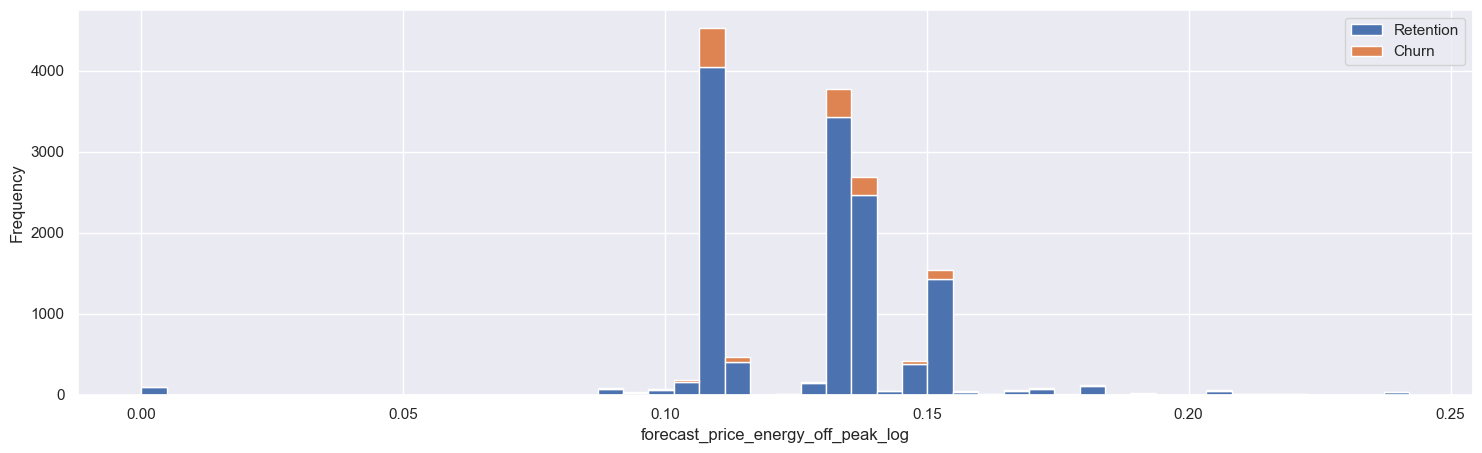

In [70]:
consumption['forecast_price_energy_off_peak_log'] = np.log1p(consumption['forecast_price_energy_off_peak'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'forecast_price_energy_off_peak_log', axs)

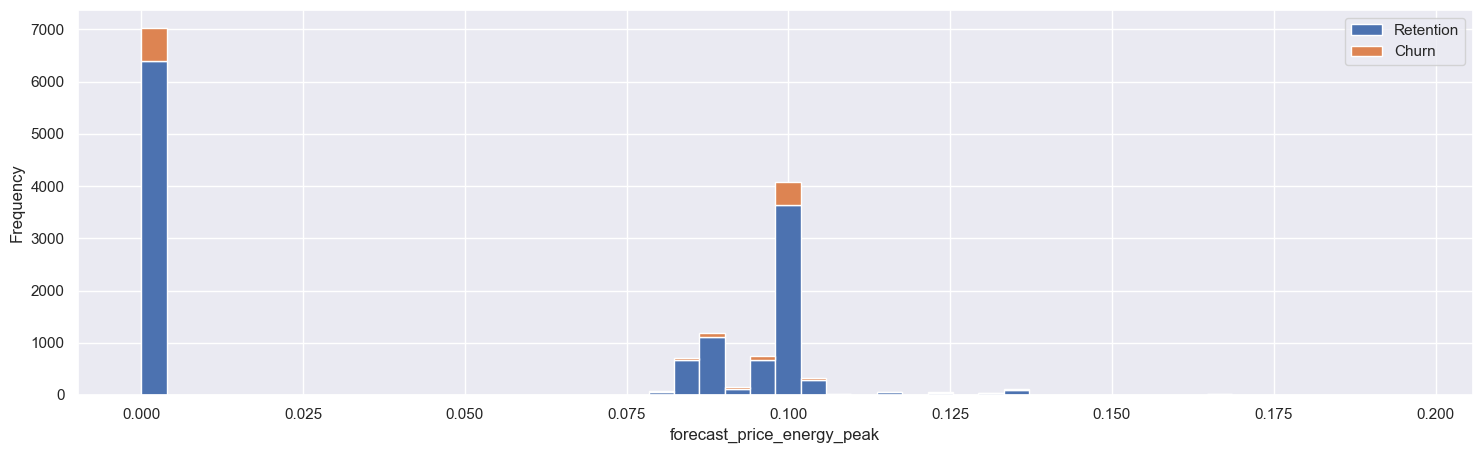

In [71]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#forecast_price_energy_peak - forecasted energy price for 2nd period (peak)
plot_distribution(consumption, 'forecast_price_energy_peak', axs)

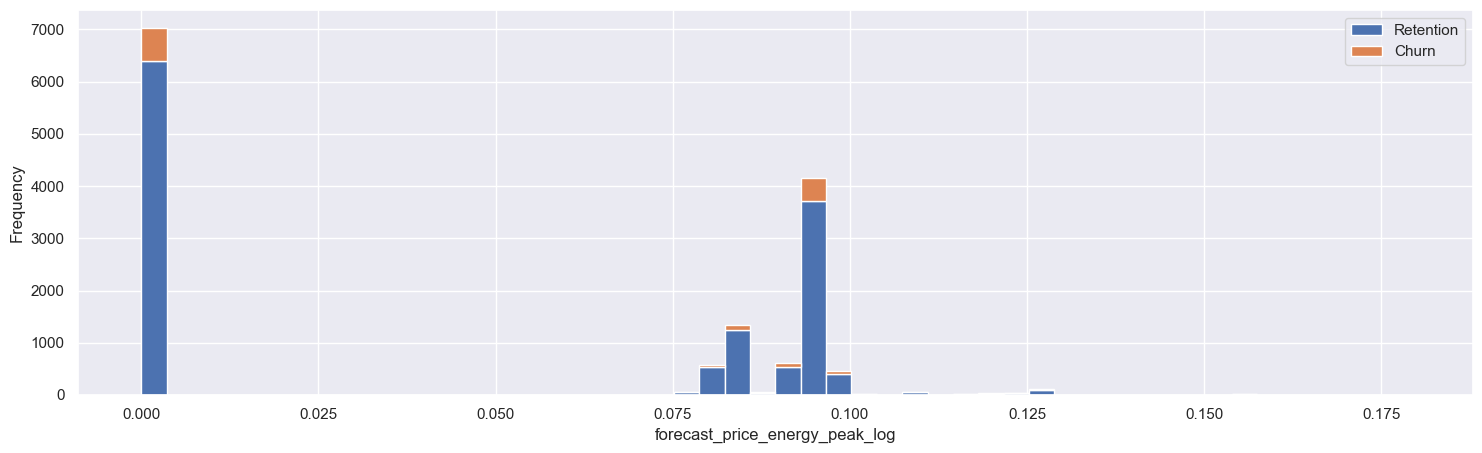

In [72]:
consumption['forecast_price_energy_peak_log'] = np.log1p(consumption['forecast_price_energy_peak'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'forecast_price_energy_peak_log', axs)

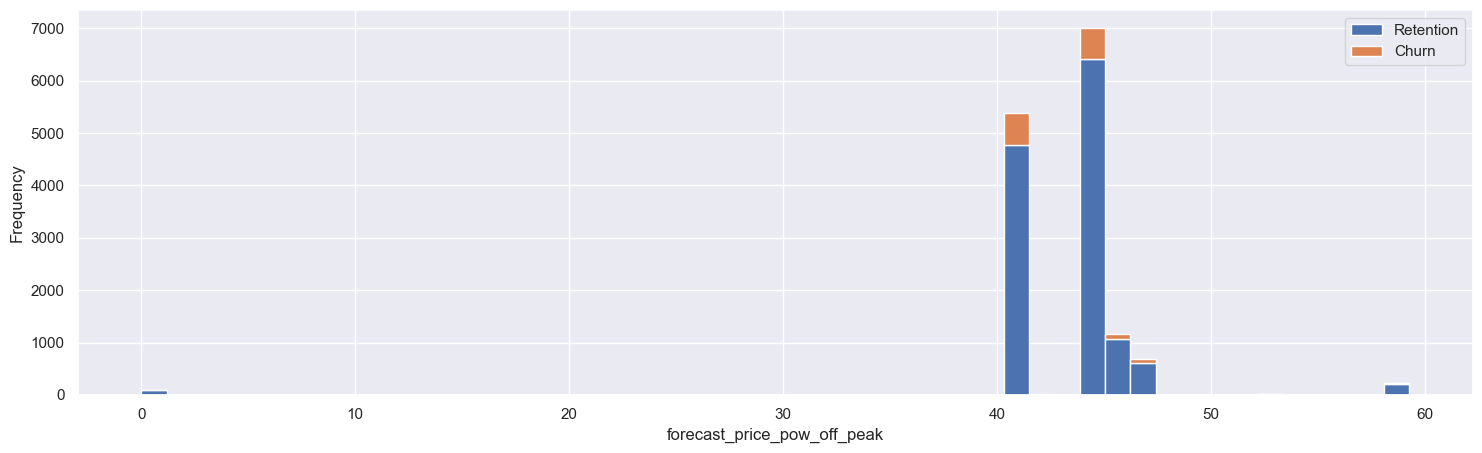

In [73]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#forecast_price_pow_off_peak - forecasted power price for 1st period (off peak)
plot_distribution(consumption, 'forecast_price_pow_off_peak', axs)

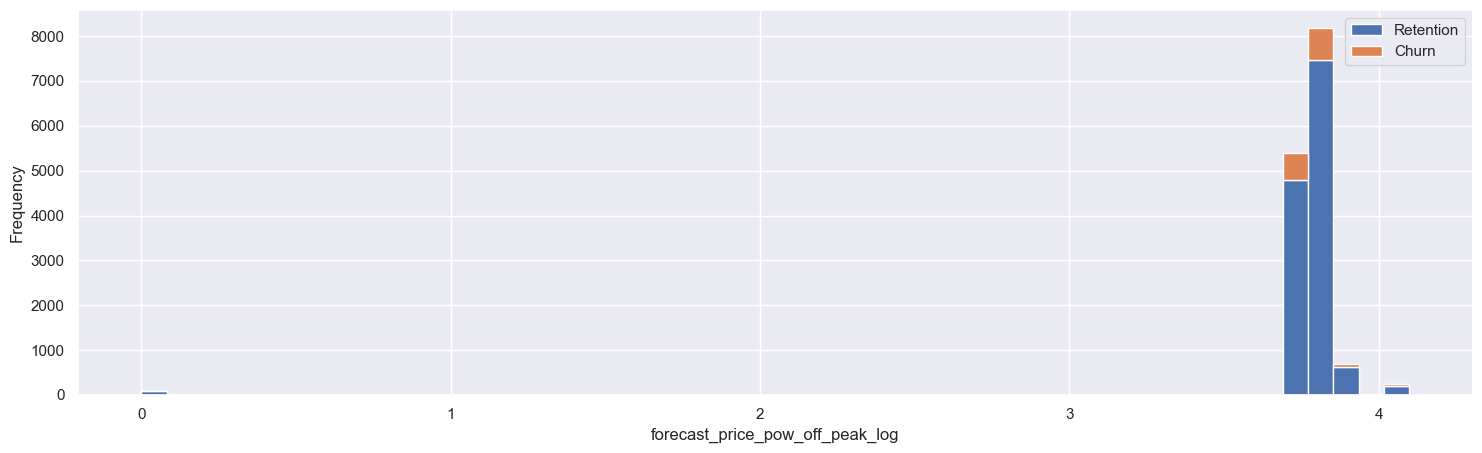

In [74]:
consumption['forecast_price_pow_off_peak_log'] = np.log1p(consumption['forecast_price_pow_off_peak'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'forecast_price_pow_off_peak_log', axs)

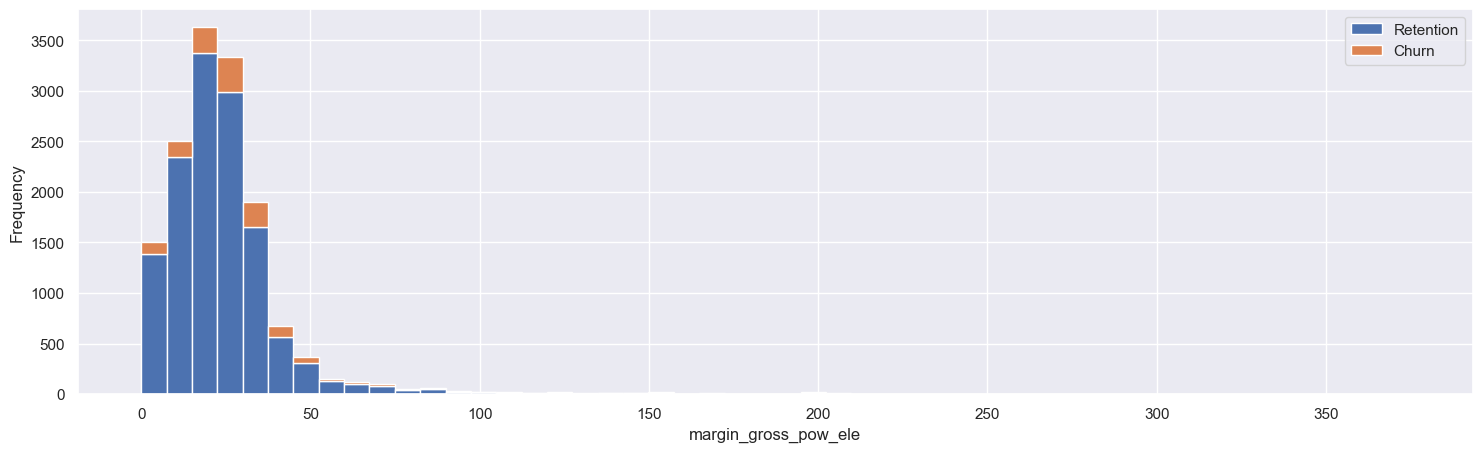

In [75]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#margin_gross_pow_ele - gross margin on power subscription
plot_distribution(consumption, 'margin_gross_pow_ele', axs)

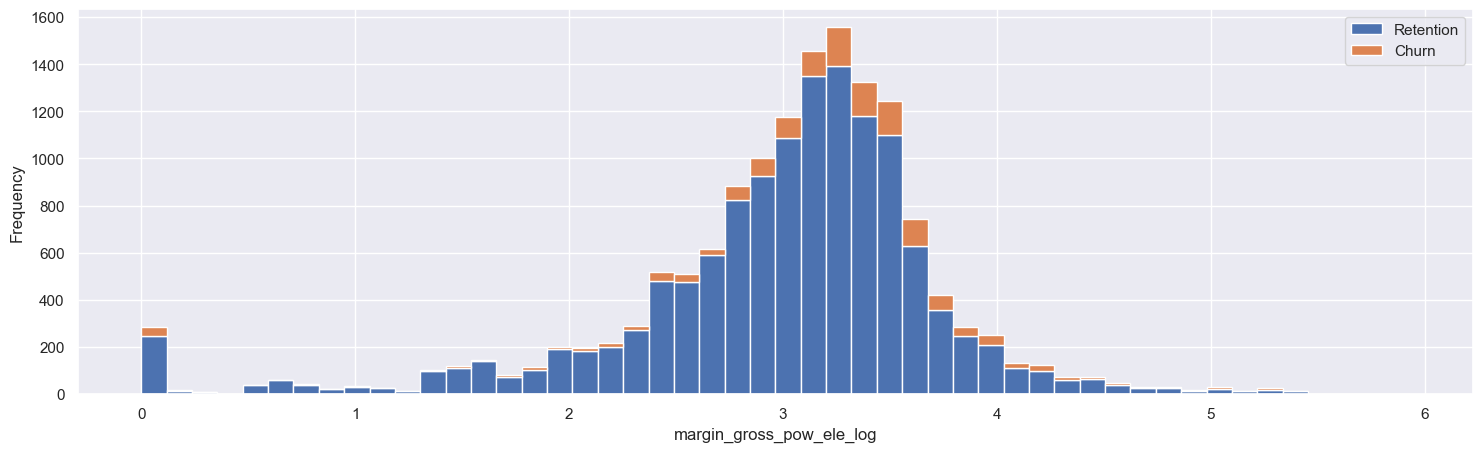

In [76]:
consumption['margin_gross_pow_ele_log'] = np.log1p(consumption['margin_gross_pow_ele'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'margin_gross_pow_ele_log', axs)

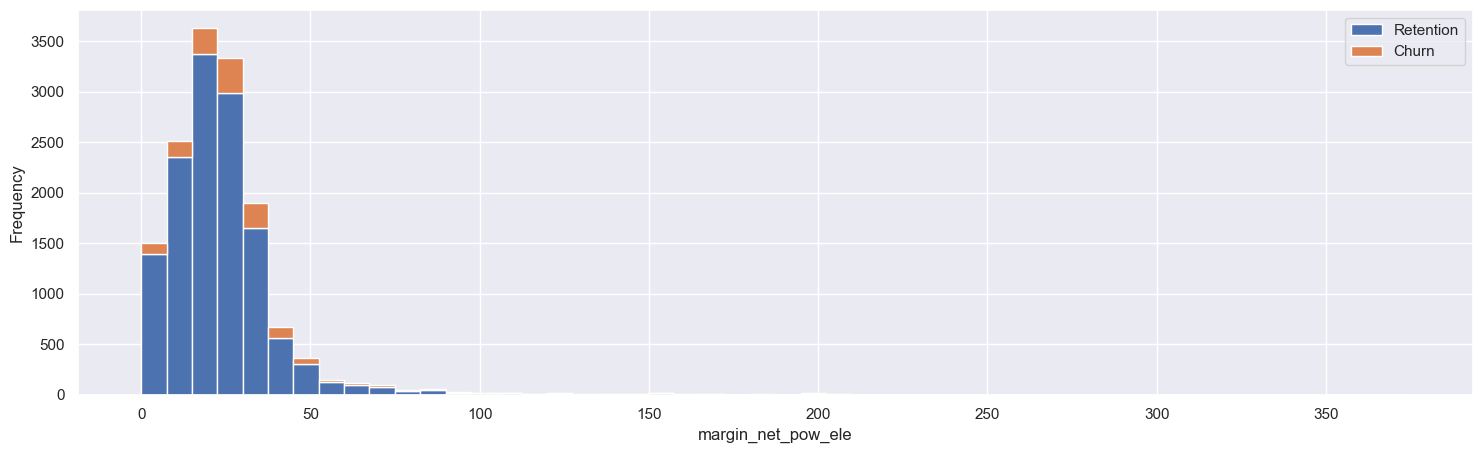

In [77]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#margin_net_pow_ele - net margin on power subscription
plot_distribution(consumption, 'margin_net_pow_ele', axs)

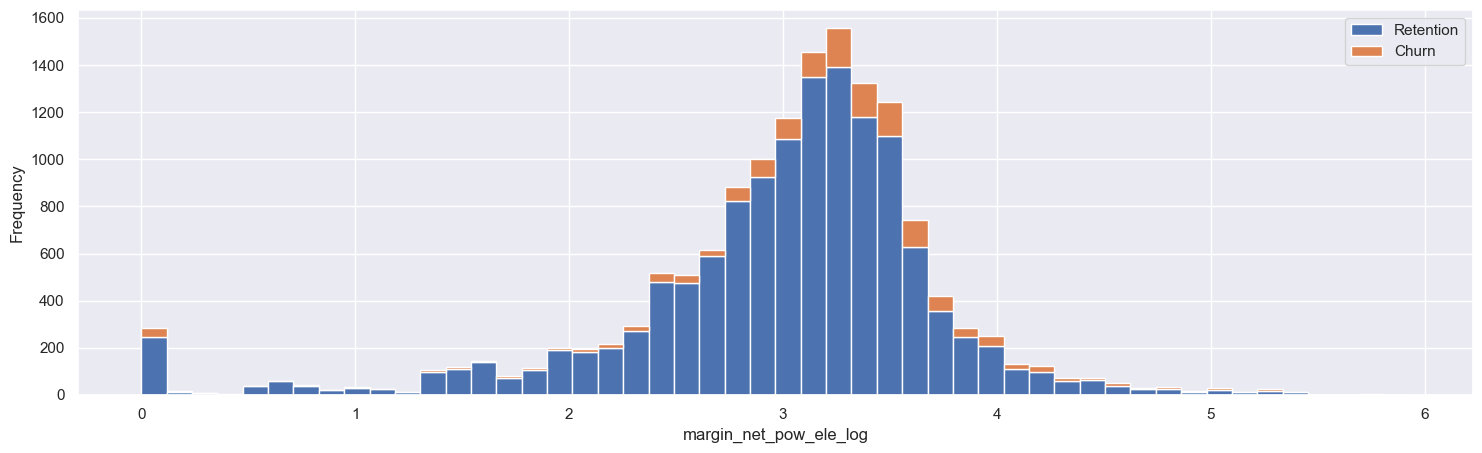

In [78]:
consumption['margin_net_pow_ele_log'] = np.log1p(consumption['margin_net_pow_ele'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'margin_net_pow_ele_log', axs)

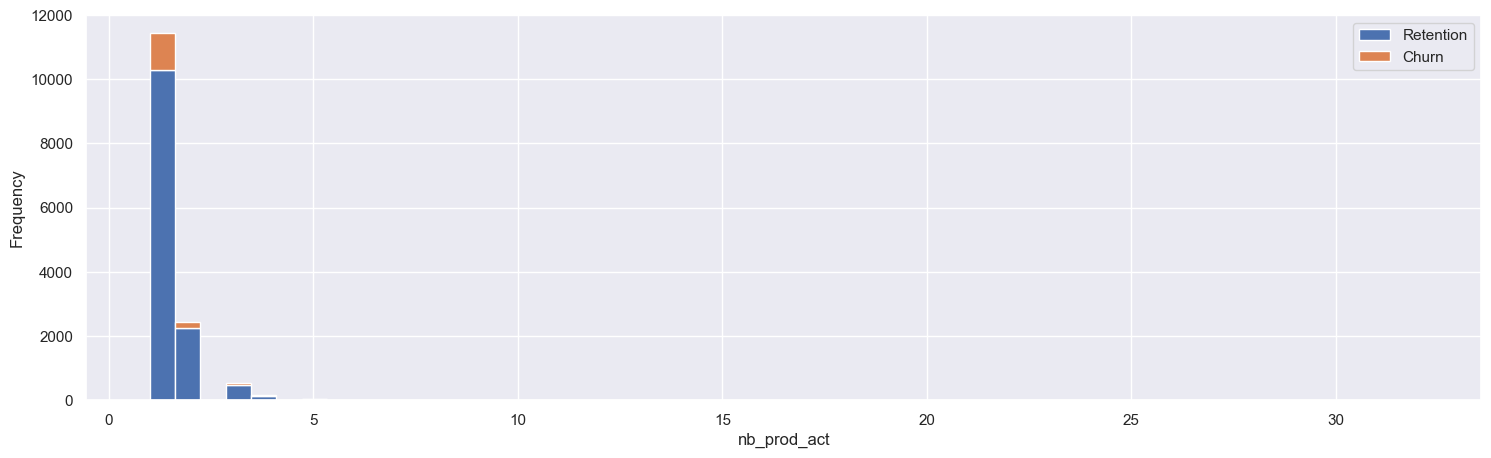

In [79]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#nb_prod_act - number of active products and services
plot_distribution(consumption, 'nb_prod_act', axs)

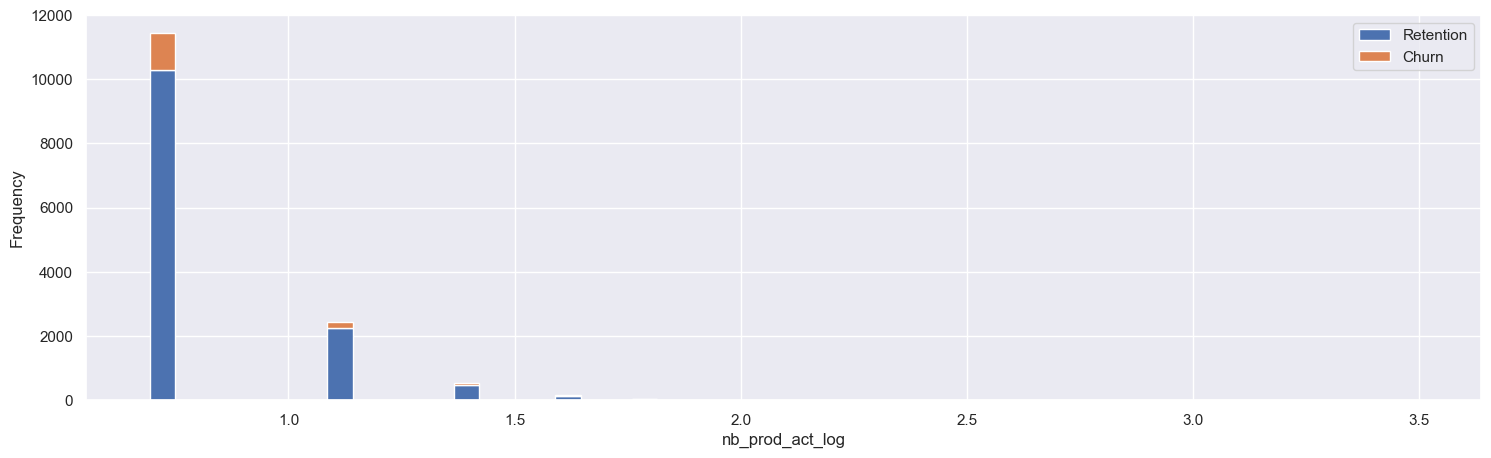

In [80]:
consumption['nb_prod_act_log'] = np.log1p(consumption['nb_prod_act'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'nb_prod_act_log', axs)

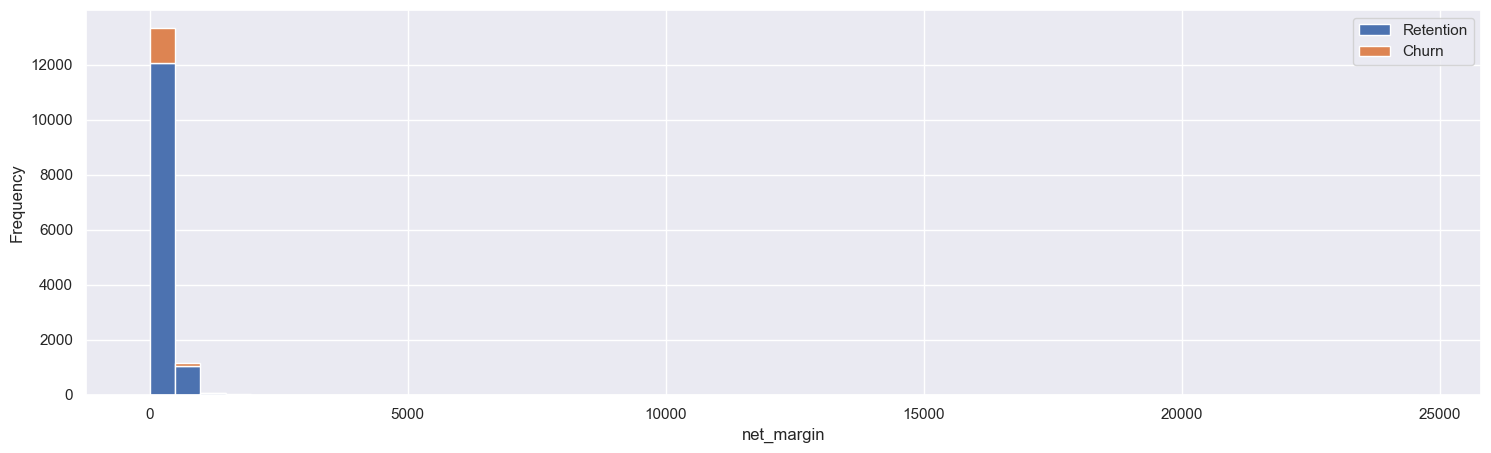

In [81]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#net_margin -  total net margin
plot_distribution(consumption, 'net_margin', axs)

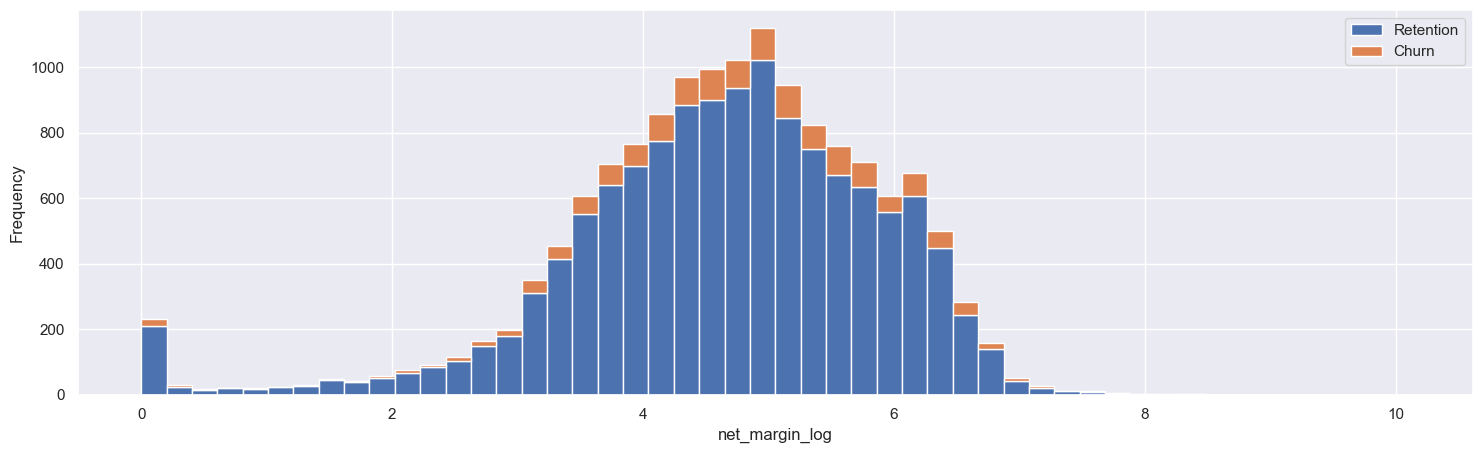

In [82]:
consumption['net_margin_log'] = np.log1p(consumption['net_margin'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'net_margin_log', axs)

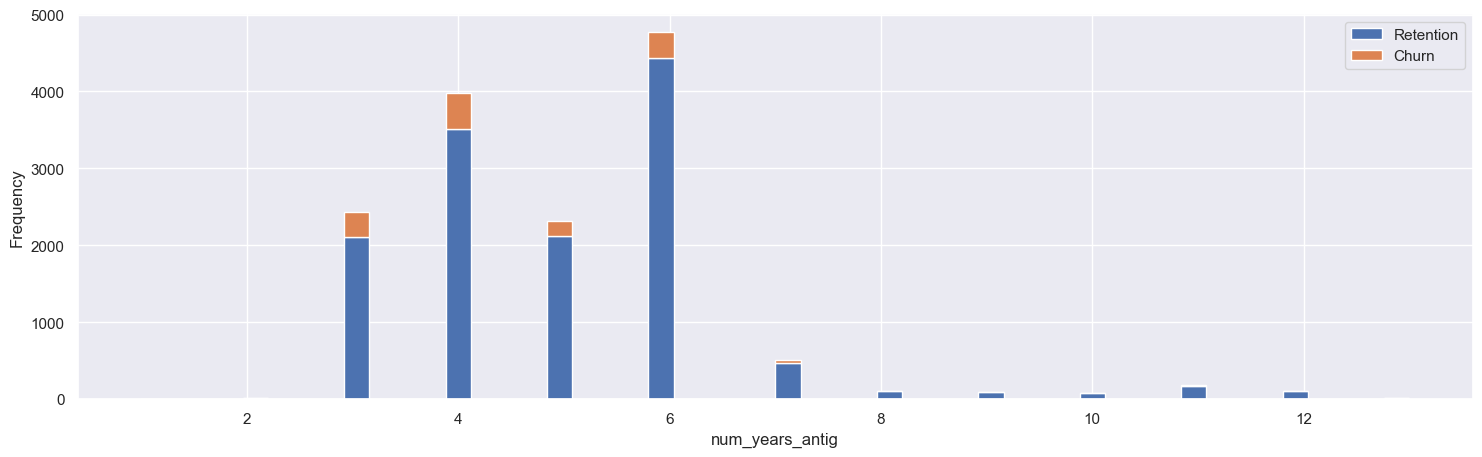

In [83]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#num_years_antig - antiquity of the client (in number of years)
plot_distribution(consumption, 'num_years_antig', axs)

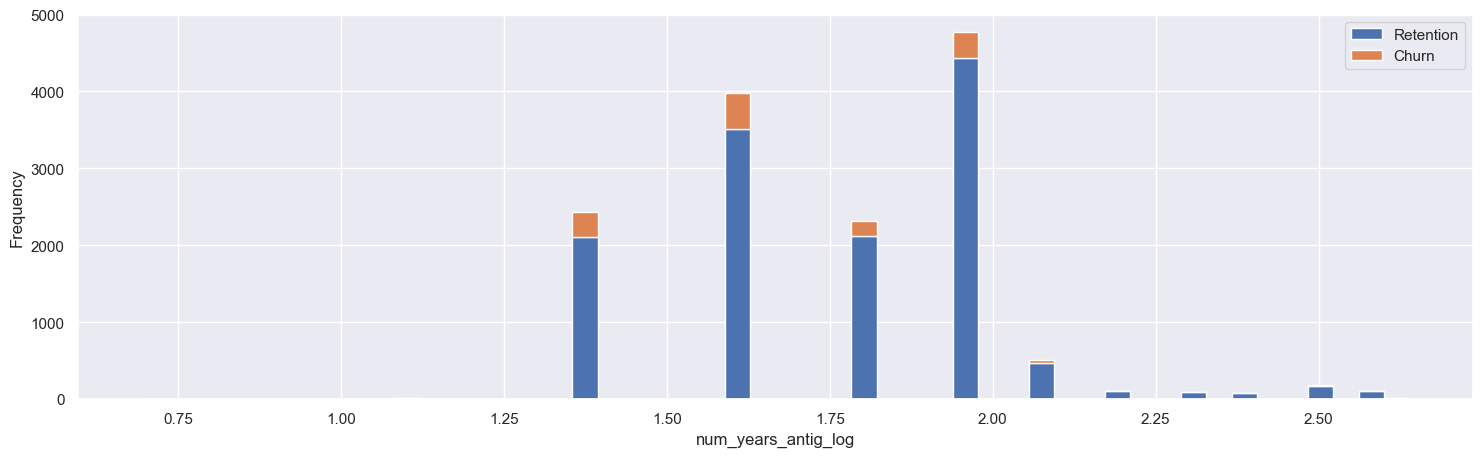

In [84]:
consumption['num_years_antig_log'] = np.log1p(consumption['num_years_antig'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'num_years_antig_log', axs)

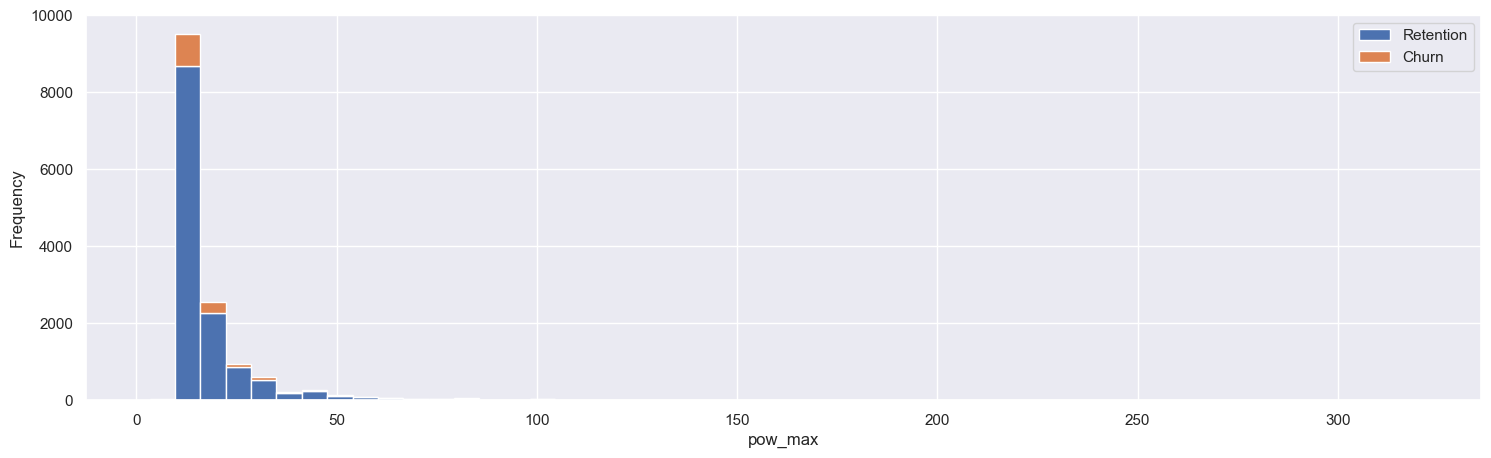

In [85]:
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

#pow_max - subscribed power
plot_distribution(consumption, 'pow_max', axs)

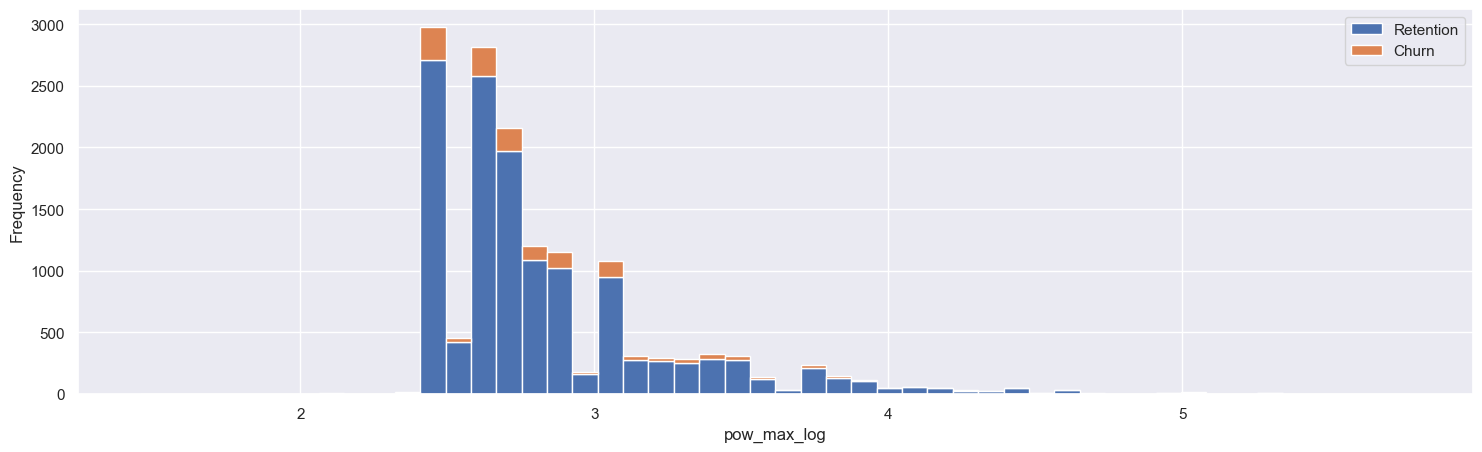

In [86]:
consumption['pow_max_log'] = np.log1p(consumption['pow_max'])
fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'pow_max_log', axs)

In [87]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def churn_rate_by_bins(df, column, bins=5, method='qcut', threshold=15):

    # Use individual values for low-cardinality features
    if df[column].nunique() <= threshold:

        result = (
            df.groupby(column, observed=True)['churn']
            .agg(['count', 'sum'])
            .rename(columns={
                'count': 'total_customers',
                'sum': 'churned_customers'
            })
        )

        result['retained_customers'] = (
            result['total_customers'] - result['churned_customers']
        )

        result['churn_rate'] = (
            result['churned_customers'] /
            result['total_customers'] * 100
        )

        result['group_label'] = result.index.astype(str)

    # Use bins for high-cardinality features
    else:

        if method == 'qcut':
            groups = pd.qcut(
                df[column], q=bins, duplicates='drop'
            )
        else:
            groups = pd.cut(df[column], bins=bins)

        result = (
            df.groupby(groups, observed=True)['churn']
            .agg(['count', 'sum'])
            .rename(columns={
                'count': 'total_customers',
                'sum': 'churned_customers'
            })
        )

        result['retained_customers'] = (
            result['total_customers'] - result['churned_customers']
        )

        result['churn_rate'] = (
            result['churned_customers'] /
            result['total_customers'] * 100
        )

        result['group_label'] = result.index.astype(str)

    return result


def plot_churn_rate(df, column, bins=5, method='qcut', threshold=15):

    churn_df = churn_rate_by_bins(
        df, column, bins, method, threshold
    ).reset_index(drop=True)

    x = np.arange(len(churn_df))
    width = 0.25

    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Customer count bars
    bars1 = ax1.bar(
        x - width,
        churn_df['total_customers'],
        width,
        label='Total Customers'
    )

    bars2 = ax1.bar(
        x,
        churn_df['retained_customers'],
        width,
        label='Retained Customers'
    )

    bars3 = ax1.bar(
        x + width,
        churn_df['churned_customers'],
        width,
        label='Churned Customers'
    )

    # Add count labels
    ax1.bar_label(bars1, fmt='%.0f', padding=3, fontsize=8)
    ax1.bar_label(bars2, fmt='%.0f', padding=3, fontsize=8)
    ax1.bar_label(bars3, fmt='%.0f', padding=3, fontsize=8)

    ax1.set_xlabel(f'{column} Group')
    ax1.set_ylabel('Customer Count')
    ax1.set_xticks(x)
    ax1.set_xticklabels(
        churn_df['group_label'],
        rotation=30,
        ha='right'
    )

    # Churn rate line
    ax2 = ax1.twinx()

    ax2.plot(
        x,
        churn_df['churn_rate'],
        marker='o',
        color='red',
        label='Churn Rate (%)'
    )

    for i, value in enumerate(churn_df['churn_rate']):
        ax2.annotate(
            f'{value:.2f}%',
            (x[i], value),
            textcoords='offset points',
            xytext=(0, 8),
            ha='center',
            fontsize=9
        )

    ax2.set_ylabel('Churn Rate (%)')

    # Combined legend
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()

    ax1.legend(
        h1 + h2,
        l1 + l2,
        loc='upper right'
    )

    plt.title(f'Customer Count and Churn Rate by {column} Group')
    plt.tight_layout()
    plt.show()


**Note:**

We divided customers into **5 equal-sized groups based on their electricity consumption (`cons_12m`)** using `pd.qcut()`.

For each group, we calculated:

1. **Total Customers (`count`)** – Total customers in that consumption group.
2. **Churned Customers (`sum`)** – Number of customers who churned.

Formula

$$
\text{Churn Rate (\%)} =
\frac{\text{Churned Customers}}{\text{Total Customers}}\times100
$$


Example: Fourth consumption group
- Total customers = 2,920
- Churned customers = 325
- Retained customers = 2,595

**Note:** Out of 2,920 customers, 325 customers churned and 2,595 customers were retained.

$$
\text{Churn Rate} = \frac{325}{2920}\times100 = 11.13\%
$$

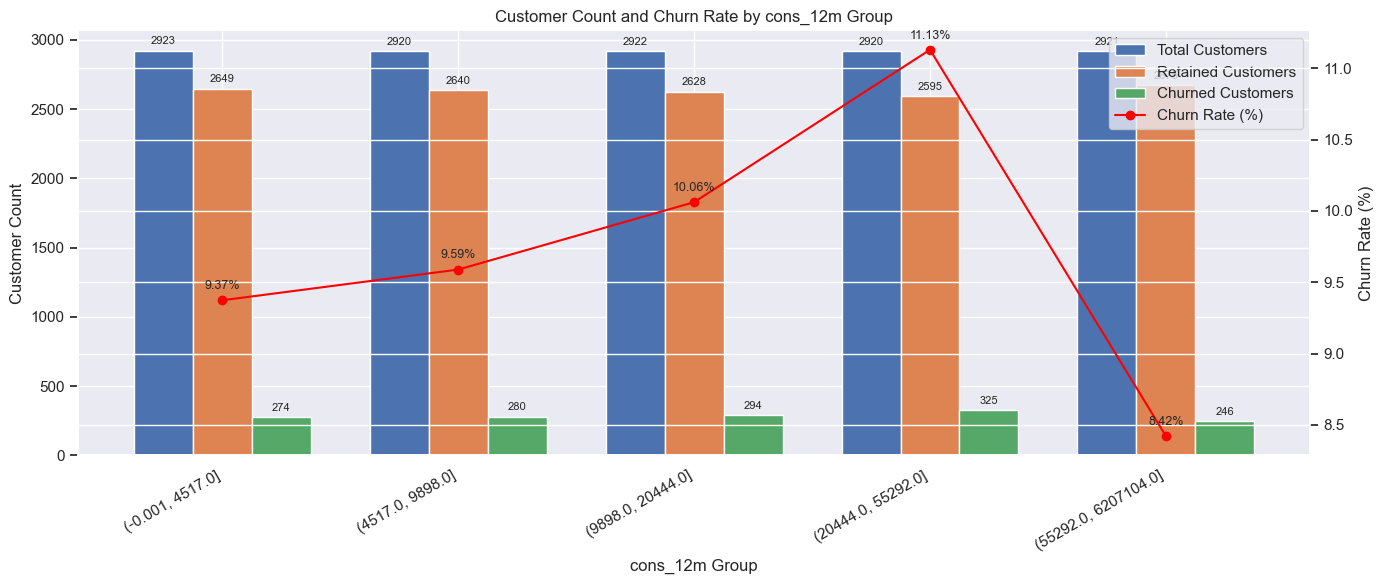

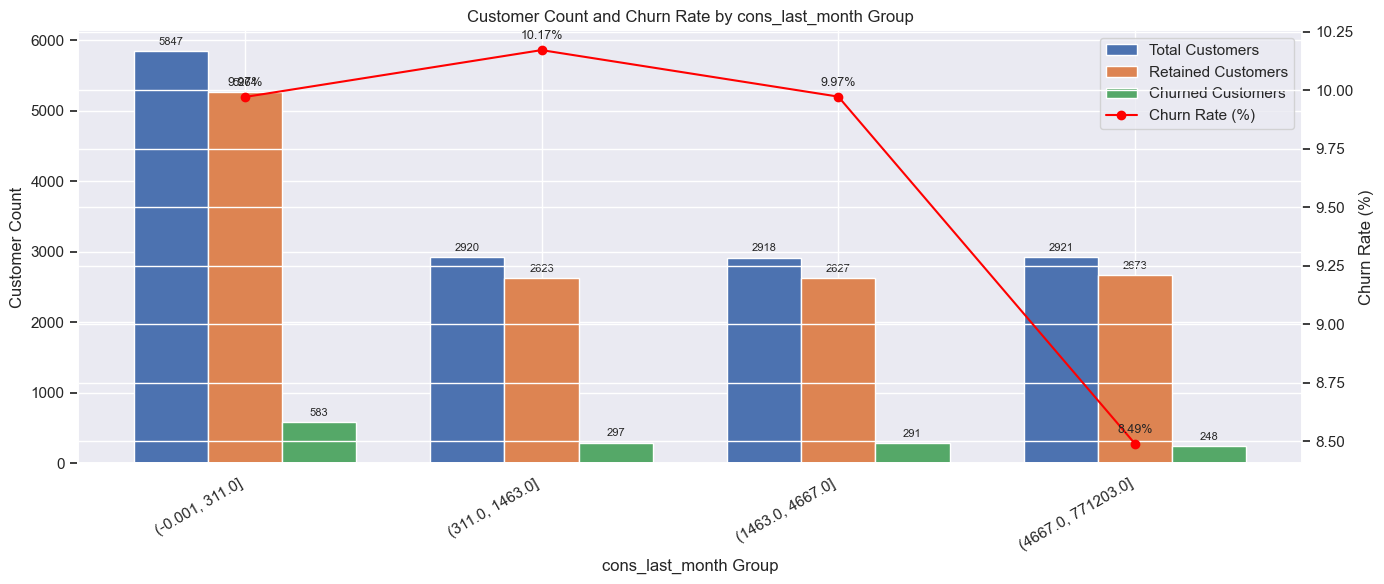

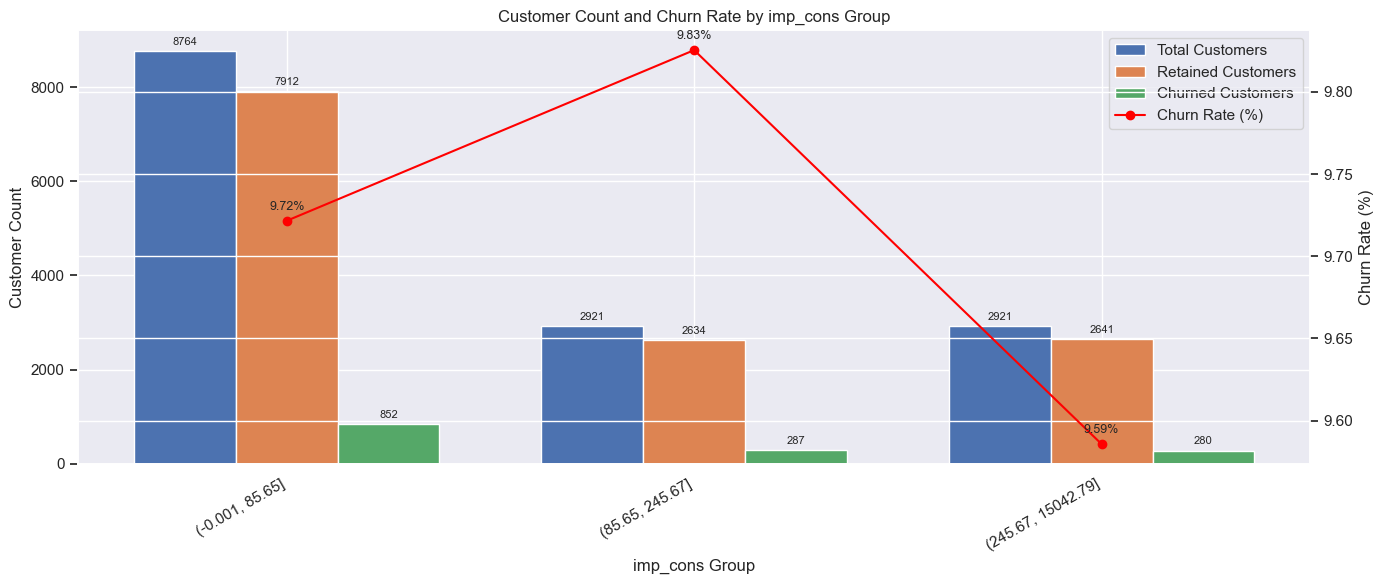

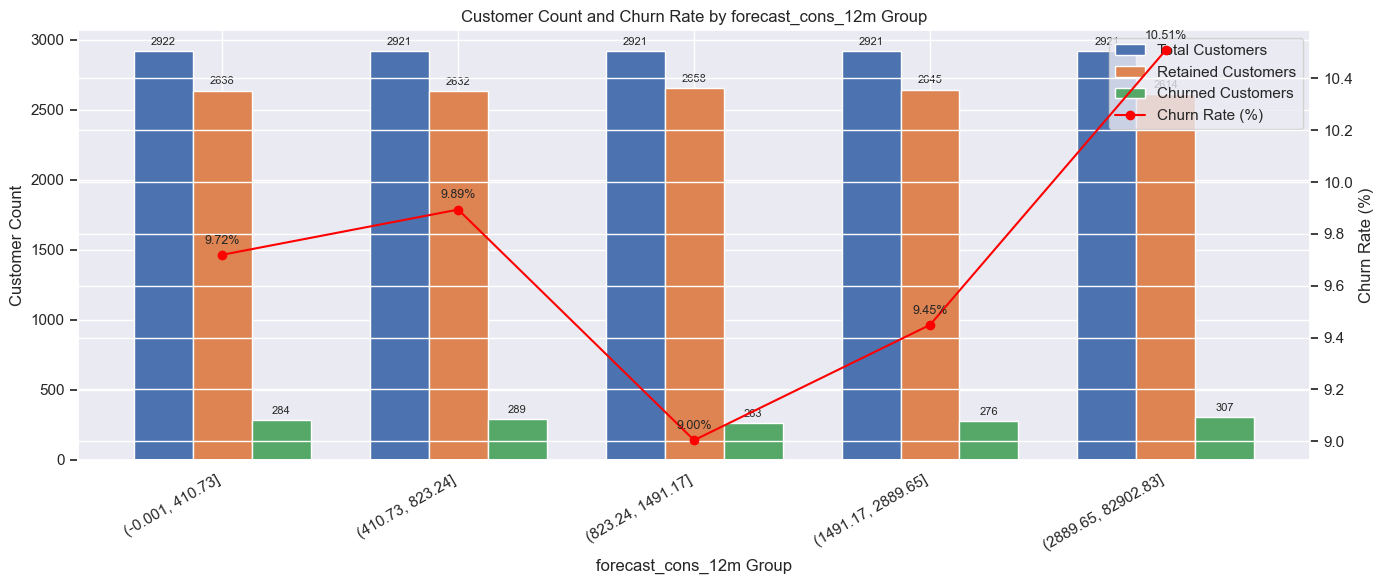

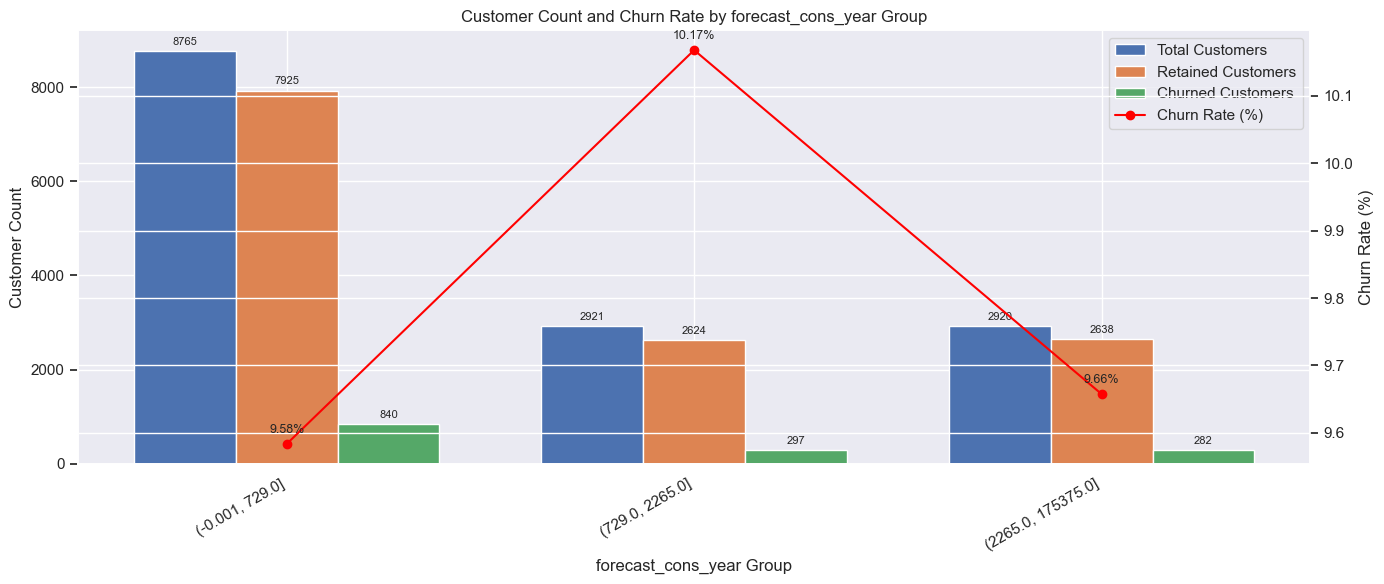

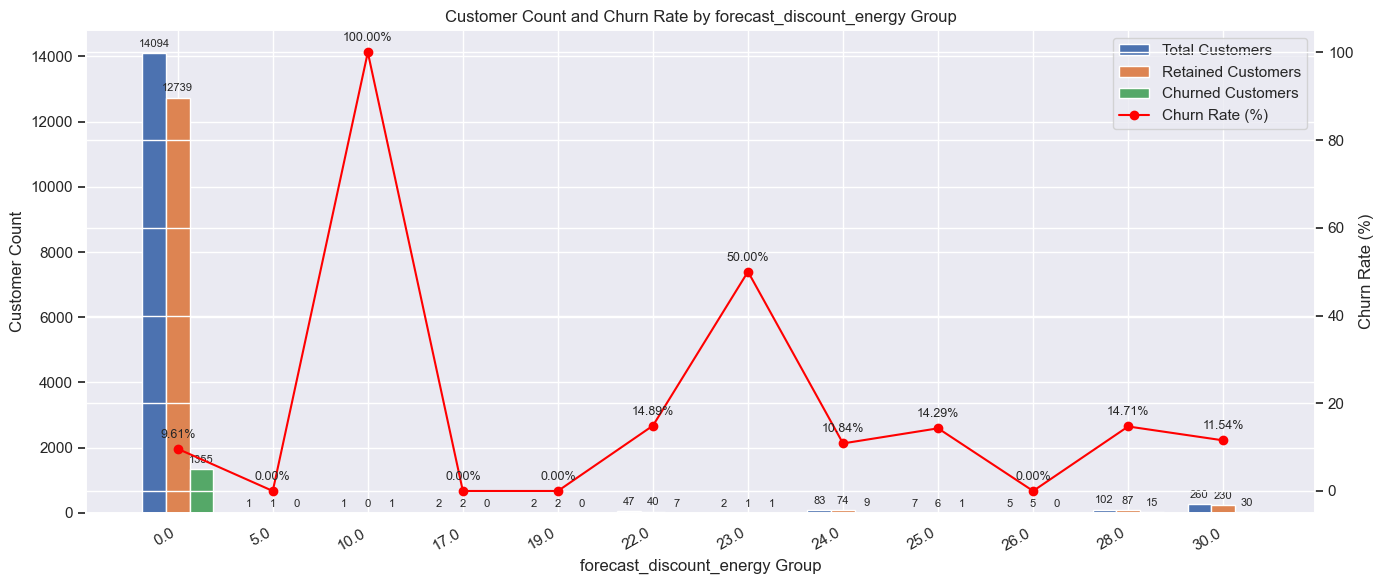

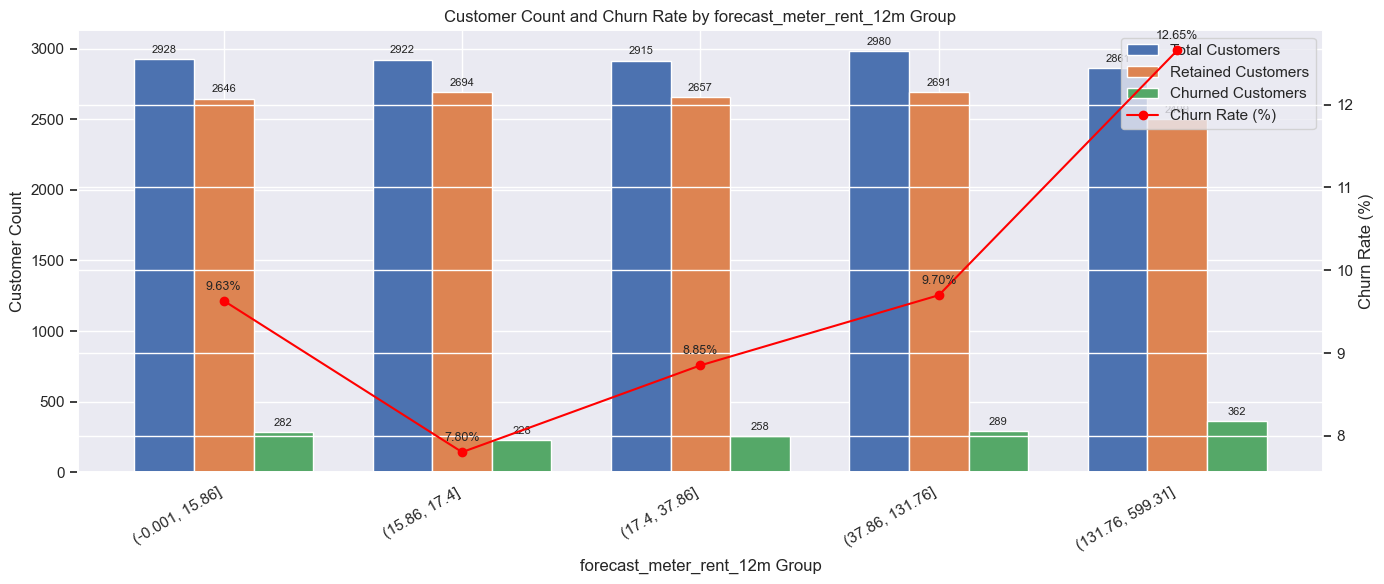

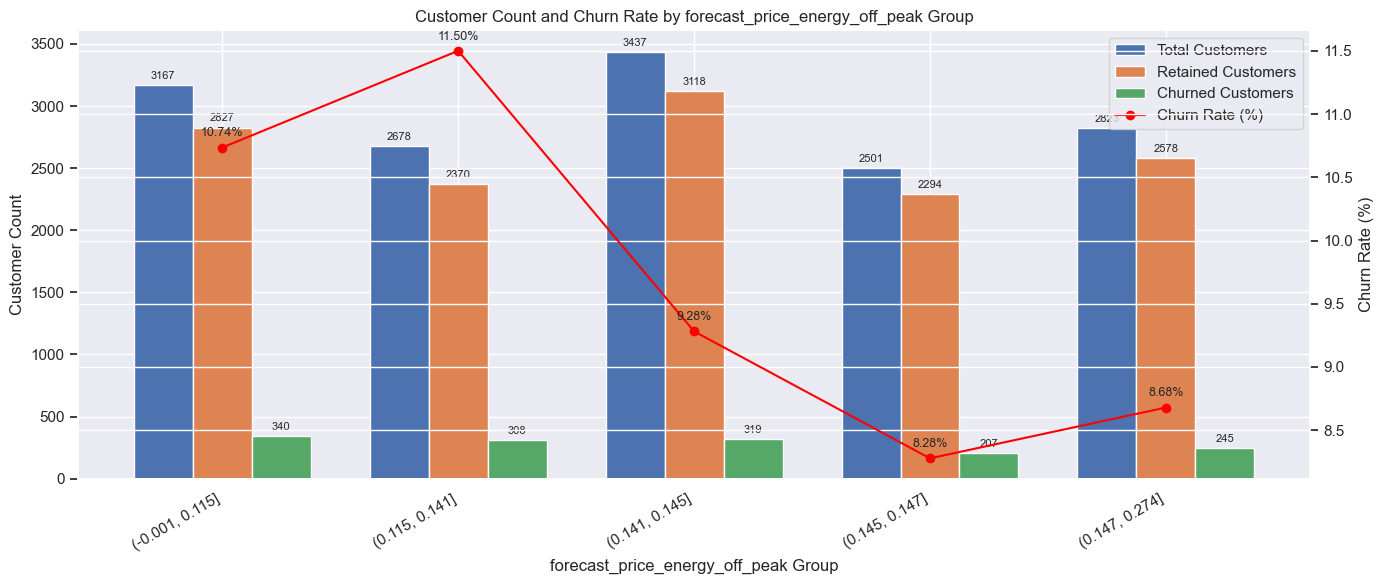

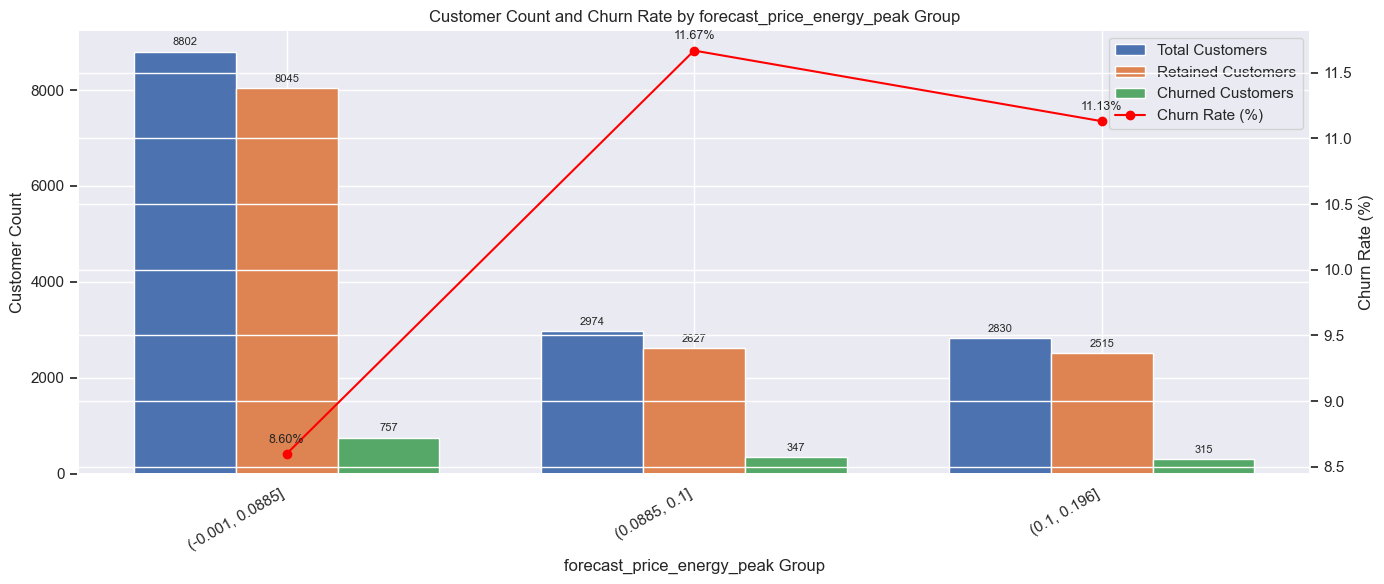

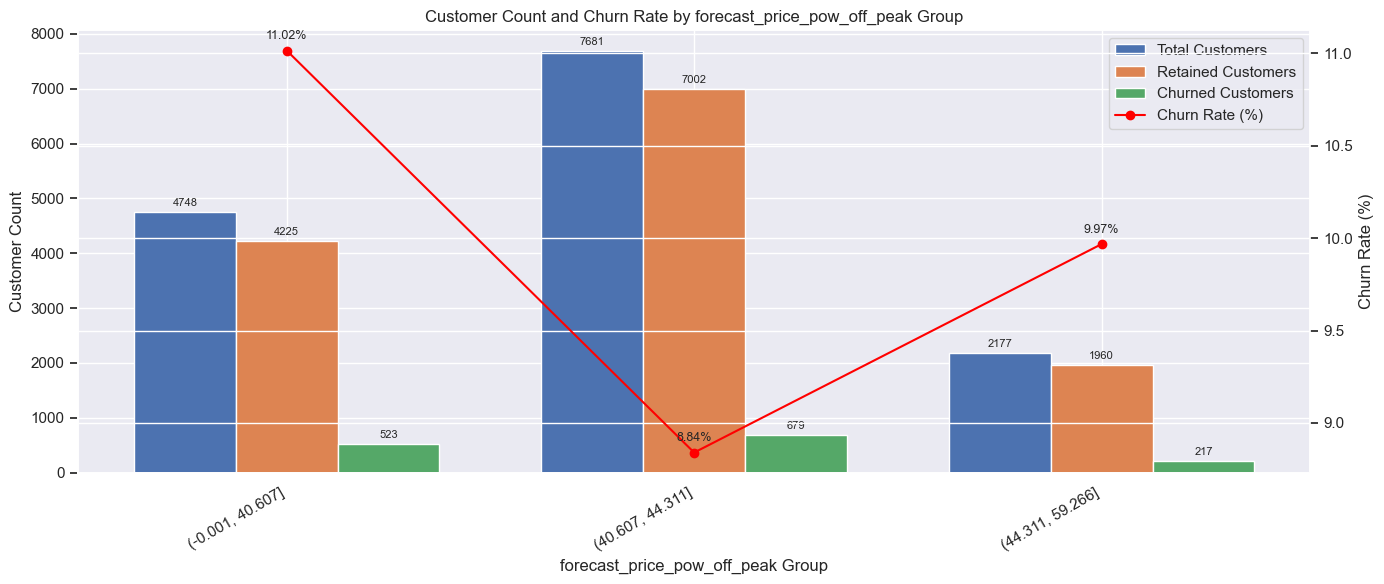

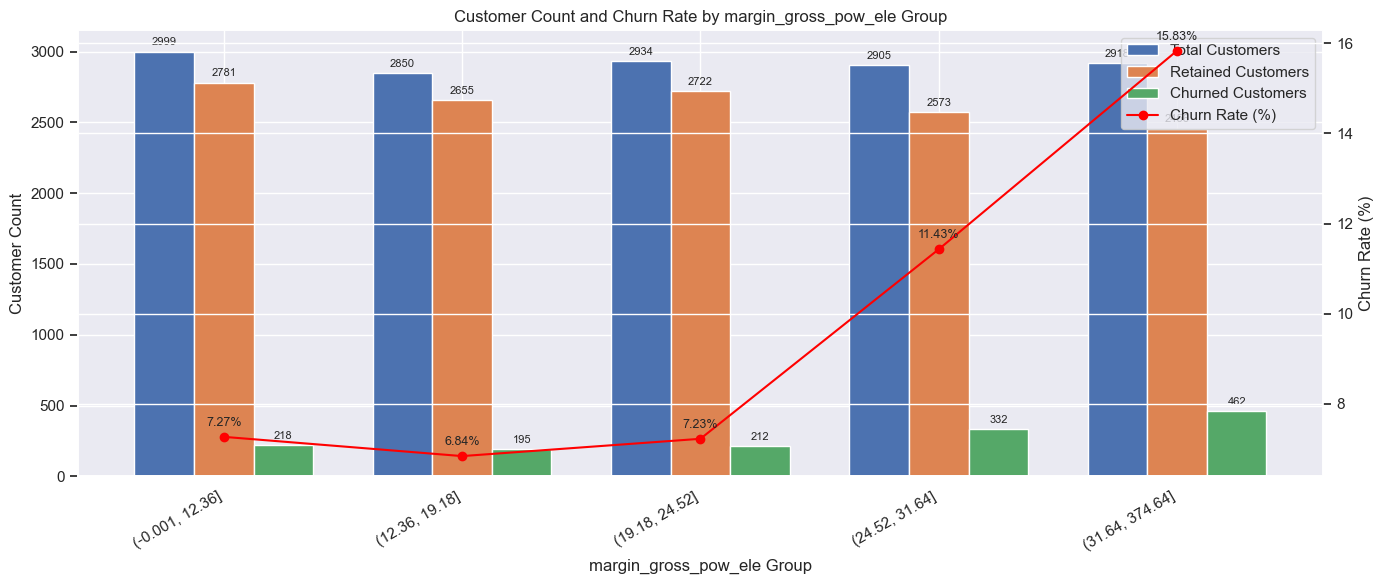

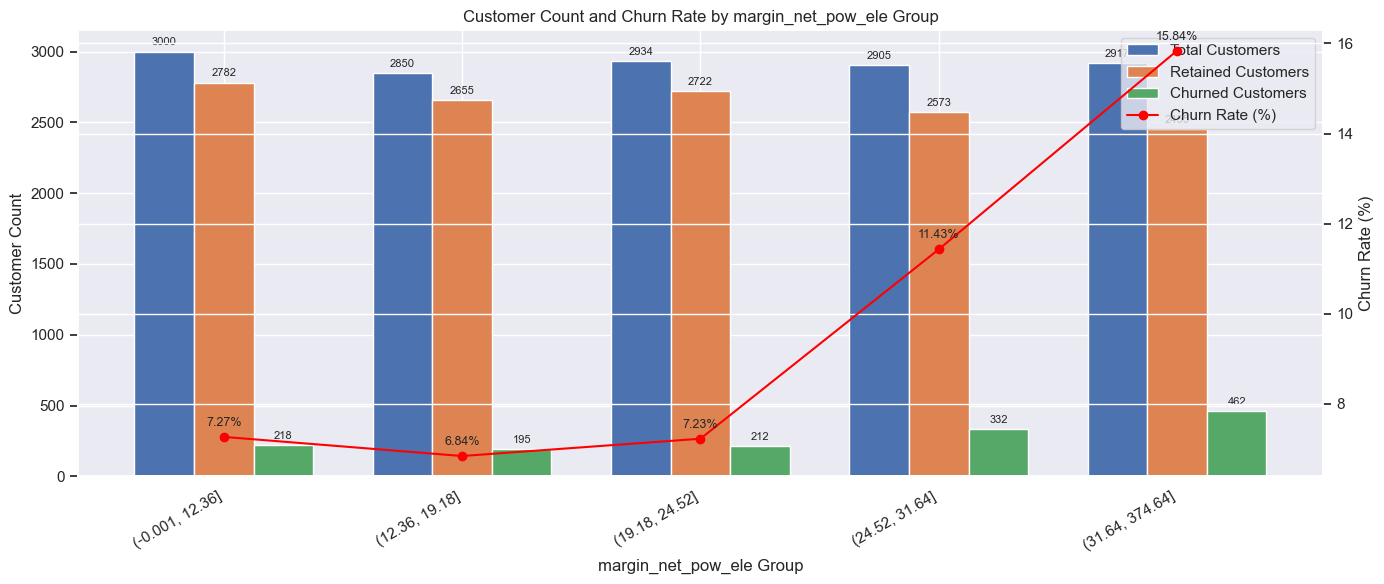

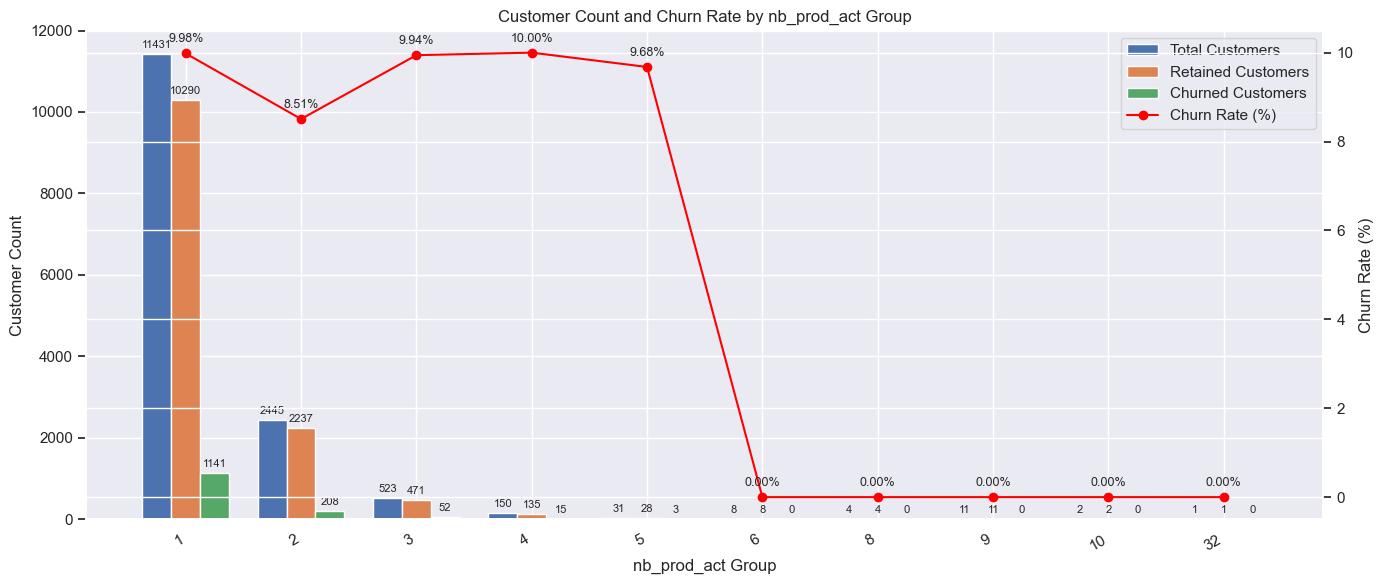

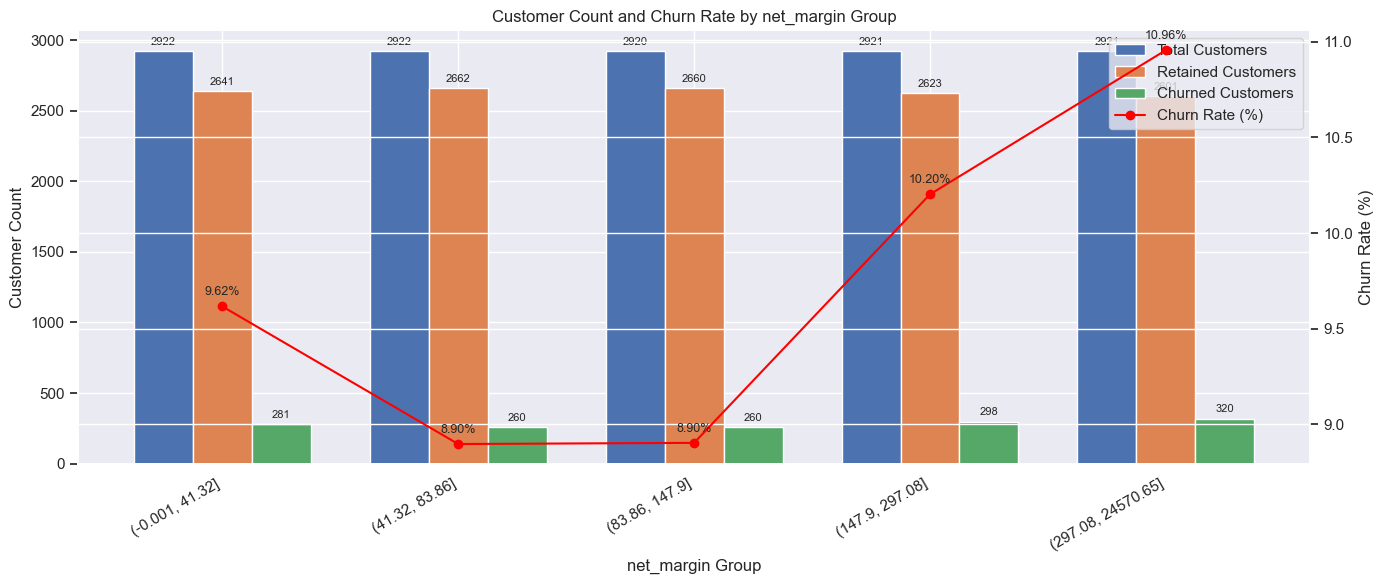

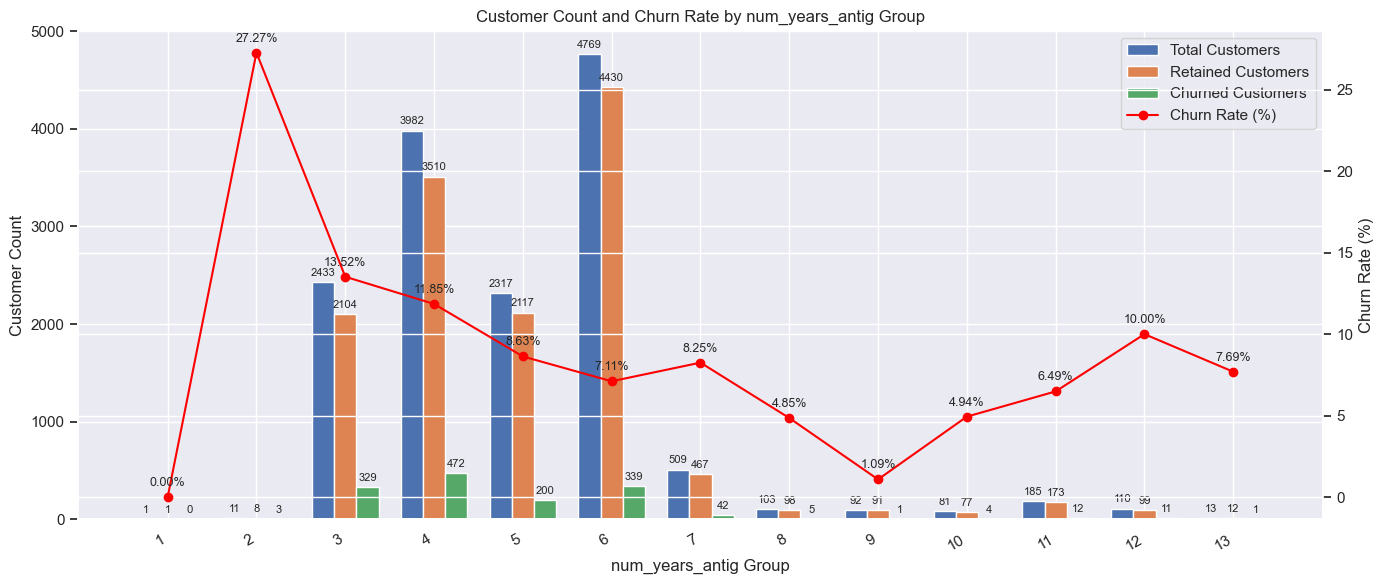

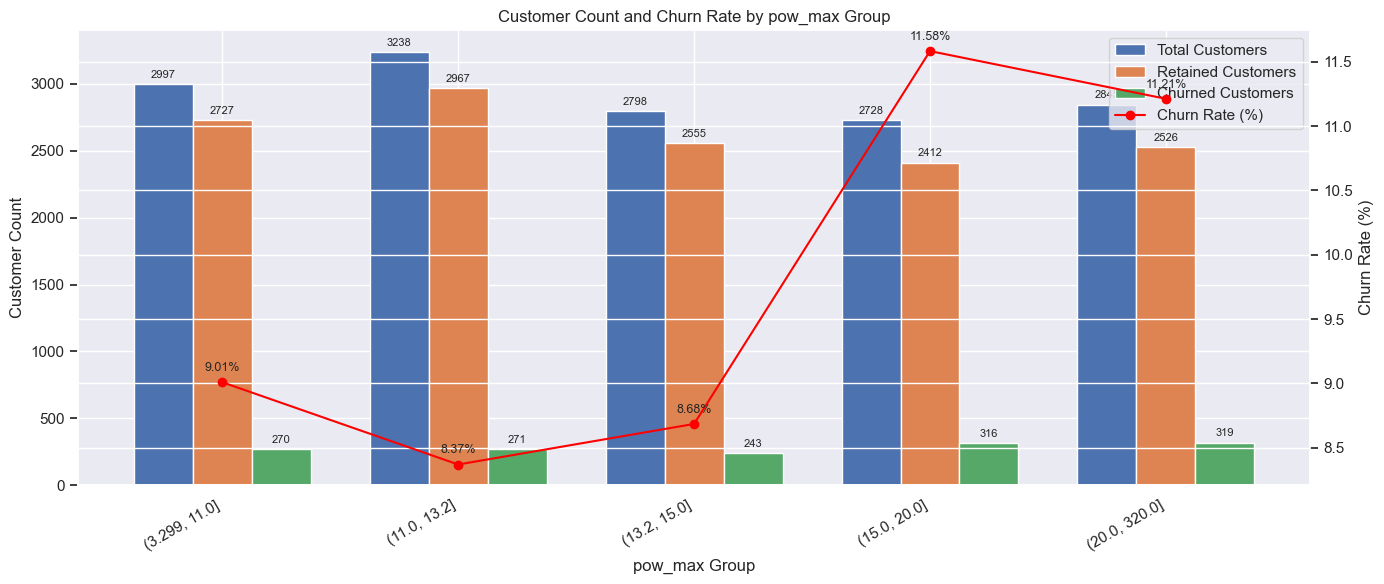

In [88]:
plot_churn_rate(client_df, 'cons_12m', method='qcut')
plot_churn_rate(client_df, 'cons_last_month', method='qcut')
plot_churn_rate(client_df, 'imp_cons', method='qcut')
plot_churn_rate(client_df, 'forecast_cons_12m', method='qcut')
plot_churn_rate(client_df, 'forecast_cons_year', method='qcut')
plot_churn_rate(client_df, 'forecast_discount_energy', method='qcut')
plot_churn_rate(client_df, 'forecast_meter_rent_12m', method='qcut')
plot_churn_rate(client_df, 'forecast_price_energy_off_peak', method='qcut')
plot_churn_rate(client_df, 'forecast_price_energy_peak', method='qcut')
plot_churn_rate(client_df, 'forecast_price_pow_off_peak', method='qcut')
plot_churn_rate(client_df, 'margin_gross_pow_ele', method='qcut')
plot_churn_rate(client_df, 'margin_net_pow_ele', method='qcut')
plot_churn_rate(client_df, 'nb_prod_act', method='qcut')
plot_churn_rate(client_df, 'net_margin', method='qcut')
plot_churn_rate(client_df, 'num_years_antig', method='qcut')
plot_churn_rate(client_df, 'pow_max', method='qcut')

**Observation**

**Consumption and Forecast Features**

- `cons_12m` – Churn increases up to the fourth group (11.13%) and then drops, suggesting a non-linear relationship.
- `cons_last_month` – Churn rates are relatively stable but drop in the highest consumption group (8.49%). Zero and low consumption values create an uneven first group.
- `imp_cons` – Churn rates remain similar across all groups (9.59%–9.83%), showing no clear relationship.
- `forecast_cons_12m` – The highest consumption group has the highest churn rate (10.51%), suggesting a possible positive relationship.
- `forecast_cons_year` – Churn rates are relatively similar across groups, showing no clear linear relationship.
- `forecast_discount_energy` – Most customers (14,094) have a zero discount, with a churn rate of 9.61%. Other discount values have very few customers, making their churn rates unreliable for comparison.

**Pricing and Rental Features**

- `forecast_meter_rent_12m` – The highest rental group has the highest churn rate (12.65%).
- `forecast_price_energy_off_peak` – Churn generally decreases as off-peak energy prices increase, suggesting a possible negative relationship.
- `forecast_price_energy_peak` – The second and third groups have higher churn rates (11.67% and 11.13%) than the first group (8.60%).
- `forecast_price_pow_off_peak` – Churn rates fluctuate across groups, showing no clear linear relationship.

**Margin and Customer Features**

- `margin_gross_pow_ele` – Churn increases in higher margin groups, reaching 15.83% in the highest group.
- `margin_net_pow_ele` – Churn also increases in higher margin groups, reaching 15.84% in the highest group.
- `nb_prod_act` – Churn rates are relatively similar across customers with 1–4 active products (approximately 8.51%–10%). Categories with more than 4 products have very few customers, so their churn rates are not reliable.
- `net_margin` – The highest net margin group has the highest churn rate (10.96%).
- `num_years_antig` – Churn generally decreases as customer tenure increases, falling from 13.52% for 3-year customers to 7.11% for 6-year customers. Some variations occur at higher tenure levels, but those groups have fewer customers.
- `pow_max` – Customers in the higher subscribed power groups show higher churn rates (11.58% and 11.21%).

*Note: These observations indicate associations, not causation.*

**Conclusion**

**Most Important Features (EDA-based shortlist):**

1. `num_years_antig`
2. `margin_gross_pow_ele`
3. `margin_net_pow_ele`
4. `forecast_meter_rent_12m`
5. `net_margin`
6. `pow_max`
7. `forecast_price_energy_off_peak`

These features show comparatively noticeable differences in churn rates across their groups, making them useful candidates for feature engineering and model building.

`nb_prod_act` and `forecast_discount_energy` show limited evidence of a strong relationship with churn because their churn rates are relatively similar across well-populated groups, or most observations are concentrated in one category.

**Possible Business Explanations / Hypotheses**

1. `num_years_antig` – Newer customers may have less trust or loyalty towards the company; hence, they may be more likely to churn.
2. `margin_gross_pow_ele` – Customers with higher gross margins may have different pricing arrangements; hence, they may be more likely to churn.
3. `margin_net_pow_ele` – Higher net margins may reflect differences in subscription pricing; hence, these customers may be more likely to churn.
4. `forecast_meter_rent_12m` – Higher meter rental charges may increase customers' bills; hence, they may switch to cheaper providers.
5. `net_margin` – Higher-margin customers may have different consumption or pricing patterns; hence, they may be more likely to churn.
6. `pow_max` – Customers with higher subscribed power may have greater electricity needs and higher expectations; hence, they may switch if their needs are not met.
7. `forecast_price_energy_off_peak` – Customers may consider factors beyond off-peak prices; hence, lower off-peak prices alone may not prevent them from churning.

**Note:** These are possible explanations, not proven reasons for churn. They need further validation through model performance and feature importance analysis.

In [89]:

def churn_rate_by_category(df, column):

    result = (
        df.groupby(column, dropna=False)['churn']
        .agg(['count', 'sum', 'mean'])
        .rename(columns={
            'count': 'total_customers',
            'sum': 'churned_customers'
        })
    )

    result['retained_customers'] = (
        result['total_customers'] - result['churned_customers']
    )

    result['churn_rate'] = result['mean'] * 100

    return result.drop(columns='mean').sort_values(
        'churn_rate', ascending=False
    )


def plot_churn_rate_category(df, column):

    churn_df = churn_rate_by_category(df, column).reset_index()

    x = np.arange(len(churn_df))
    width = 0.25

    fig, ax1 = plt.subplots(figsize=(14, 6))

    bars1 = ax1.bar(
        x - width,
        churn_df['total_customers'],
        width,
        label='Total Customers'
    )

    bars2 = ax1.bar(
        x,
        churn_df['retained_customers'],
        width,
        label='Retained Customers'
    )

    bars3 = ax1.bar(
        x + width,
        churn_df['churned_customers'],
        width,
        label='Churned Customers'
    )

    ax1.bar_label(bars1, fmt='%.0f', padding=3, fontsize=8)
    ax1.bar_label(bars2, fmt='%.0f', padding=3, fontsize=8)
    ax1.bar_label(bars3, fmt='%.0f', padding=3, fontsize=8)

    ax1.set_xlabel(column)
    ax1.set_ylabel('Customer Count')
    ax1.set_xticks(x)
    ax1.set_xticklabels(
        churn_df[column].astype(str),
        rotation=30,
        ha='right'
    )

    ax2 = ax1.twinx()

    ax2.plot(
        x,
        churn_df['churn_rate'],
        marker='o',
        color='red',
        label='Churn Rate (%)'
    )

    for i, value in enumerate(churn_df['churn_rate']):
        ax2.annotate(
            f'{value:.2f}%',
            (x[i], value),
            textcoords='offset points',
            xytext=(0, 8),
            ha='center',
            fontsize=9
        )

    ax2.set_ylabel('Churn Rate (%)')

    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()

    ax1.legend(h1 + h2, l1 + l2, loc='upper right')

    plt.title(f'Customer Count and Churn Rate by {column}')
    plt.tight_layout()
    plt.show()


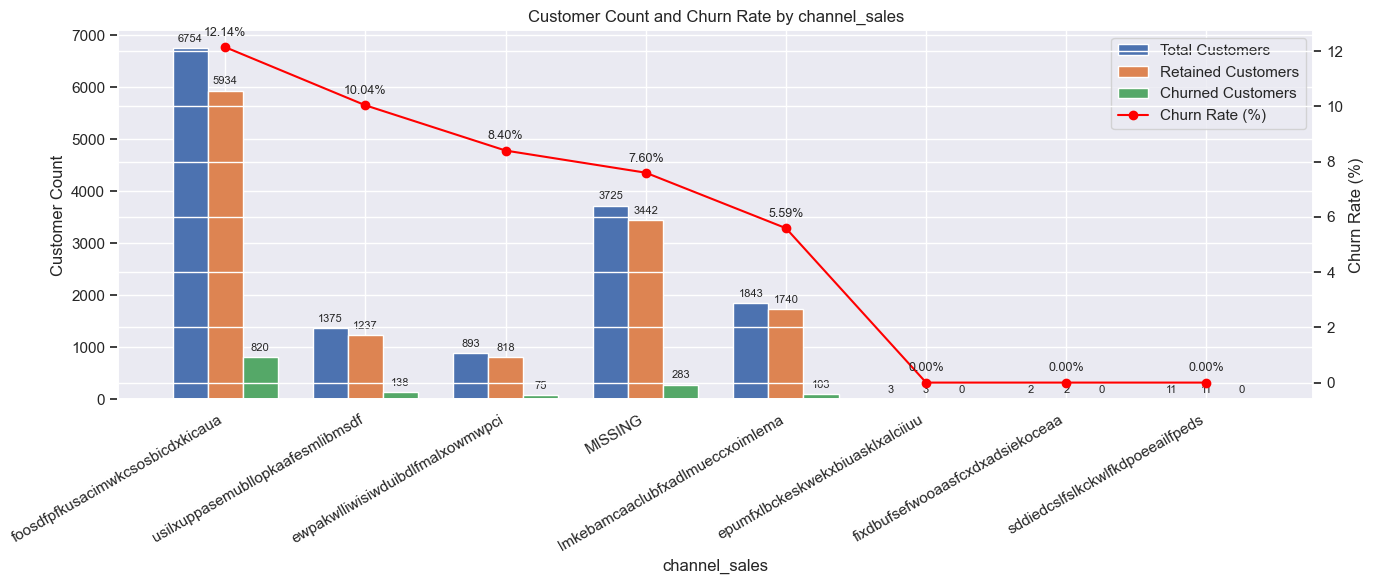

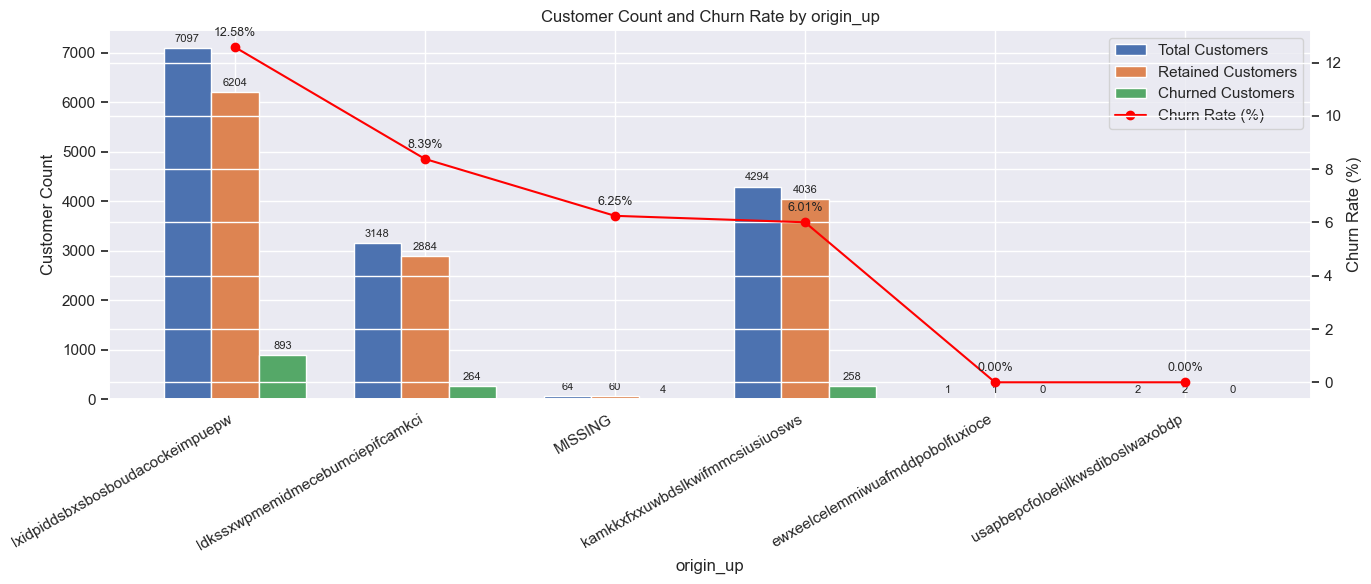

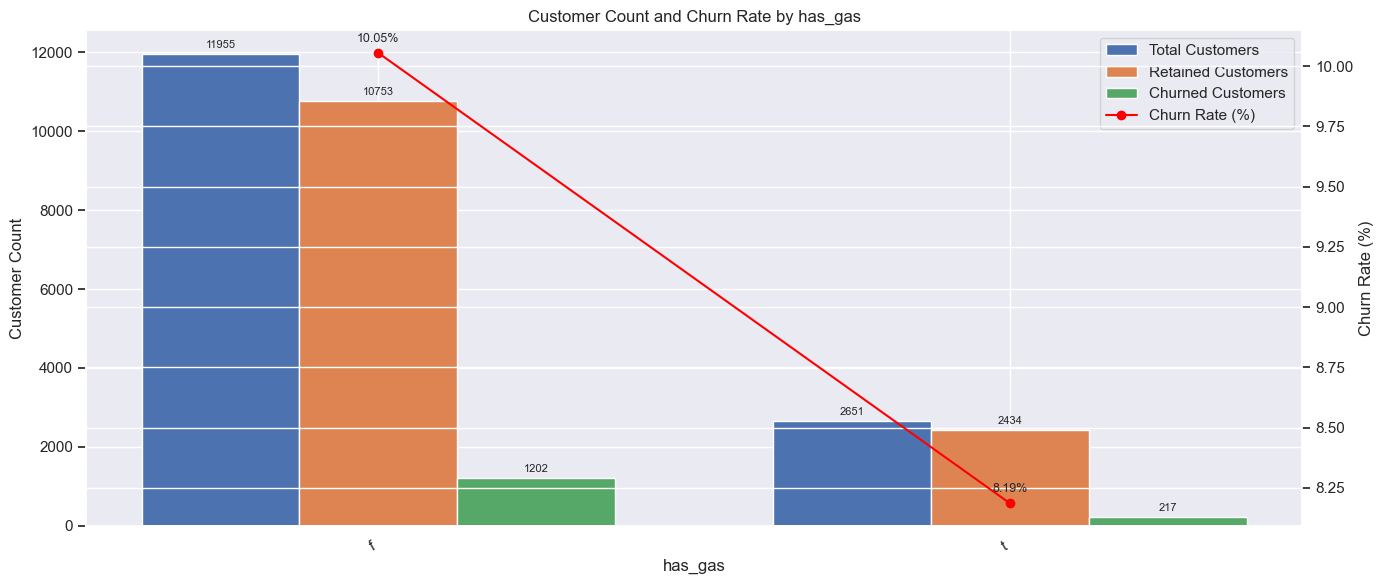

In [90]:
plot_churn_rate_category(client_df, 'channel_sales')
plot_churn_rate_category(client_df, 'origin_up')
plot_churn_rate_category(client_df, 'has_gas')

In [91]:
def plot_activation_analysis(df, date_col, period='year'):

    df = df.copy()

    # Extract year or month
    if period == 'year':
        df['period'] = df[date_col].dt.year
        xlabel = 'Activation Year'
    else:
        df['period'] = df[date_col].dt.month
        xlabel = 'Activation Month'

    # Calculate total, retained and churned customers
    summary = df.groupby('period').agg(
        Total_Customers=('id', 'count'),
        Churned_Customers=('churn', 'sum')
    )

    summary['Retention_Customers'] = (
        summary['Total_Customers'] - summary['Churned_Customers']
    )

    # Calculate percentages
    summary['Retention_Rate'] = (
        summary['Retention_Customers'] /
        summary['Total_Customers'] * 100
    )

    summary['Churn_Rate'] = (
        summary['Churned_Customers'] /
        summary['Total_Customers'] * 100
    )

    # -------------------------------
    # Graph 1: Grouped Bar Chart
    # -------------------------------

    ax = summary[
        ['Total_Customers', 'Retention_Customers', 'Churned_Customers']
    ].plot(
        kind='bar',
        figsize=(14, 6),
        width=0.8,
        title=f'Customer Activation, Retention and Churn by {period.title()}'
    )

    for container in ax.containers:
        ax.bar_label(container, padding=3, fontsize=8)

    ax.set_xlabel(xlabel)
    ax.set_ylabel('Number of Customers')
    plt.xticks(rotation=45)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

    # -------------------------------
    # Graph 2: Line Chart
    # -------------------------------

    fig, ax1 = plt.subplots(figsize=(14, 6))

    ax1.plot(
        summary.index, summary['Retention_Rate'],
        marker='o', label='Retention Rate (%)'
    )

    ax1.plot(
        summary.index, summary['Churn_Rate'],
        marker='o', label='Churn Rate (%)'
    )

    ax1.set_xlabel(xlabel)
    ax1.set_ylabel('Percentage (%)')
    ax1.set_ylim(0, 110)

    # Secondary axis for activation counts
    ax2 = ax1.twinx()

    ax2.plot(
        summary.index, summary['Total_Customers'],
        marker='s', linestyle='--', label='Total Activations'
    )

    ax2.set_ylabel('Number of Activations')

    # Combine legends
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc='best'
    )

    ax1.set_title(
        f'Customer Activation, Retention and Churn by {period.title()}'
    )

    plt.xticks(summary.index, rotation=45)
    plt.tight_layout()
    plt.show()

    return summary


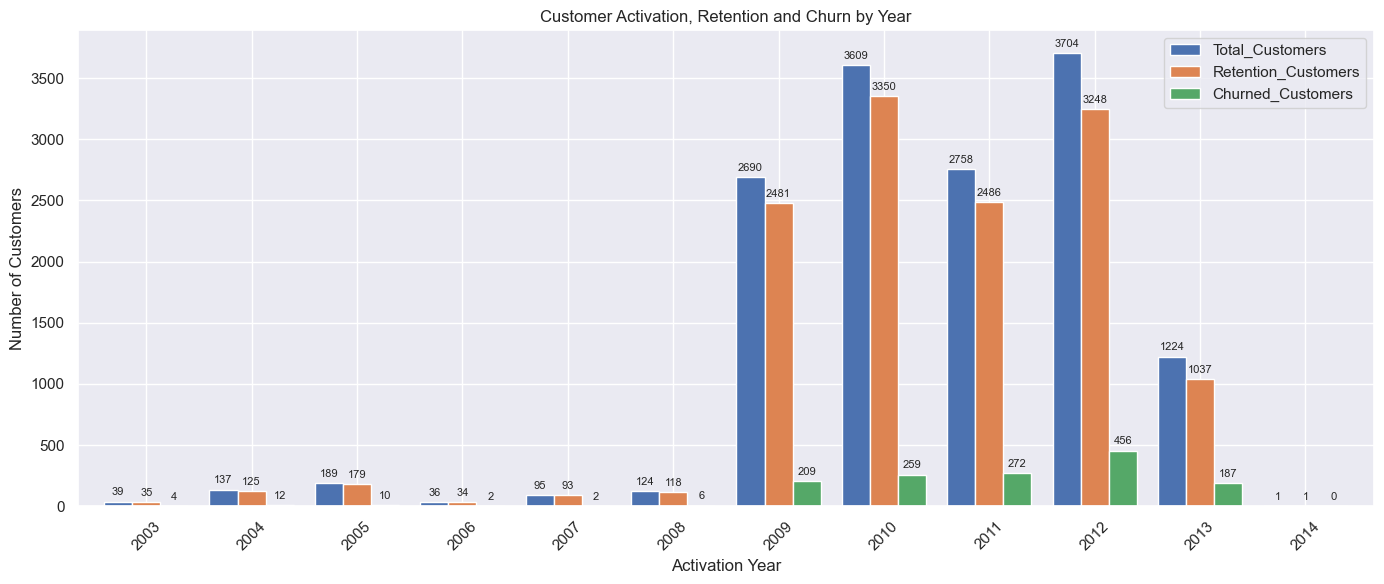

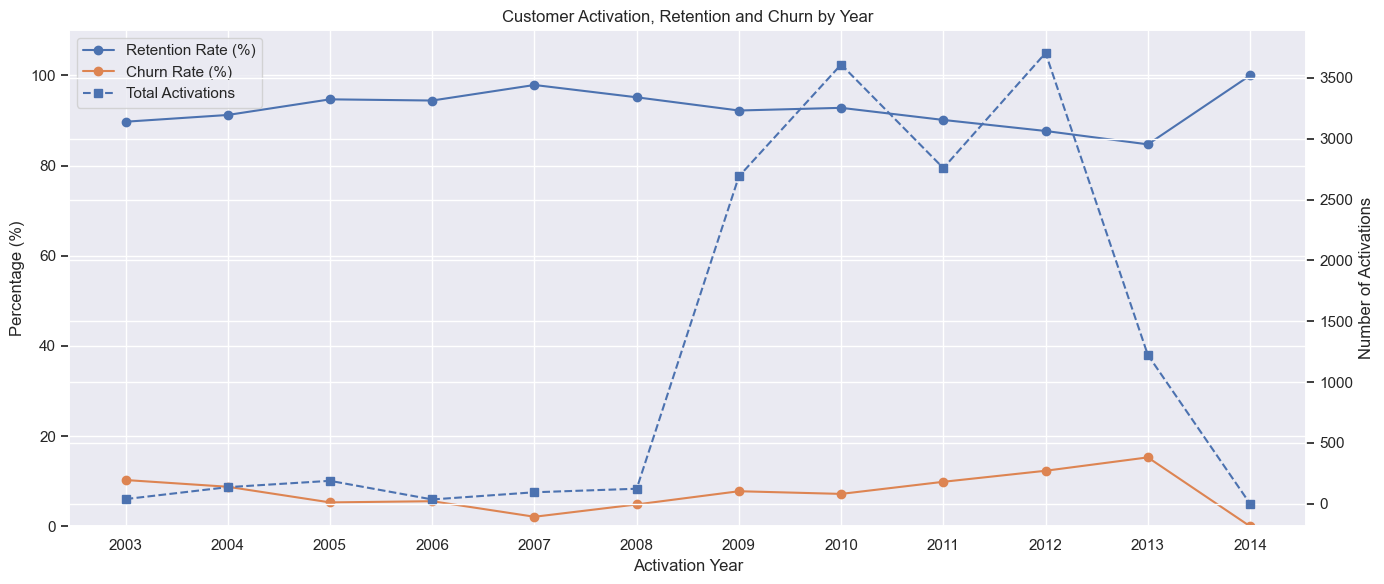

In [92]:
yearly_summary = plot_activation_analysis(
    client_df,
    'date_activ',
    period='year'
)

**Observations**

1st graph shows the total, retained and churned customers by activation year.

- Most customers joined between 2009 and 2012.
- 2012 had the highest customer activations (3,704) and churn cases (456).
- Most customers were retained across all activation years.
- Customer activations dropped significantly after 2012.
- The 2009–2012 groups account for the majority of customers and churn cases.

2nd graph shows the relationship between customer activations, retention and churn across different activation years.

- **2003–2007:** Retention increased while churn decreased. However, customer activations remained relatively low during this period.
- **2008–2012:** Customer activations increased significantly, but retention generally declined and churn started increasing.
- **2013:** This was the most concerning year, with a sharp drop in customer activations, the lowest retention rate (84.72%) and the highest churn rate (15.28%).

**Conclusion:** Customer acquisition increased significantly between 2009 and 2012, but retention gradually declined and churn rates generally increased between 2009 and 2013. Although churn counts peaked in 2012, the 2013 customer group had the highest churn rate (15.28%) and lowest retention (84.72%), indicating weaker retention performance among customers acquired in that year.

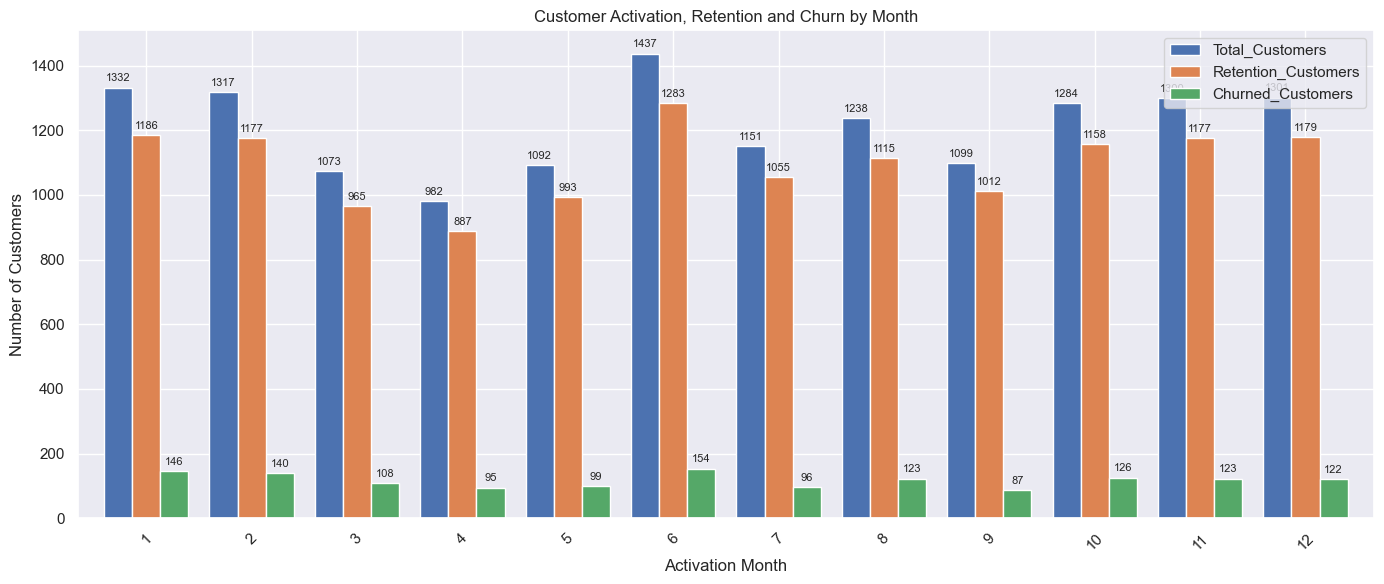

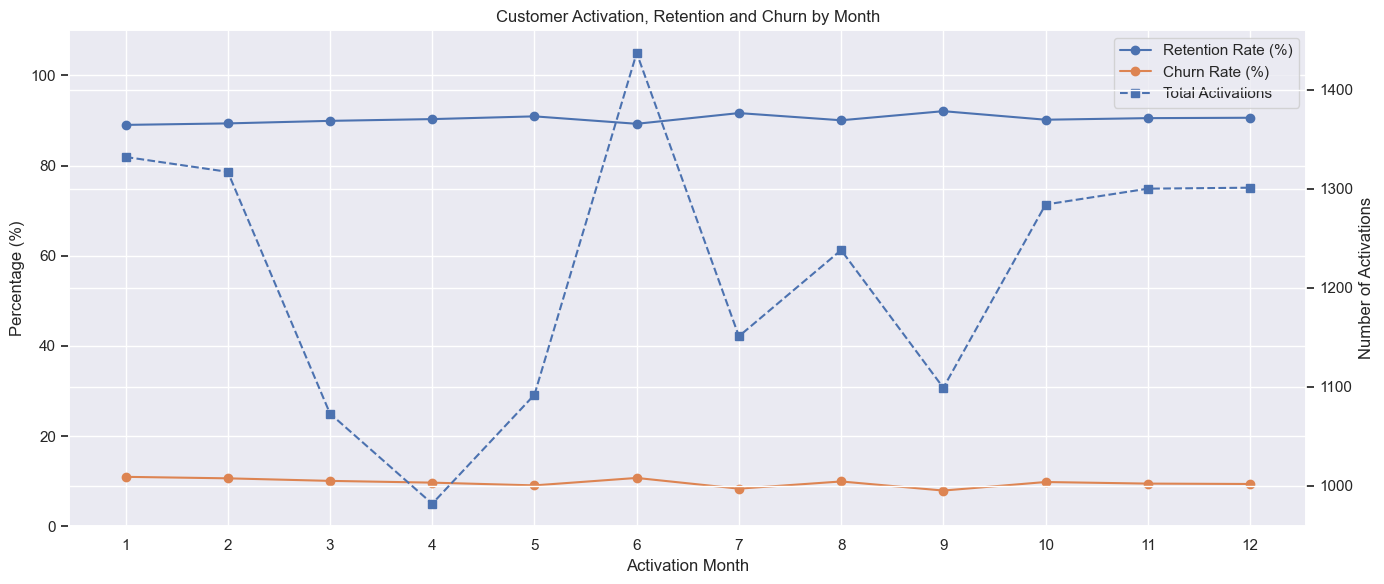

In [93]:
monthly_summary = plot_activation_analysis(
    client_df,
    'date_activ',
    period='month'
)

**Observations**

**1st graph shows** the total, retained and churned customers by activation month.

- June recorded the highest customer activations (1,437), followed by January (1,332).
- April had the lowest customer activations (982).
- Most customers were retained across all 12 months.
- June recorded the highest number of churn cases (154), while September had the lowest (87).
- Customer activations and churn cases vary across months, with no consistent upward or downward pattern.

**2nd graph shows** the relationship between customer activations, retention and churn across different activation months.

- **January–May:** Retention gradually increased while churn decreased.
- **June:** Activations reached their highest level, while retention dropped and churn increased.
- **July–September:** Retention generally improved, and churn decreased, reaching its lowest level in September.
- **October–December:** Retention and churn remained relatively stable, with small fluctuations in activation numbers.

**Conclusion:** Retention and churn rates remain relatively stable throughout the year(analysis month wise), mostly around 89–92% and 8–11%, respectively. June shows higher customer acquisition along with higher churn, whereas September shows the strongest retention performance.

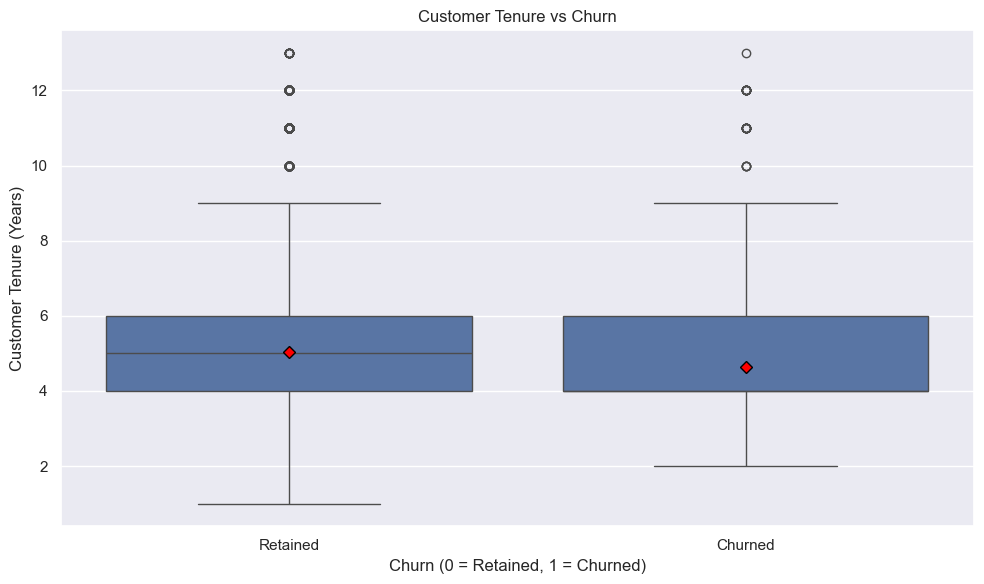

In [94]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=client_df,
    x='churn',
    y='num_years_antig',
    showmeans=True,
    meanprops={
        'marker': 'D',
        'markerfacecolor': 'red',
        'markeredgecolor': 'black'
    }
)

plt.title('Customer Tenure vs Churn')
plt.xlabel('Churn (0 = Retained, 1 = Churned)')
plt.ylabel('Customer Tenure (Years)')
plt.xticks([0, 1], ['Retained', 'Churned'])

plt.tight_layout()
plt.show()

**Observations:**

- Retained customers have a higher median tenure (5 years) than churned customers (4 years).
- The average tenure (red diamond) is also higher for retained customers (approximately 5 years) compared to churned customers (approximately 4.6 years).
- Retained customers generally stay with the company longer than churned customers. This suggests that customers with shorter tenure are slightly more likely to leave.
- Most customers in both groups have a tenure between 4 and 6 years.
- Churned customers tend to have slightly shorter tenure than retained customers.
- Both groups have a similar tenure distribution, indicating that tenure alone may not fully explain customer churn.

**Conclusion:** Customers with longer tenure tend to stay with the company, while customers with shorter tenure may be slightly more likely to churn.

In [95]:
date_cols = ['date_activ', 'date_modif_prod']

for col in date_cols:
    client_df[col] = pd.to_datetime(
        client_df[col], dayfirst=True, errors='coerce'
    )

client_df['modification_delay_days'] = (
    client_df['date_modif_prod'] - client_df['date_activ']
).dt.days

client_df['modification_delay_years'] = (
    client_df['modification_delay_days'] / 365.25
)

client_df['modification_delay_years'].describe()

count    14606.000000
mean         1.930707
std          2.311239
min         -0.156057
25%          0.000000
50%          0.087611
75%          3.827515
max         11.956194
Name: modification_delay_years, dtype: float64

In [96]:
client_df['modification_group'] = pd.cut(
    client_df['modification_delay_years'],
    bins=[-1, 0, 1, 2, 3, 5, float('inf')],
    labels=['Same Date', 'Within 1 Year', '1-2 Years',
            '2-3 Years', '3-5 Years', 'Above 5 Years']
)

modification_churn = (
    client_df.groupby('modification_group', observed=True)['churn']
    .agg(['count', 'sum', 'mean'])
)

modification_churn['churn_rate'] = modification_churn['mean'] * 100

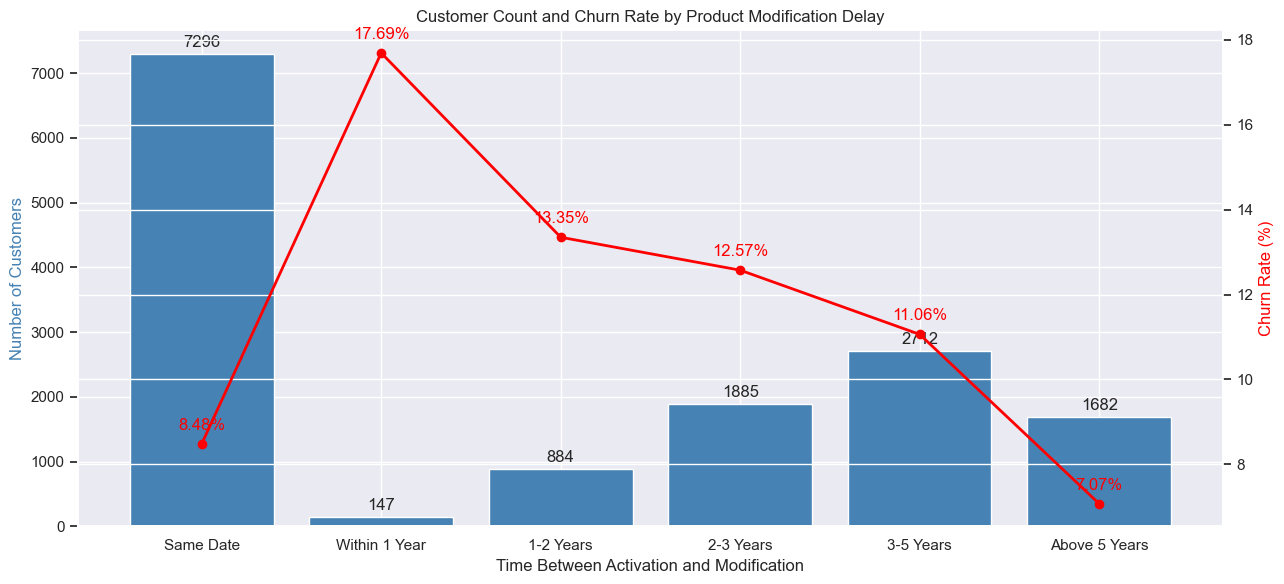

In [97]:
fig, ax1 = plt.subplots(figsize=(13, 6))

plot_data = modification_churn.reset_index()

# Customer count bars
ax1.bar(
    plot_data['modification_group'].astype(str),
    plot_data['count'],
    color='steelblue',
    label='Customers'
)

ax1.set_xlabel('Time Between Activation and Modification')
ax1.set_ylabel('Number of Customers', color='steelblue')
ax1.bar_label(ax1.containers[0], padding=3, fmt='%d')

# Churn rate line on secondary axis
ax2 = ax1.twinx()

ax2.plot(
    plot_data['modification_group'].astype(str),
    plot_data['churn_rate'],
    color='red',
    marker='o',
    linewidth=2,
    label='Churn Rate'
)

ax2.set_ylabel('Churn Rate (%)', color='red')

for i, value in enumerate(plot_data['churn_rate']):
    ax2.annotate(
        f'{value:.2f}%',
        (i, value),
        xytext=(0, 10),
        textcoords='offset points',
        ha='center',
        color='red'
    )

plt.title('Customer Count and Churn Rate by Product Modification Delay')
fig.tight_layout()
plt.show()

**Observations:**

**What the graph shows:**

- **Blue bars:** Number of customers in each product modification tenure group (time between activation and modification).
- **Red line:** Churn rate (%) for each modification tenure group.

* The Same Date group has the highest number of customers (7,296), with a churn rate of 8.48%.
* Customers whose products were modified within 1 year have the highest churn rate (17.69%), but this group contains only 147 customers.
* As the time between product activation and modification increases, the churn rate generally decreases, while the number of customers increases in some groups.
* Customers whose products were modified after 5 years have the lowest churn rate (7.07%).

**Conclusion:** Early product modification (within 1 year) is associated with a higher churn rate. Customers whose products are modified later generally show lower churn rates, suggesting they may be more likely to stay with the company.


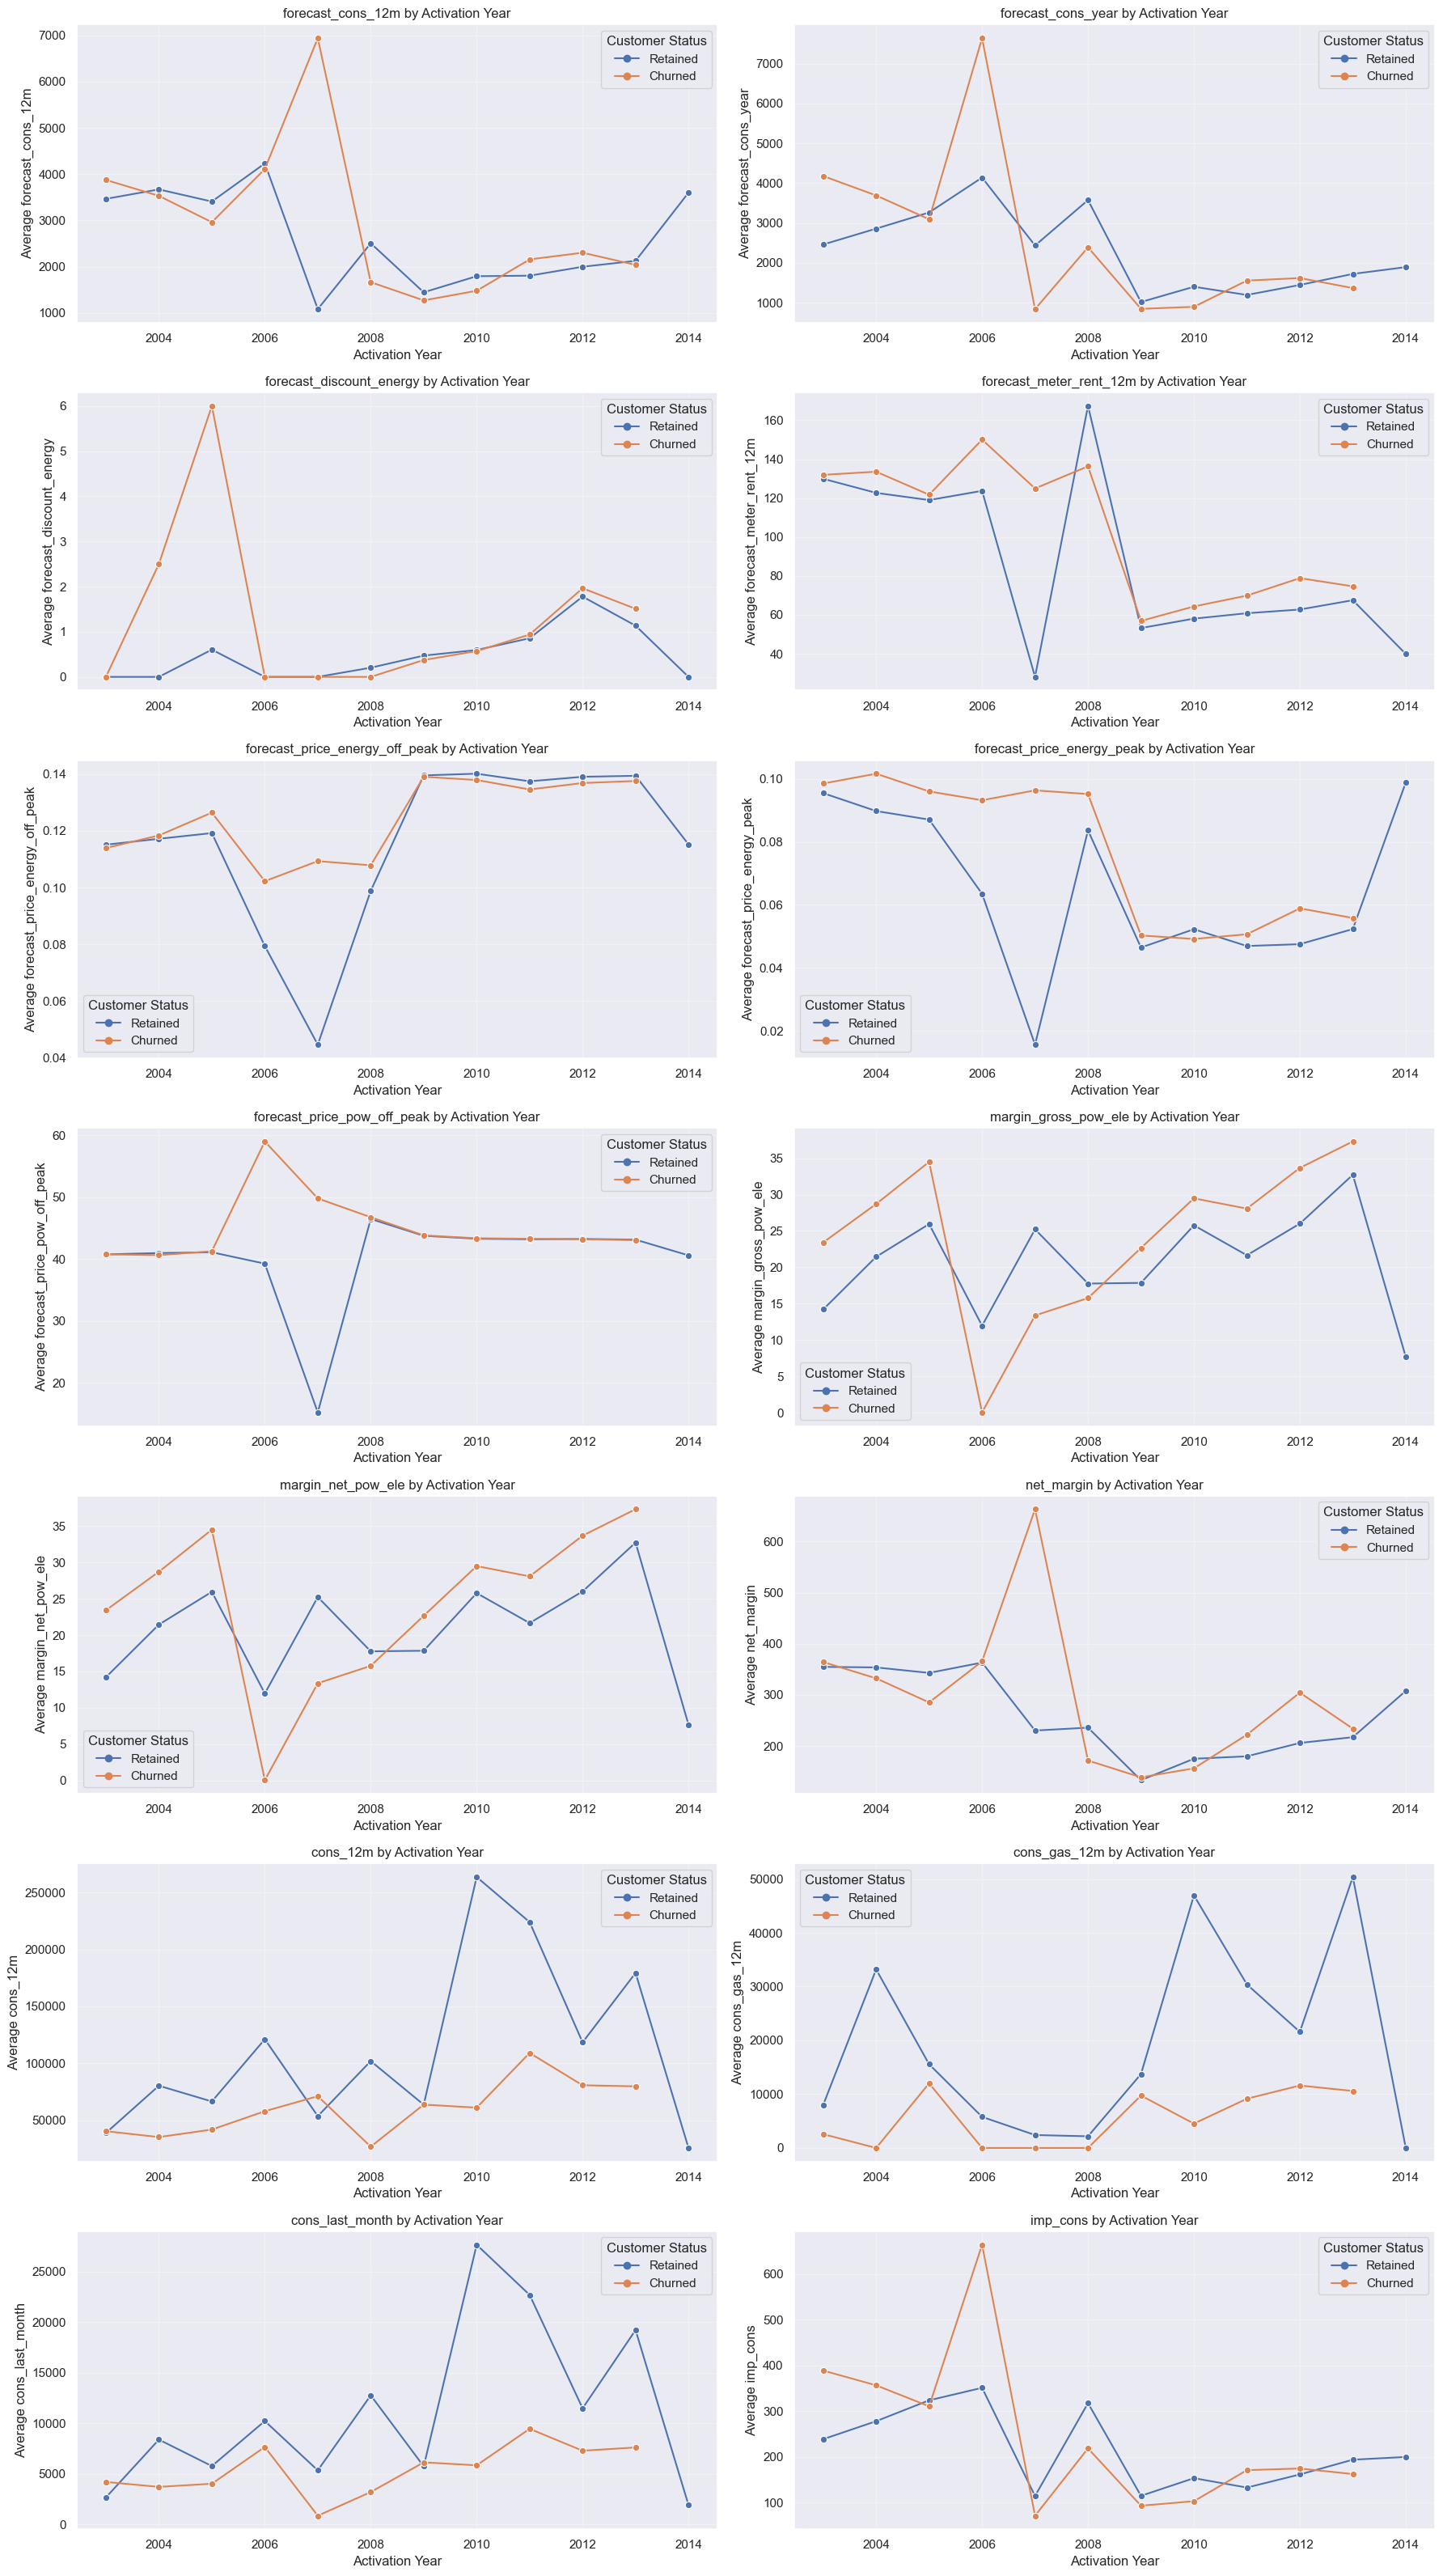

In [98]:

# All numerical features
plot_cols = [
    'forecast_cons_12m',
    'forecast_cons_year',
    'forecast_discount_energy',
    'forecast_meter_rent_12m',
    'forecast_price_energy_off_peak',
    'forecast_price_energy_peak',
    'forecast_price_pow_off_peak',
    'margin_gross_pow_ele',
    'margin_net_pow_ele',
    'net_margin',
    'cons_12m',
    'cons_gas_12m',
    'cons_last_month',
    'imp_cons'
]

client_df['activation_year'] = client_df['date_activ'].dt.year

# Group by activation year and churn status
yearly_data = (
    client_df.groupby(['activation_year', 'churn'])[plot_cols]
    .mean()
    .reset_index()
)

# Create subplots
fig, axes = plt.subplots(7, 2, figsize=(18, 32))
axes = axes.flatten()

# Plot each feature
for i, col in enumerate(plot_cols):

    sns.lineplot(
        data=yearly_data,
        x='activation_year',
        y=col,
        hue='churn',
        hue_order=[0, 1],
        marker='o',
        ax=axes[i],
        legend=False
    )

    axes[i].set_title(f'{col} by Activation Year')
    axes[i].set_xlabel('Activation Year')
    axes[i].set_ylabel(f'Average {col}')

    # Manual line-based legend
    handles = [
        plt.Line2D(
            [0], [0],
            color='C0',
            marker='o',
            linestyle='-',
            label='Retained'
        ),
        plt.Line2D(
            [0], [0],
            color='C1',
            marker='o',
            linestyle='-',
            label='Churned'
        )
    ]

    axes[i].legend(
        handles=handles,
        title='Customer Status'
    )

    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Conclusion:** features show some differences between retained and churned customers, but the patterns are inconsistent across activation years. Therefore, no single forecast feature clearly distinguishes churned customers from retained customers.

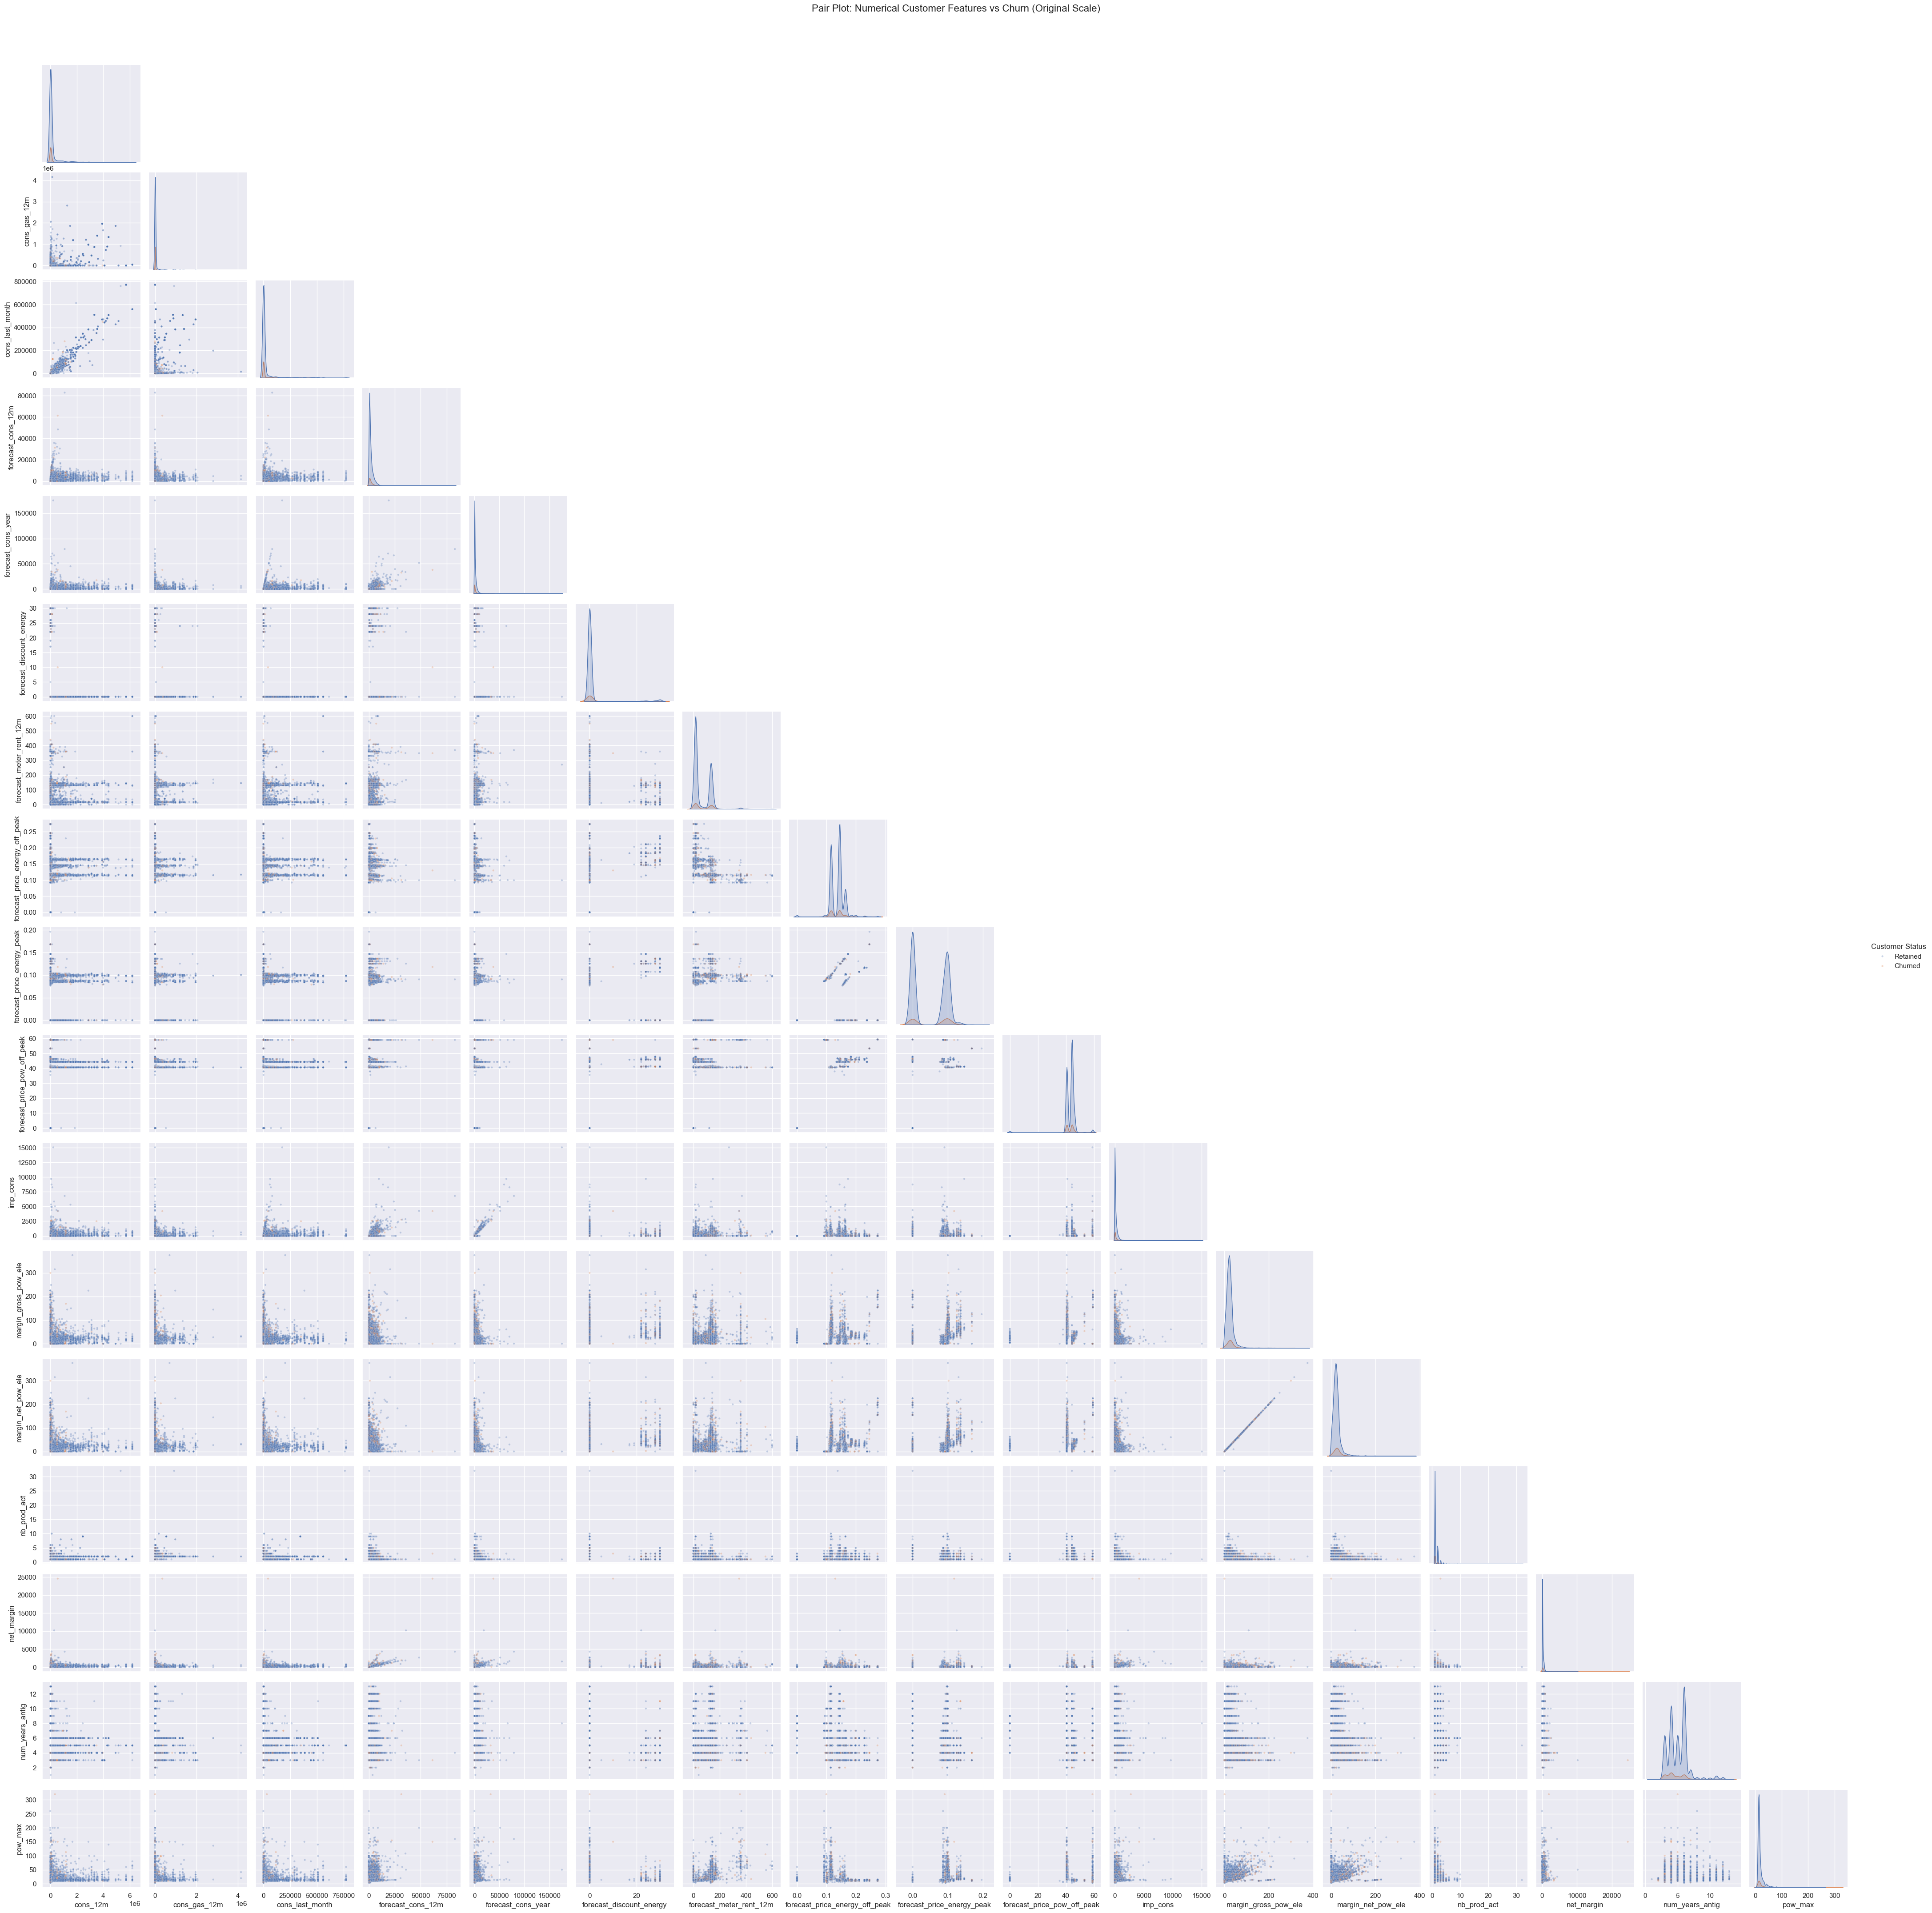

In [99]:

import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical features
pair_cols = [
    'cons_12m',
    'cons_gas_12m',
    'cons_last_month',
    'forecast_cons_12m',
    'forecast_cons_year',
    'forecast_discount_energy',
    'forecast_meter_rent_12m',
    'forecast_price_energy_off_peak',
    'forecast_price_energy_peak',
    'forecast_price_pow_off_peak',
    'imp_cons',
    'margin_gross_pow_ele',
    'margin_net_pow_ele',
    'nb_prod_act',
    'net_margin',
    'num_years_antig',
    'pow_max'
]


# Create a separate dataframe without log transformation
pair_df = client_df[pair_cols + ['churn']].copy()

# Add customer status
pair_df['Customer Status'] = pair_df['churn'].map({
    0: 'Retained',
    1: 'Churned'
})

# Create pair plot
g = sns.pairplot(
    data=pair_df.drop(columns='churn'),
    vars=pair_cols,
    hue='Customer Status',
    hue_order=['Retained', 'Churned'],
    diag_kind='kde',
    corner=True,
    plot_kws={'alpha': 0.3, 's': 10},
    diag_kws={'fill': True}
)

# Add title
g.fig.suptitle(
    'Pair Plot: Numerical Customer Features vs Churn (Original Scale)',
    y=1.02,
    fontsize=16
)

# Save high-resolution image
g.fig.savefig(
    'Customer_Features_Pairplot_Original.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


**Overall Pair Plot – Observations**

**Key observations:**

- `cons_12m`, `cons_last_month`, `forecast_cons_12m` and `forecast_cons_year` show strong positive relationships with each other.
- `cons_gas_12m` has many zero values, indicating that many customers do not consume gas.
- `imp_cons` shows a positive relationship with electricity consumption and forecasted consumption.
- `margin_gross_pow_ele` and `margin_net_pow_ele` show an almost perfect positive relationship, indicating highly similar information.
- `net_margin` shows positive relationships with consumption-related features.
- `forecast_discount_energy` has zero values for most customers.
- `forecast_meter_rent_12m` shows distinct clusters of rental values.
- `num_years_antig` is mostly concentrated around 3–6 years, with no clear relationship with most other numerical features.
- Retained and churned customers overlap considerably across most scatter plots, so there is no clear separation between the two groups.

**Conclusion**

The Pair Plot reveals strong relationships among consumption-related features and between gross and net power margins. However, most numerical features show considerable overlap between retained and churned customers.

Therefore, **no single numerical feature or combination of features in these plots clearly explains customer churn.**

**Key takeaway:** Consumption and margin features contain useful patterns, but customer churn is likely associated with multiple factors rather than one numerical feature alone.

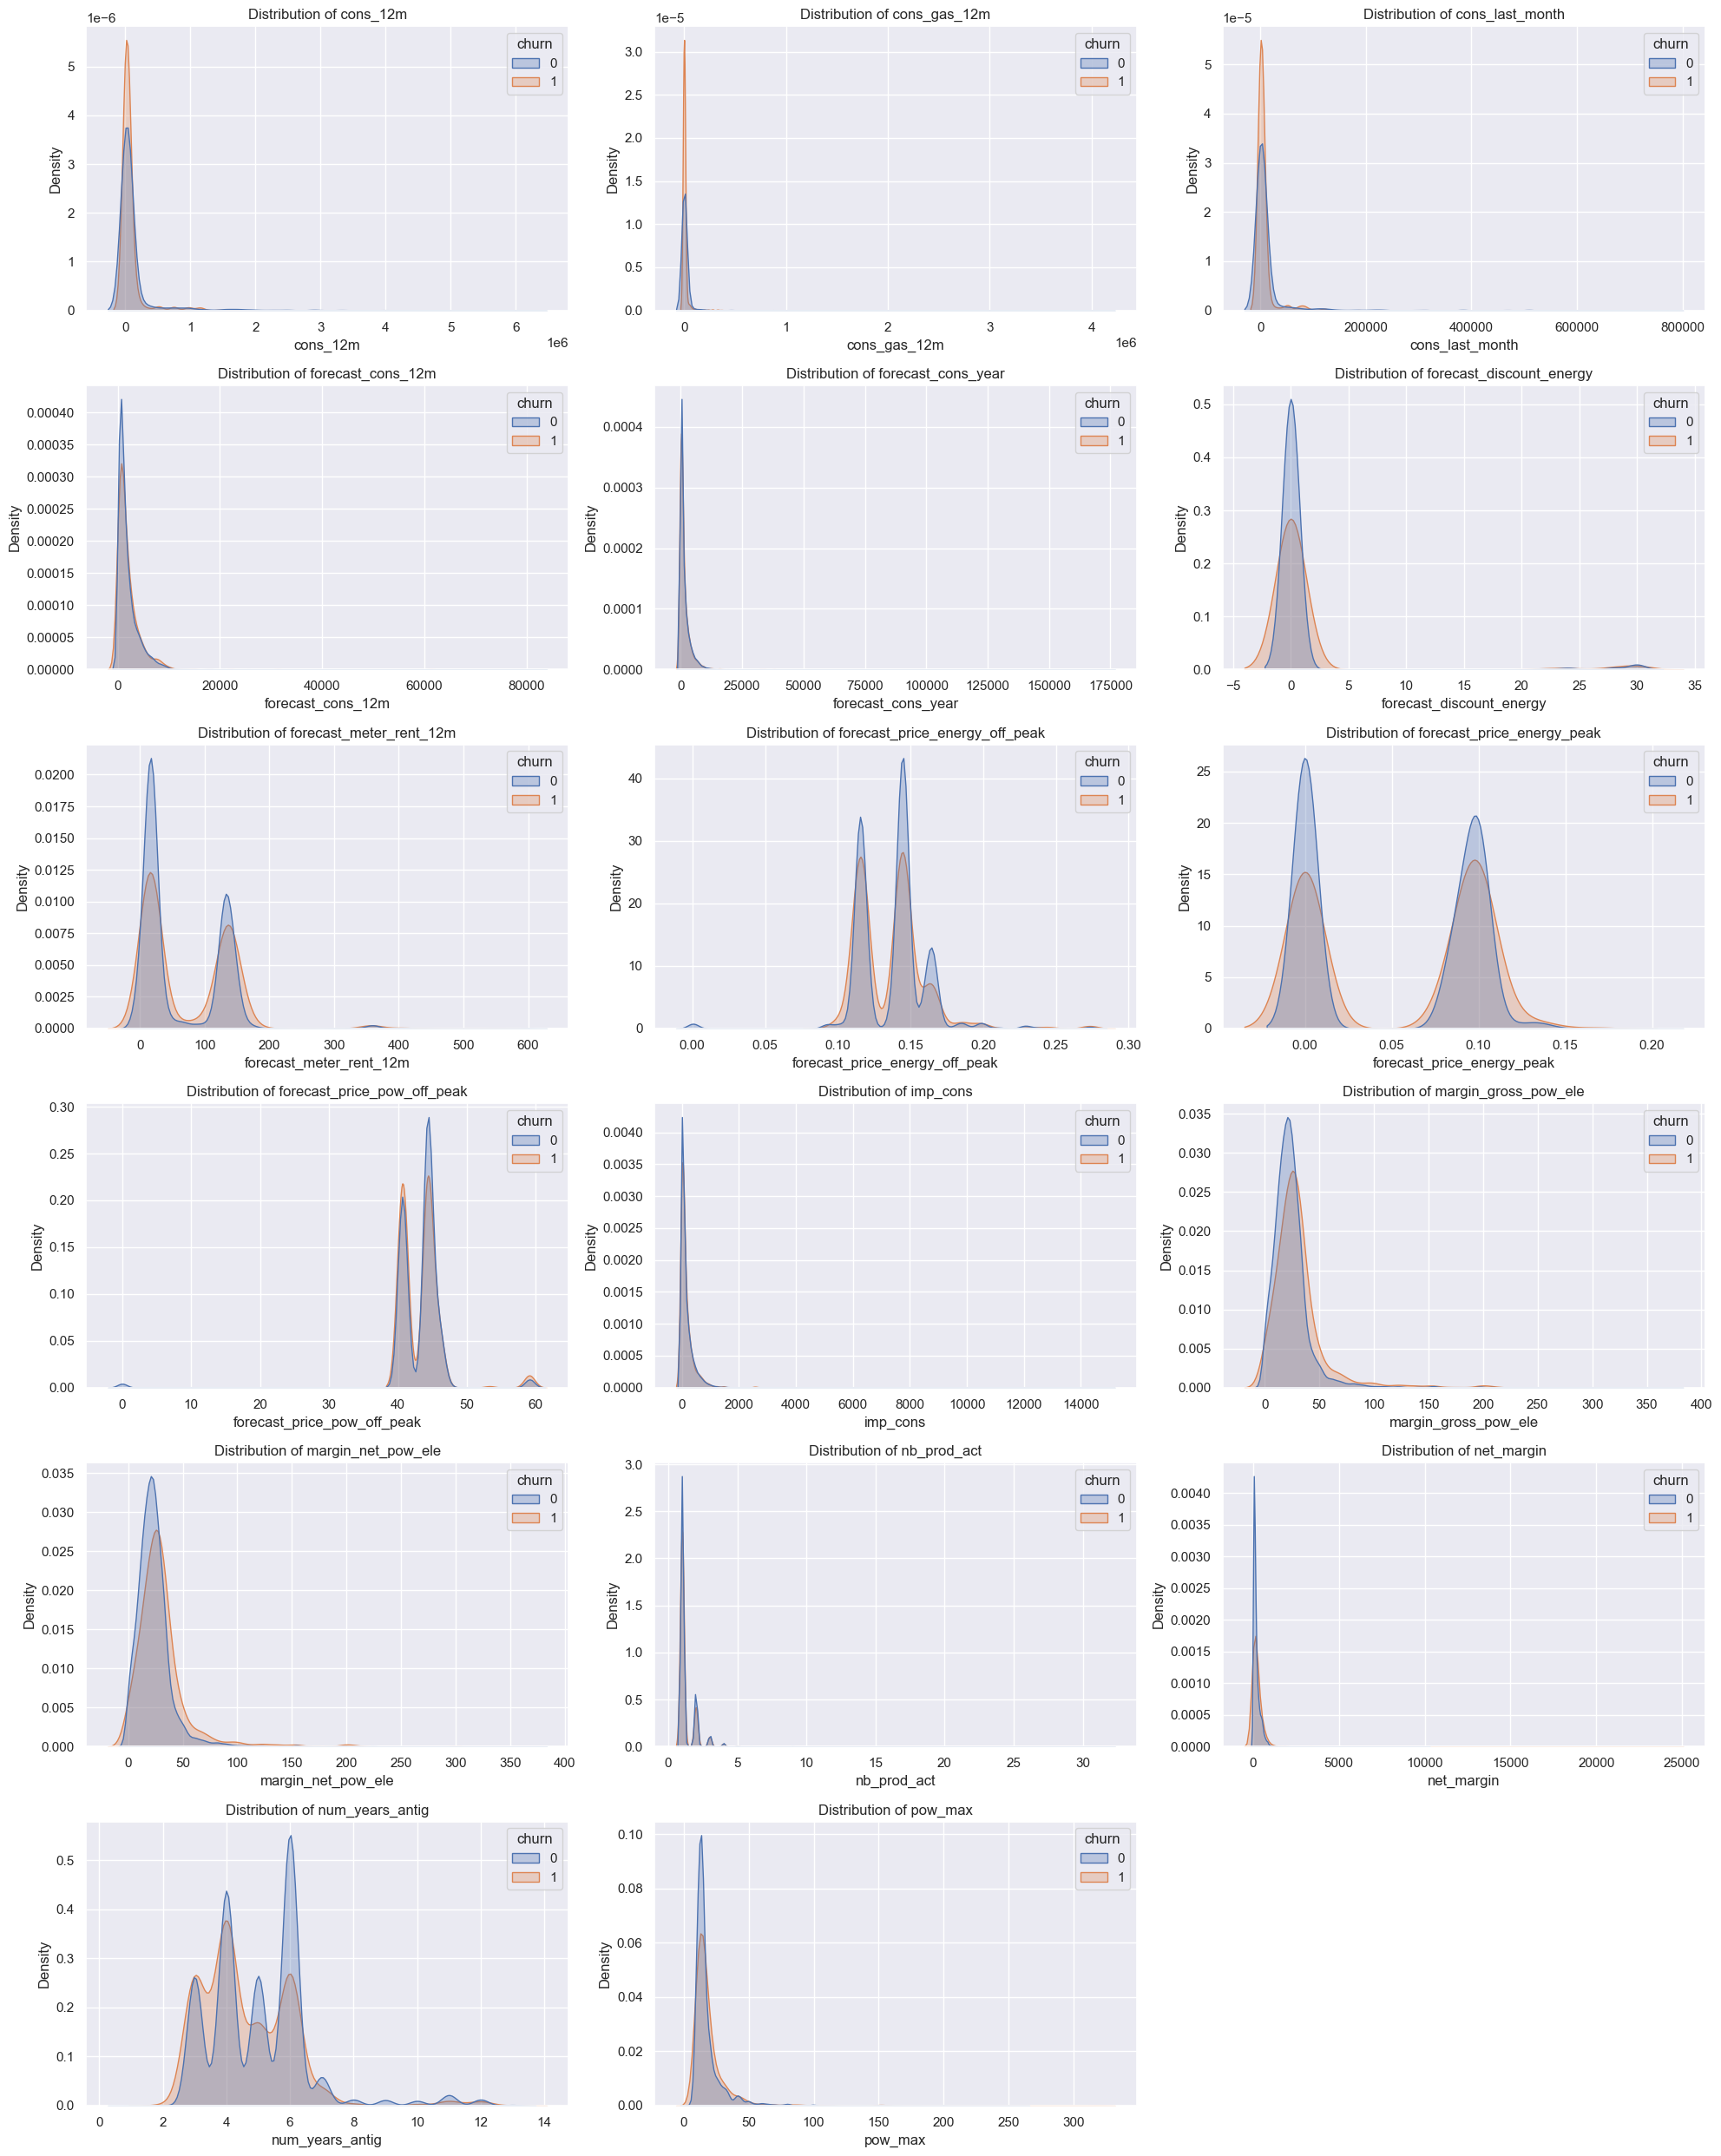

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns

pair_cols = [
    'cons_12m',
    'cons_gas_12m',
    'cons_last_month',
    'forecast_cons_12m',
    'forecast_cons_year',
    'forecast_discount_energy',
    'forecast_meter_rent_12m',
    'forecast_price_energy_off_peak',
    'forecast_price_energy_peak',
    'forecast_price_pow_off_peak',
    'imp_cons',
    'margin_gross_pow_ele',
    'margin_net_pow_ele',
    'nb_prod_act',
    'net_margin',
    'num_years_antig',
    'pow_max'
]

pair_cols = [col for col in pair_cols if col in client_df.columns]

fig, axes = plt.subplots(6, 3, figsize=(20, 25))
axes = axes.flatten()

for i, col in enumerate(pair_cols):
    sns.kdeplot(
        data=client_df,
        x=col,
        hue='churn',
        hue_order=[0, 1],
        fill=True,
        alpha=0.3,
        common_norm=False,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Density')

# Remove unused subplot
for j in range(len(pair_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Observations:**

- Most numerical features are highly right-skewed, with a few extreme values.
- Consumption, pricing, and margin distributions show substantial overlap between churned and retained customers.
- Most customers have 3–6 years of tenure and 1–2 active products.
- No single numerical feature clearly separates churned customers from retained customers.

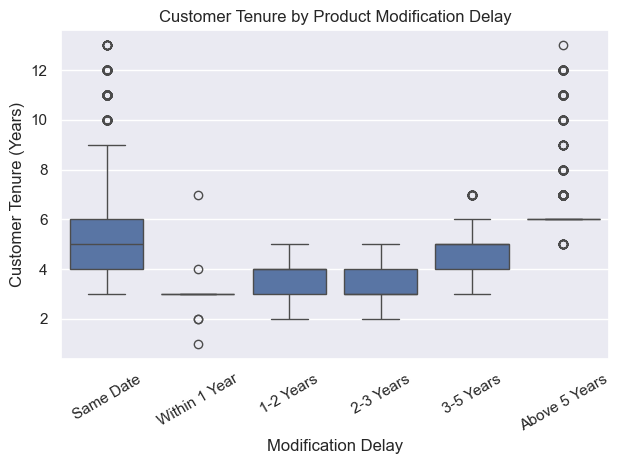

In [101]:
sns.boxplot(
    data=client_df,
    x='modification_group',
    y='num_years_antig'
)

plt.title('Customer Tenure by Product Modification Delay')
plt.xlabel('Modification Delay')
plt.ylabel('Customer Tenure (Years)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Observations:**

**What the graph shows:**

- **Blue boxes:** Distribution of customer tenure (in years) for each product modification delay group.
- **X-axis:** Time between customer activation and product modification.
- **Y-axis:** Customer tenure in years.

* Customers in the Same Date group have a median tenure of approximately 5 years.
* Customers whose products were modified within 1 year have a median tenure of approximately 3 years.
* Customers in the 1–2 Years and 2–3 Years groups have a median tenure of approximately 3–4 years.
* Customers in the 3–5 Years group have a median tenure of approximately 4 years.
* Customers in the Above 5 Years group have a median tenure of approximately 6 years.
* The Above 5 Years and Same Date groups show several higher-tenure outliers, indicating that some customers have stayed with the company much longer than most customers in those groups.

**Conclusion:** Customers whose products were modified after more than 5 years generally have higher tenure, while those modified within 1 year tend to have shorter tenure. This suggests a relationship between product modification timing and customer tenure.

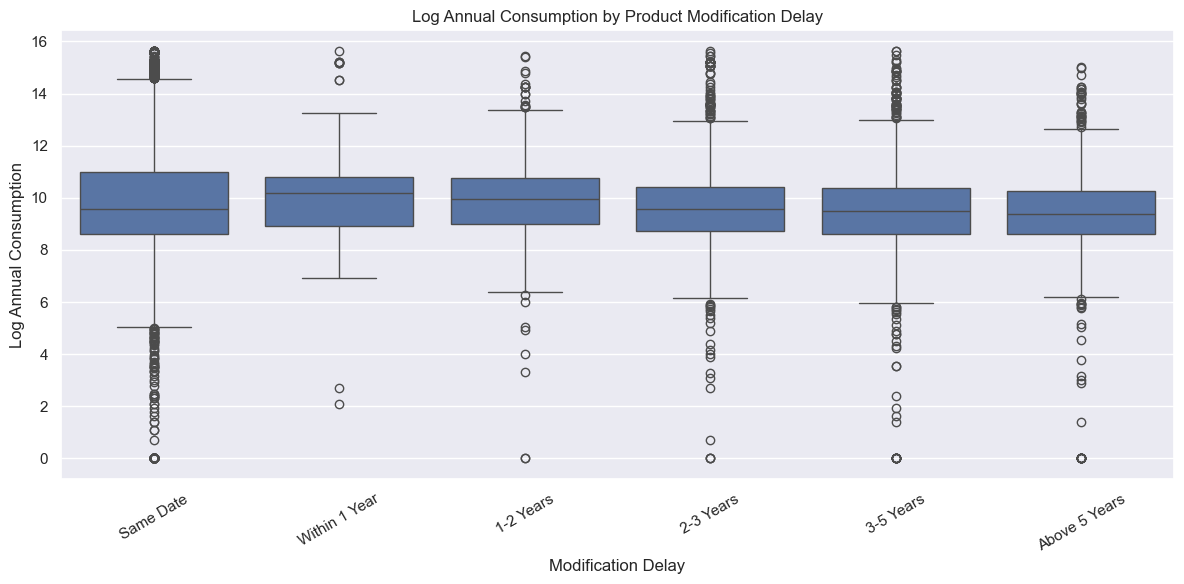

In [102]:
client_df['log_cons_12m'] = np.log1p(client_df['cons_12m'])

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=client_df,
    x='modification_group',
    y='log_cons_12m'
)

plt.title('Log Annual Consumption by Product Modification Delay')
plt.xlabel('Modification Delay')
plt.ylabel('Log Annual Consumption')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

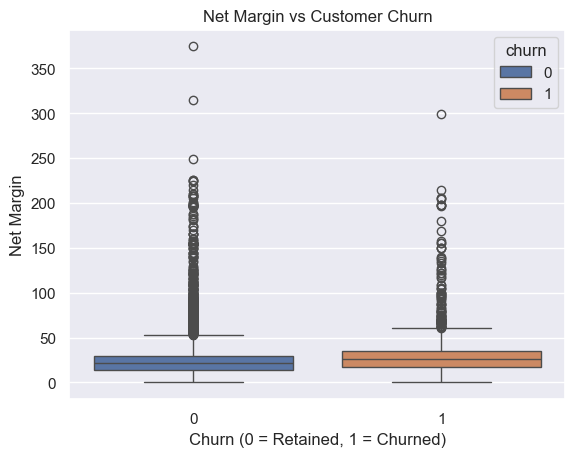

In [103]:
sns.boxplot(
    data=client_df,
    x='churn',
    y='margin_net_pow_ele',
    hue='churn'
)

plt.title('Net Margin vs Customer Churn')
plt.xlabel('Churn (0 = Retained, 1 = Churned)')
plt.ylabel('Net Margin')
plt.show()

**Observations:**

* Churned customers have a slightly higher median net margin than retained customers.
* The median net margin for churned customers is approximately 25, compared to approximately 20 for retained customers.
* Both groups have a similar distribution, but churned customers show a slightly wider spread.
* Both groups contain several high-value outliers, indicating some customers have unusually high net margins.
* The distributions overlap considerably, suggesting that net margin alone may not clearly distinguish churned customers from retained customers.

**Conclusion:** Churned customers tend to have slightly higher net margins than retained customers.means customers who left the company (churned) generally had slightly higher net margins than customers who stayed.

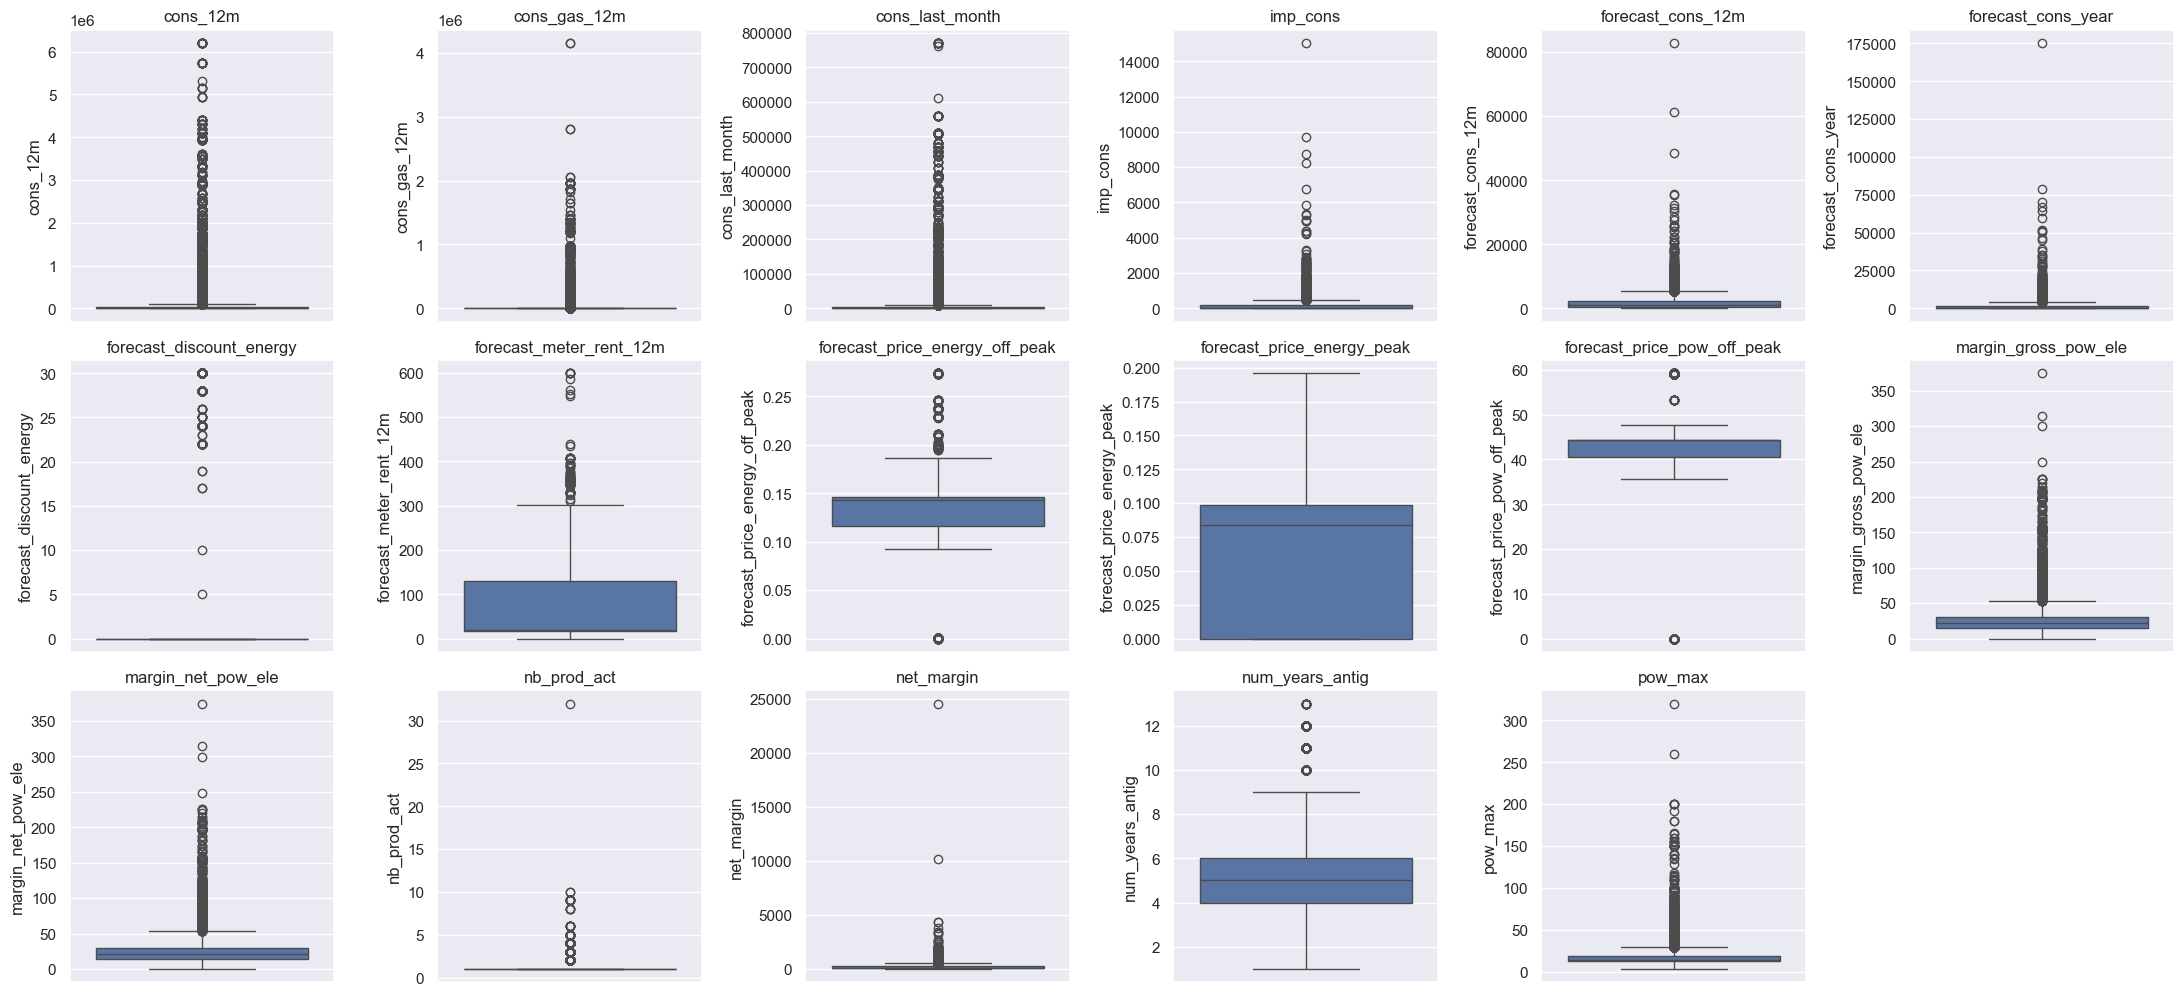

In [104]:
columns = [
    'cons_12m', 'cons_gas_12m', 'cons_last_month', 'imp_cons',
    'forecast_cons_12m', 'forecast_cons_year',
    'forecast_discount_energy', 'forecast_meter_rent_12m',
    'forecast_price_energy_off_peak', 'forecast_price_energy_peak',
    'forecast_price_pow_off_peak', 'margin_gross_pow_ele',
    'margin_net_pow_ele', 'nb_prod_act', 'net_margin',
    'num_years_antig', 'pow_max'
]

fig, axes = plt.subplots(6, 6, figsize=(22, 20))
axes = axes.flatten()

for i, col in enumerate(columns):
    sns.boxplot(data=client_df, y=col, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')

# Hide unused subplots
for i in range(len(columns), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

observation

- `cons_12m`, `cons_gas_12m` and `cons_last_month` - Show highly right-skewed distributions with numerous potential outliers.
- `imp_cons`, `forecast_cons_12m` and `forecast_cons_year` - Show right-skewed distributions with several extreme values.
- `forecast_discount_energy` - Most values are concentrated around zero, with a few unusually high values.
- `forecast_meter_rent_12m` - Shows a wide spread of values and several potential outliers.
- `forecast_price_energy_off_peak` and `forecast_price_pow_off_peak` - Most values are concentrated within a relatively narrow range, with a few extreme values.
- `forecast_price_energy_peak` - Shows a large concentration of zero values and a relatively wide spread.
- `margin_gross_pow_ele`, `margin_net_pow_ele` and `net_margin` - Show right-skewed distributions with several extreme values.
- `nb_prod_act` - Most customers have one active product, with a few customers having significantly more.
- `num_years_antig` - Values are relatively concentrated between 4 and 6 years, with a few higher-tenure customers.
- `pow_max` - Most values are concentrated within a lower range, with several potential outliers.

**Overall Observation:**

Most numerical features show right-skewed distributions and potential outliers. Consumption, margin and subscribed power variables contain particularly extreme values.

**Note:** These are potential outliers identified visually using boxplots. They should not be removed blindly, as they may represent genuine customer behavior.

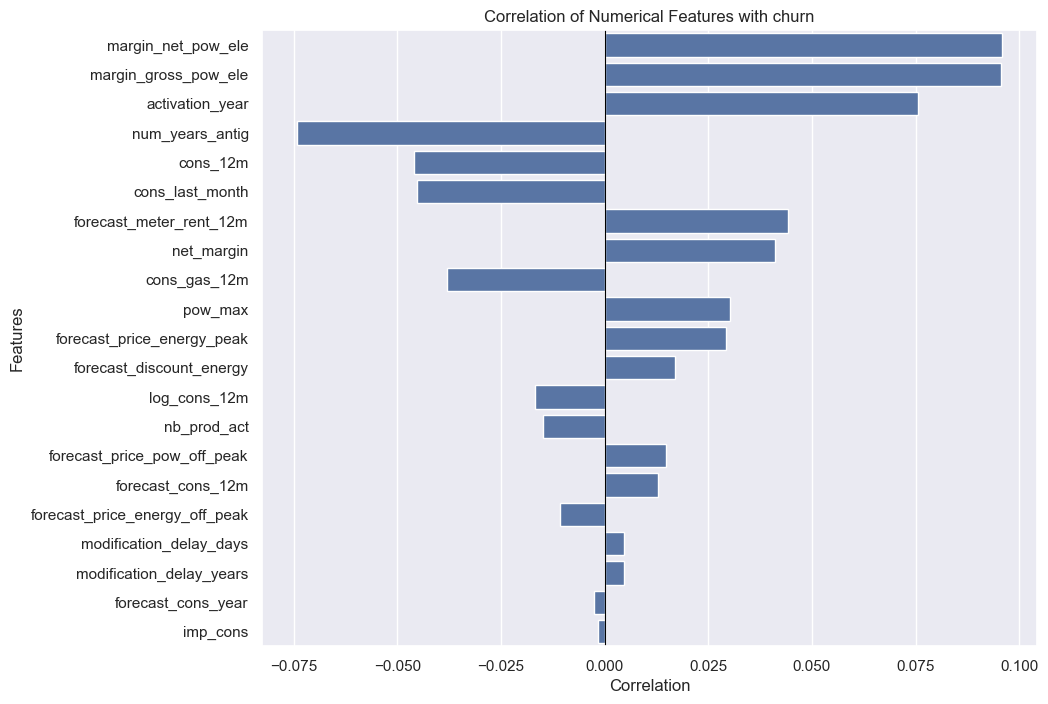

In [105]:
price_corr = plot_correlation(client_df, 'churn')

**Correlation: Customer-Level Numerical Features vs Churn (**`client_df`**)**

**Observations:**

- `margin_net_pow_ele` and `margin_gross_pow_ele` show the strongest positive correlations with churn (approximately 0.096).
- `num_years_antig` shows the strongest negative correlation (approximately -0.074), suggesting that customers with longer tenure tend to have lower churn.
- `cons_12m` and `cons_last_month` also show negative correlations (approximately -0.047).
- All other numerical features have relatively weak correlations with churn.

**Conclusion:** Customer tenure and margin-related features show comparatively stronger associations with churn, although all correlations remain weak.



## Price Data Visualization

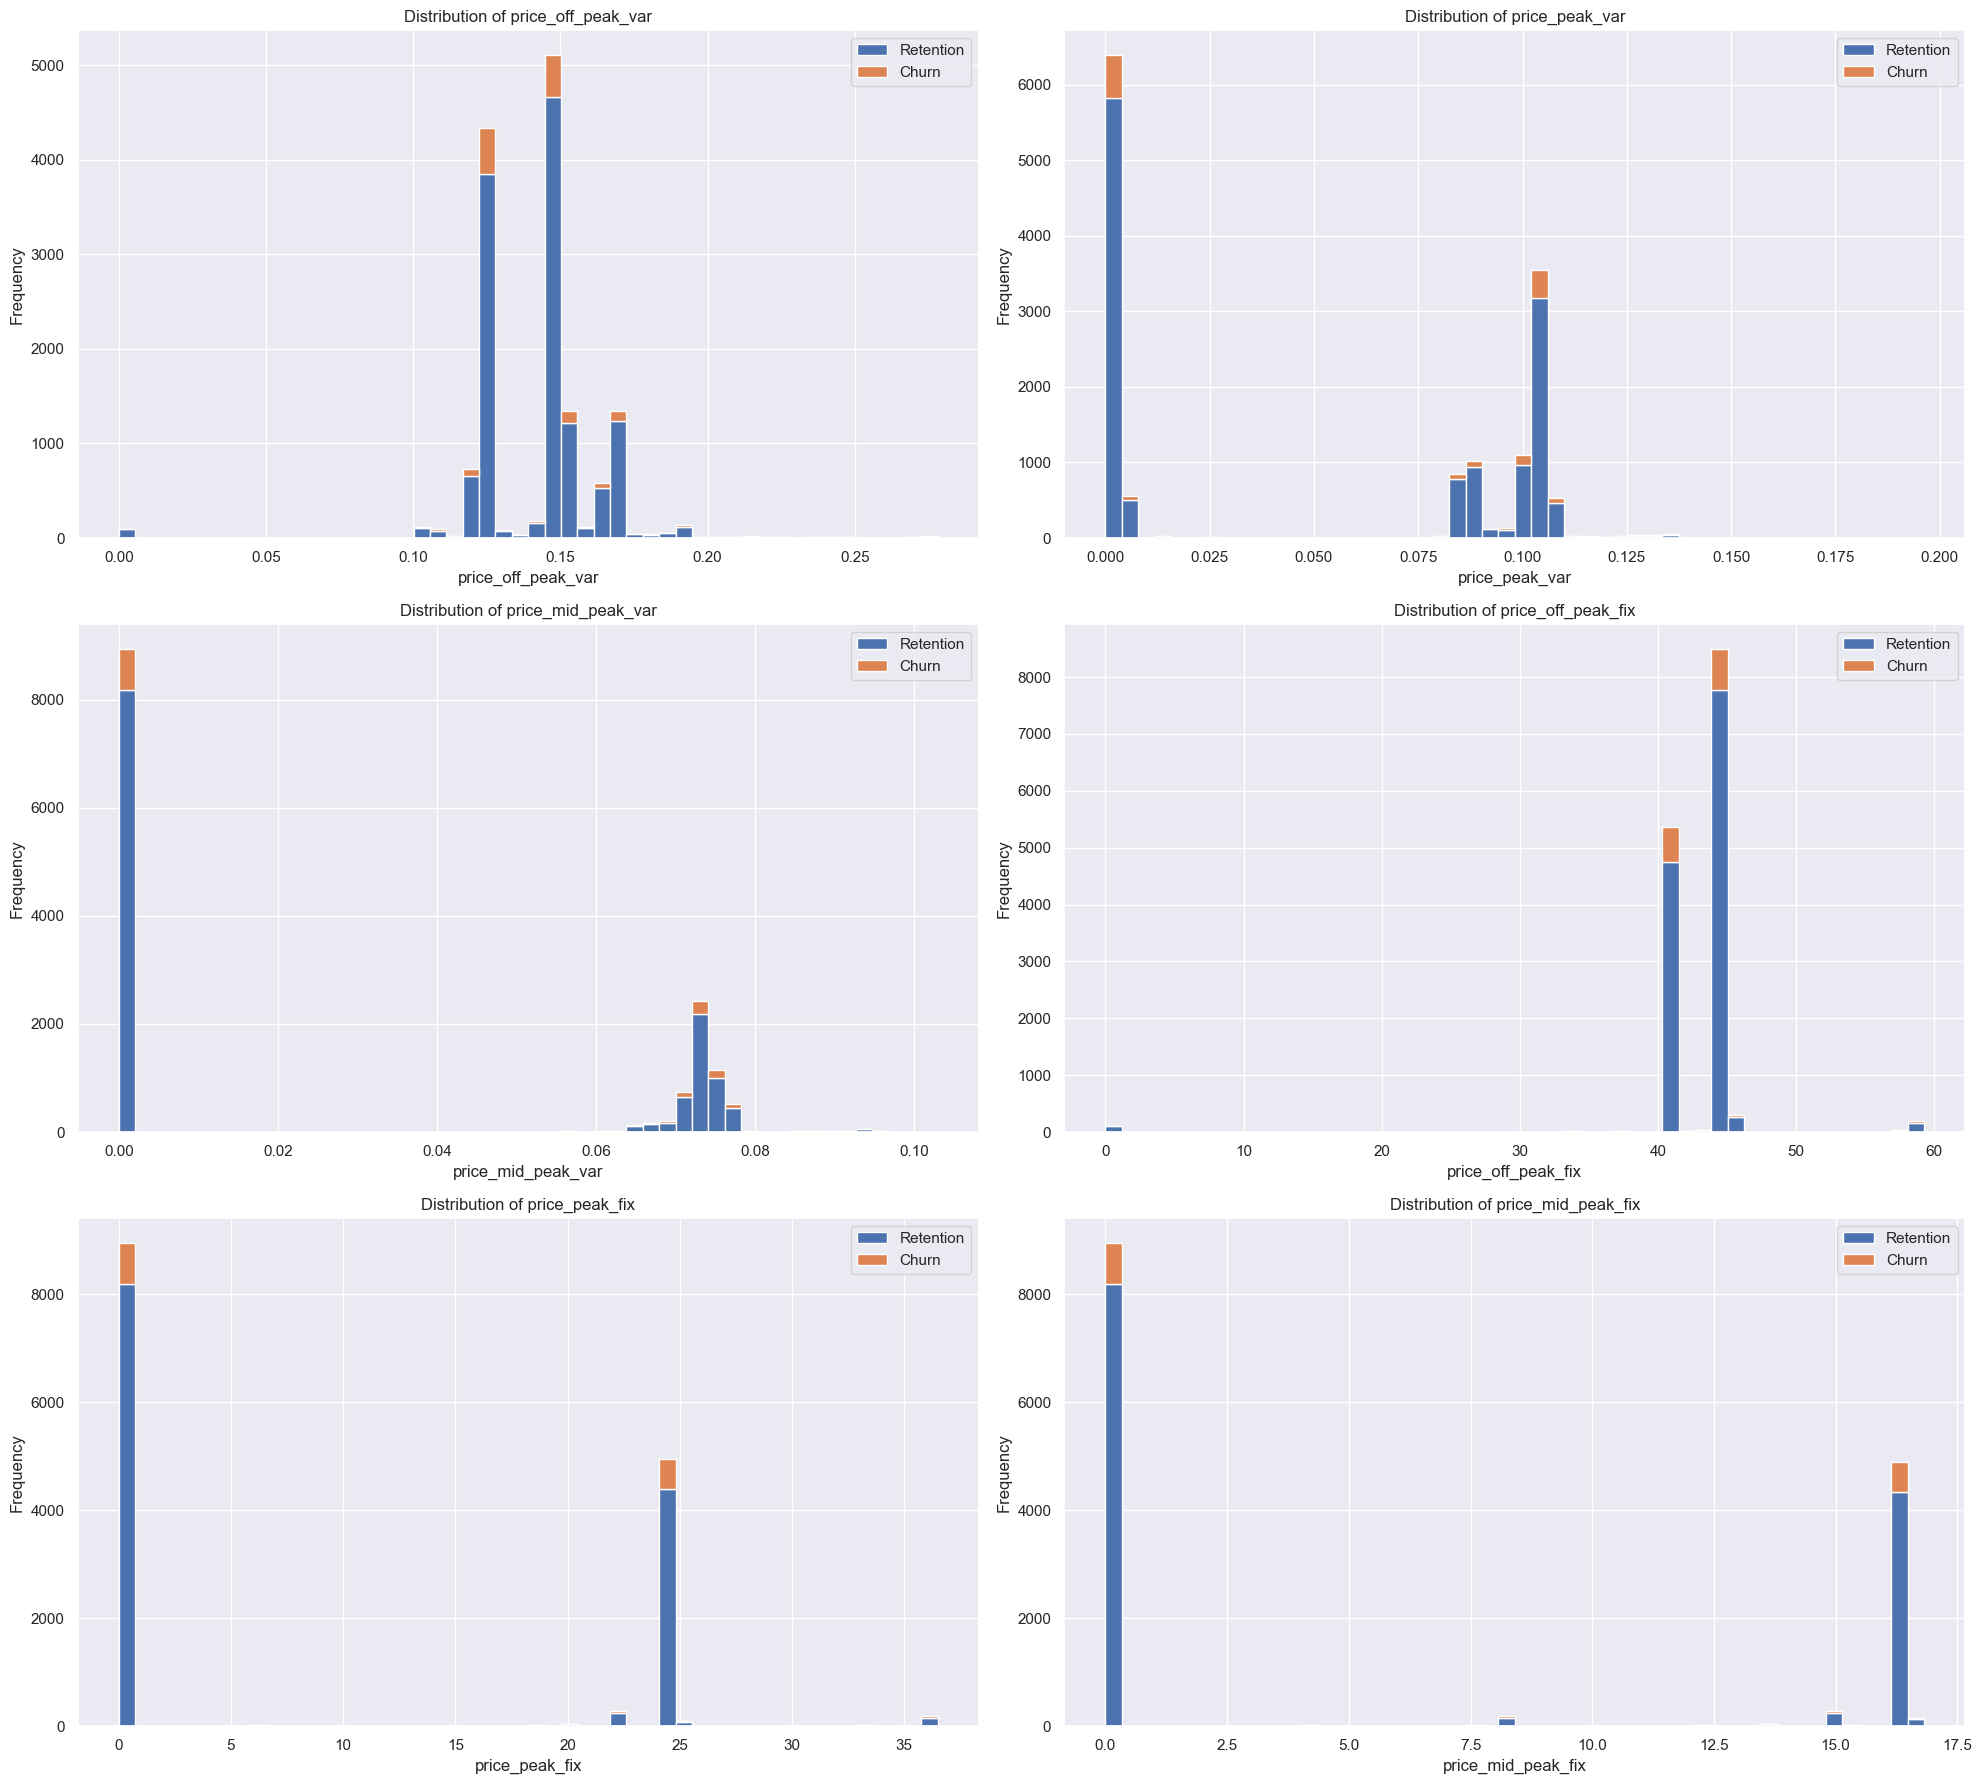

In [106]:
# Note: Since price_df contains data only for 2015, the distributions below
# represent customer pricing patterns for 2015 only, not historical price trends.

price_cols = [
    'price_off_peak_var',
    'price_peak_var',
    'price_mid_peak_var',
    'price_off_peak_fix',
    'price_peak_fix',
    'price_mid_peak_fix'
]

fig, axs = plt.subplots(3, 2, figsize=(20, 18))
axs = axs.flatten()

for i, col in enumerate(price_cols):
    plot_distribution(consumption_price, col, axs[i])
    axs[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

**Observations:**

- `price_off_peak_var` values are mainly concentrated between 0.12 and 0.17, with some zero values.
- `price_peak_var` and `price_mid_peak_var` show a large concentration of zero values, with the remaining values clustered around 0.08–0.10 and 0.07–0.08, respectively.
- Fixed-price features (`price_off_peak_fix`, `price_peak_fix`, `price_mid_peak_fix`) show distinct clusters at specific price levels.
- Retained customers dominate across all six distributions, while churned customers follow a broadly similar distribution.

**Overall:** The distributions show no clear visual separation between retained and churned customers. Further statistical analysis is needed to understand their relationship with churn.

**Observations:**

- `price_off_peak_var` shows several upper outliers and a few lower outliers.
- `price_off_peak_fix` also contains multiple upper outliers.
- `price_peak_var` and `price_mid_peak_var` have a wide spread, with many customers having zero values.
- `price_peak_fix` and `price_mid_peak_fix` show a large spread, mainly due to zero and higher price values.
- Overall, pricing features have different distributions, and some contain noticeable outliers.

**Important:** These outliers may represent genuine pricing differences between customers and should not be removed without further investigation.

**Next step:** Check outlier percentages and investigate whether these values are valid before deciding on any treatment.

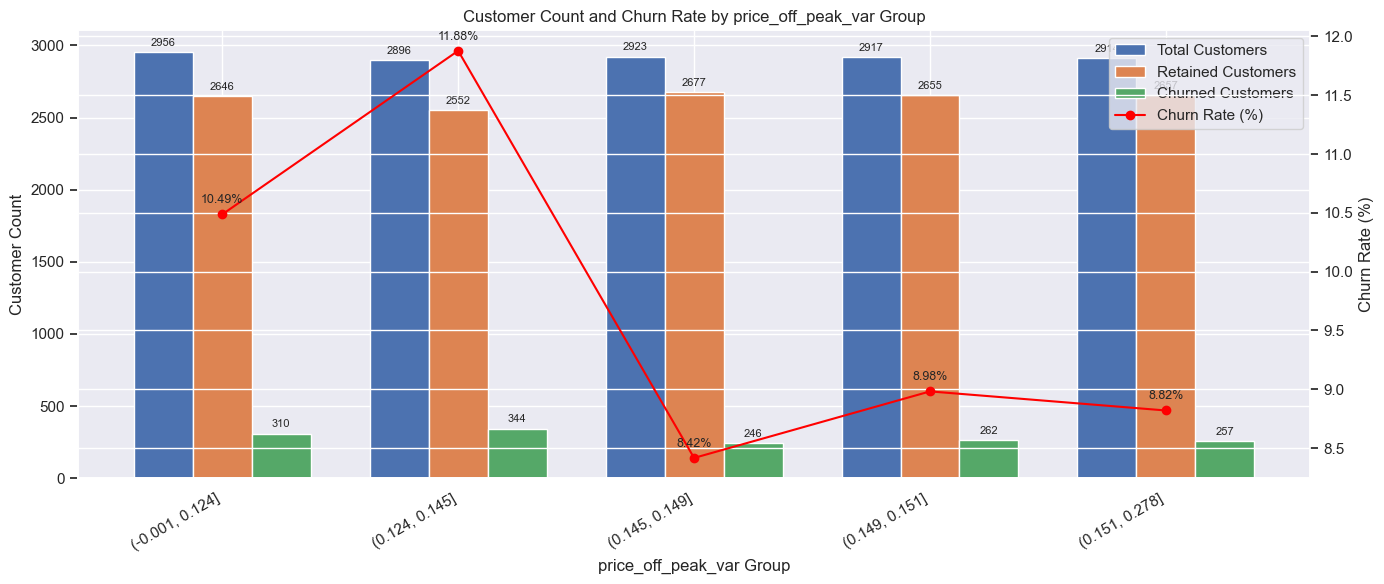

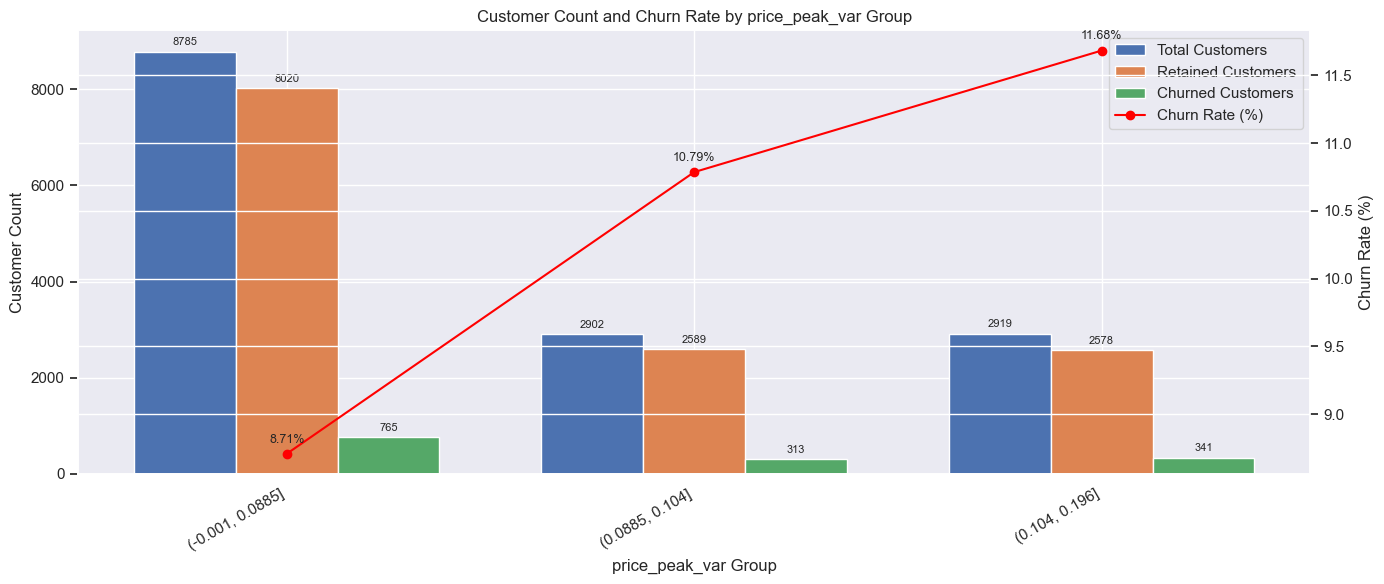

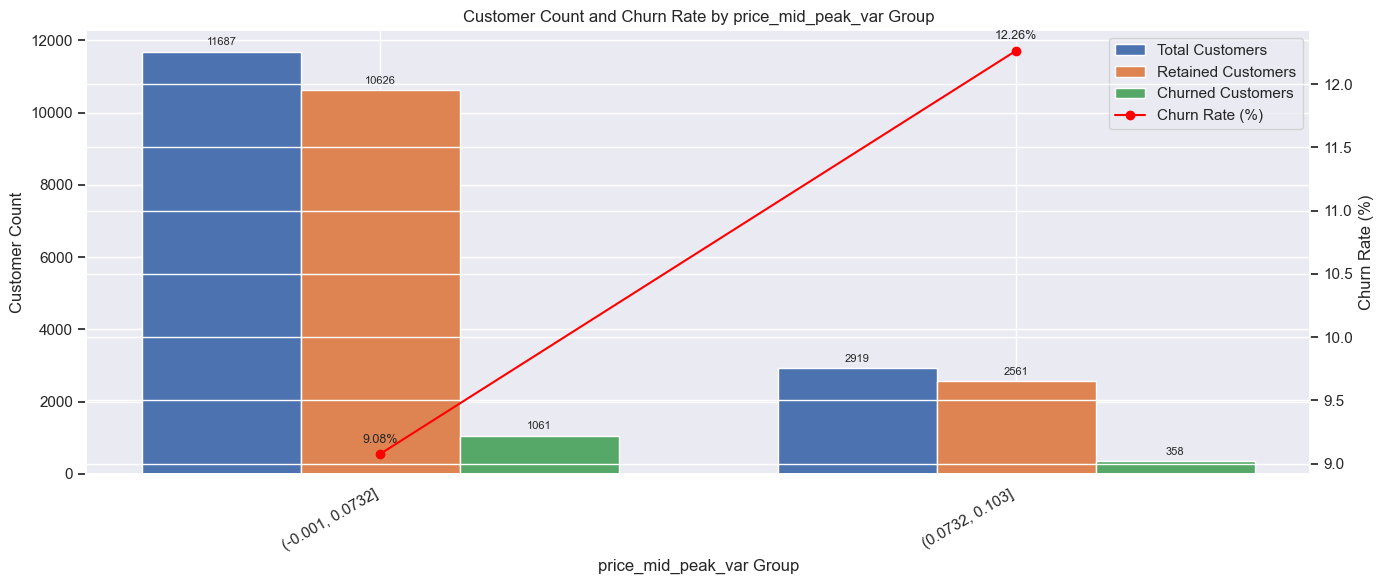

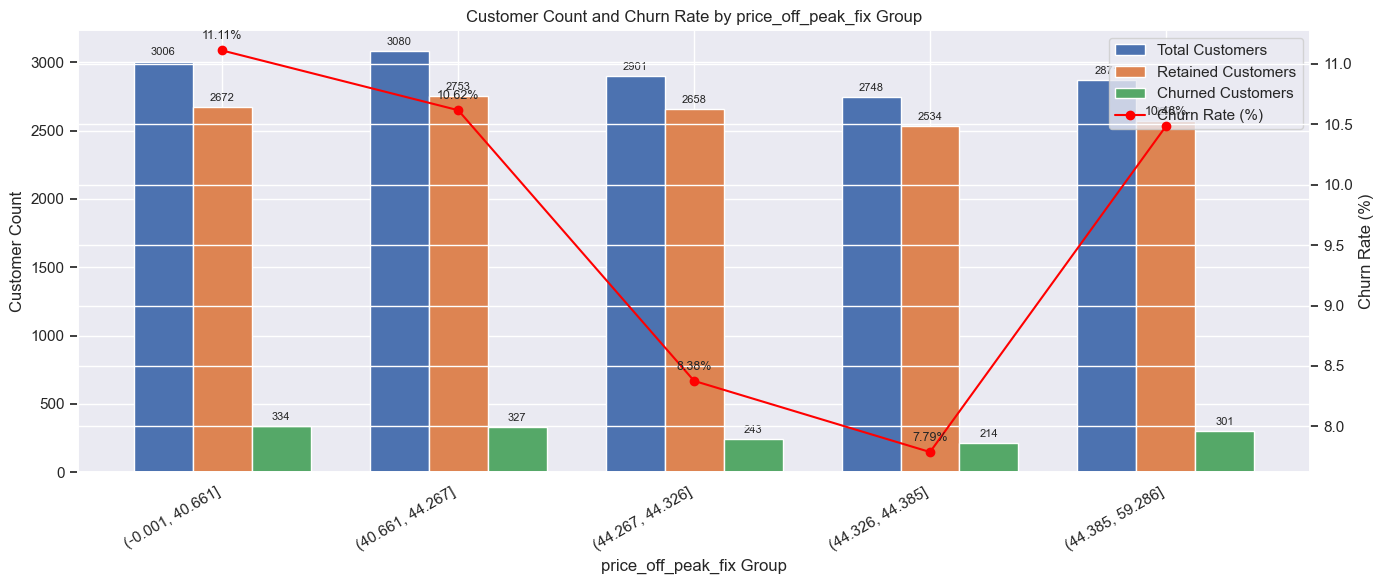

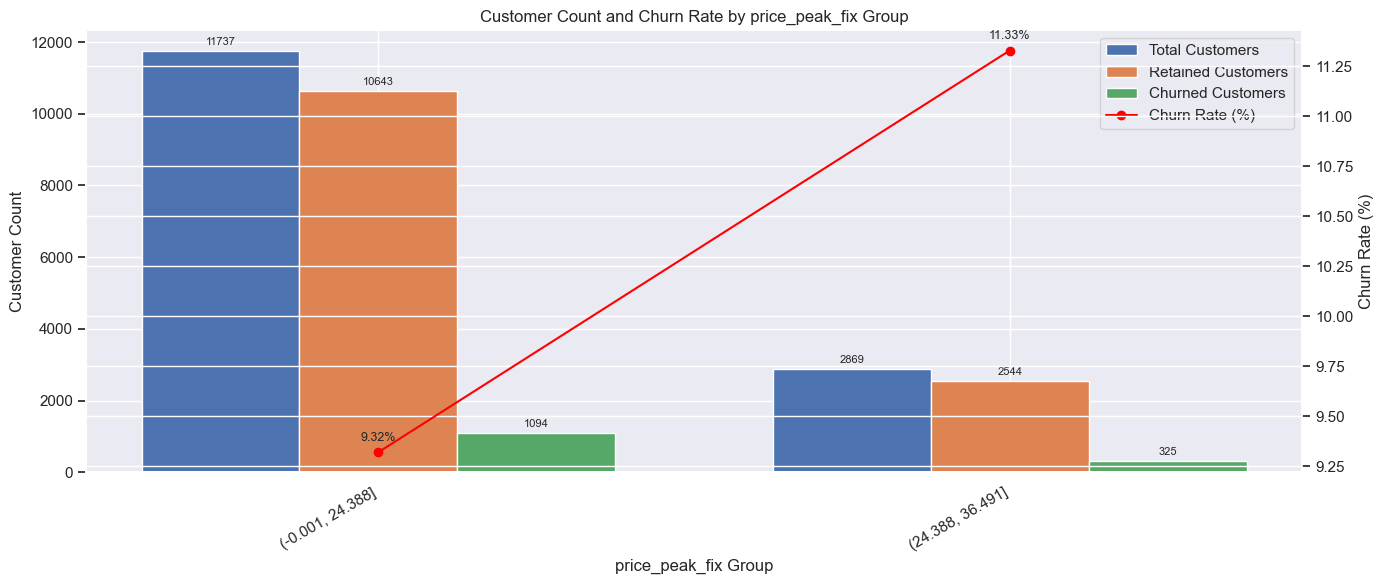

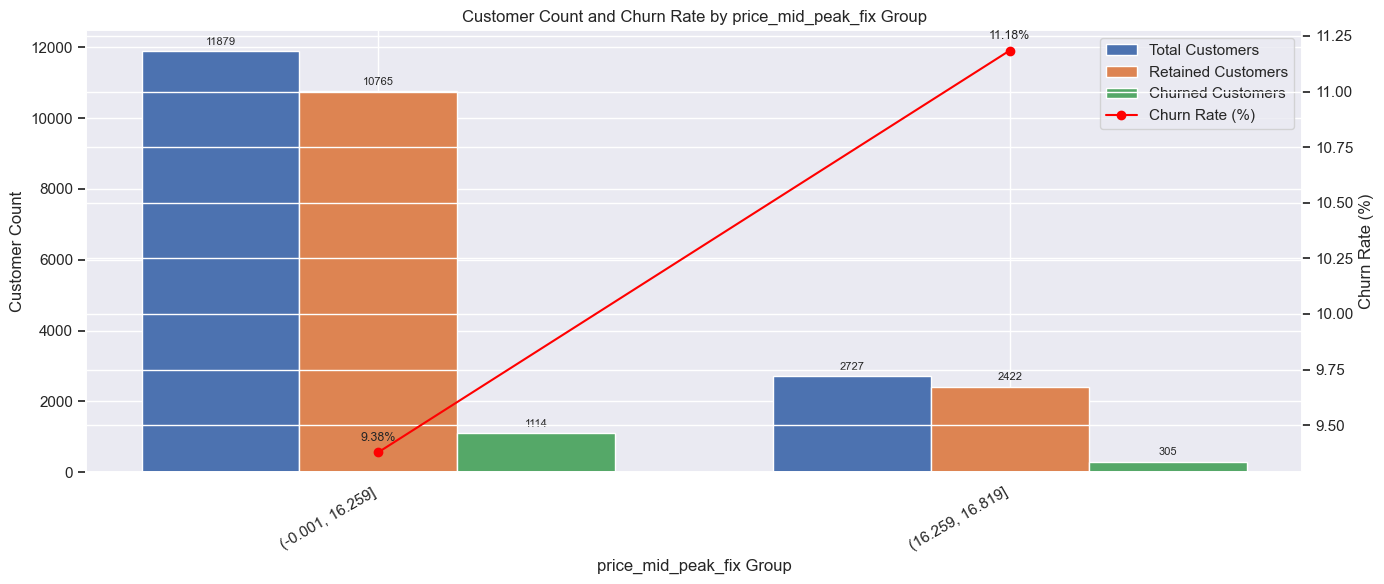

In [107]:
plot_churn_rate(consumption_price, 'price_off_peak_var', method='qcut')
plot_churn_rate(consumption_price, 'price_peak_var', method='qcut')
plot_churn_rate(consumption_price, 'price_mid_peak_var', method='qcut')
plot_churn_rate(consumption_price, 'price_off_peak_fix', method='qcut')
plot_churn_rate(consumption_price, 'price_peak_fix', method='qcut')
plot_churn_rate(consumption_price, 'price_mid_peak_fix', method='qcut')

**Observations – 2015 Pricing Features vs Churn**

- `price_off_peak_var` – Churn fluctuates across price groups, reaching its highest rate of 11.88% in the second group and then declining.
- `price_peak_var` – Churn increases from 8.71% to 11.68% as prices increase, suggesting a possible positive relationship.
- `price_mid_peak_var` – The higher price group has a higher churn rate (12.26%) than the lower price group (9.08%).
- `price_off_peak_fix` – Churn fluctuates across groups. It decreases to 7.79% in the fourth group before rising to 10.48% in the highest group.
- `price_peak_fix` – The higher price group has a higher churn rate (11.33%) than the lower price group (9.32%).
- `price_mid_peak_fix` – The higher price group has a higher churn rate (11.18%) than the lower price group (9.38%).

**Conclusion**

- Most pricing features show higher churn rates in their higher-price groups, particularly peak and mid-peak pricing.
- However, the relationship is not consistent across all pricing features.
- `price_off_peak_var` and `price_off_peak_fix` show fluctuating churn patterns rather than a clear increasing trend.

**Important:** These results are based on customers' average 2015 prices. They suggest possible associations between pricing and churn but do not establish causation.

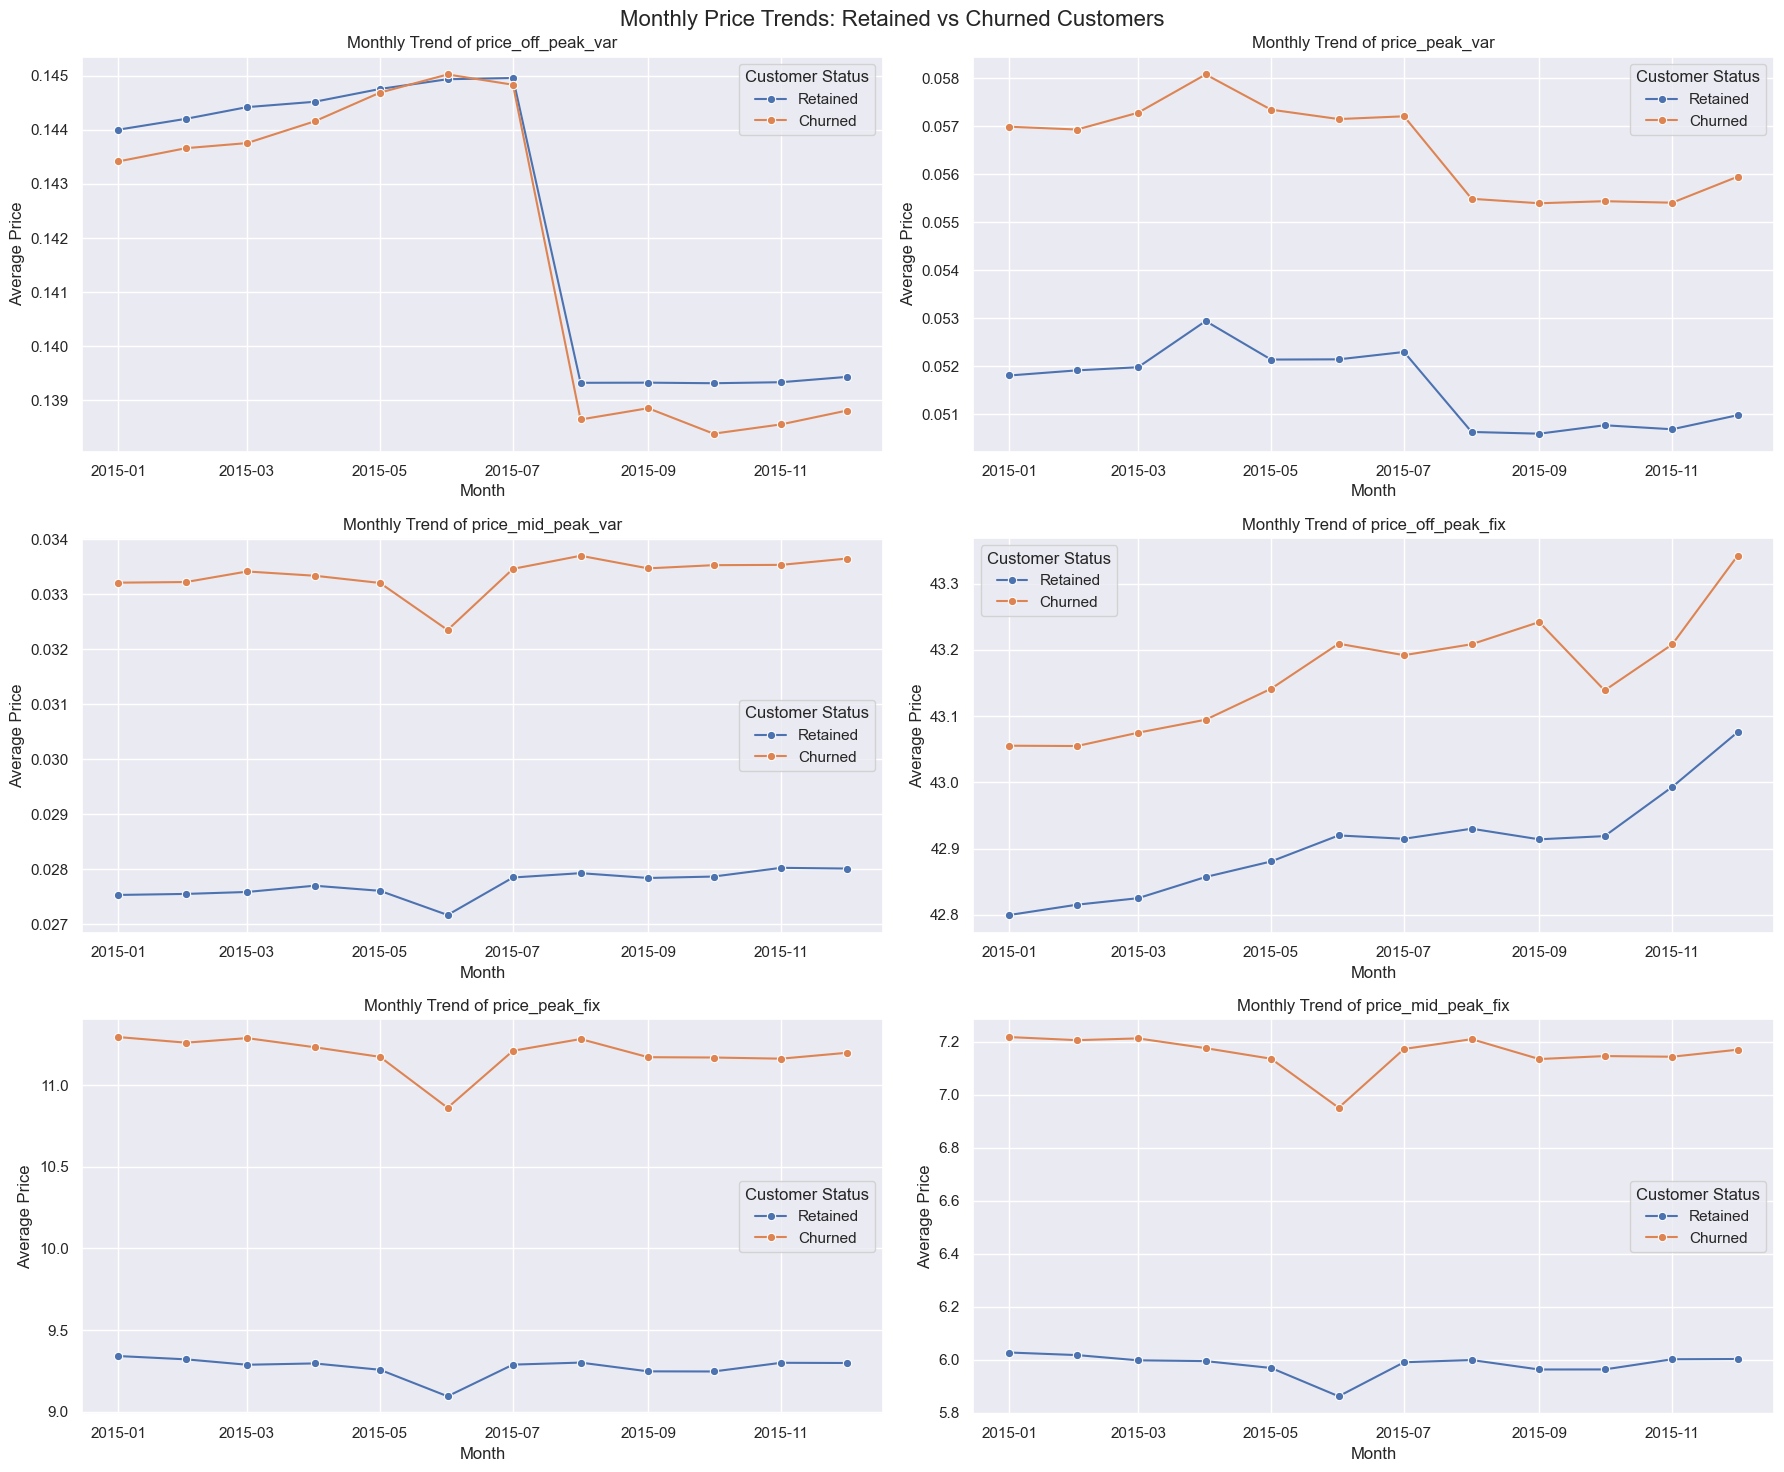

In [108]:
# Group monthly prices by date and churn status
monthly_prices = (
    merged_price_right_df
    .groupby(['price_date', 'churn'])[price_cols]
    .mean()
    .reset_index()
)


monthly_prices['Customer Status'] = monthly_prices['churn'].map({
    0: 'Retained',
    1: 'Churned'
})

fig, axs = plt.subplots(3, 2, figsize=(18, 15))
axs = axs.flatten()

for i, col in enumerate(price_cols):

    sns.lineplot(
        data=monthly_prices,
        x='price_date',
        y=col,
        hue='Customer Status',
        hue_order=['Retained', 'Churned'],
        marker='o',
        ax=axs[i]
    )

    axs[i].set_title(f'Monthly Trend of {col}')
    axs[i].set_xlabel('Month')
    axs[i].set_ylabel('Average Price')
    axs[i].legend(title='Customer Status')

plt.suptitle(
    'Monthly Price Trends: Retained vs Churned Customers',
    fontsize=16
)

plt.tight_layout()
plt.show()

**Observations:**

- **Blue line:** Average monthly price for retained customers.
- **Orange line:** Average monthly price for churned customers.
- **X-axis:** Months in 2015.
- **Y-axis:** Average price for each pricing component.

* **Peak Variable Price (**`price_peak_var`**):** Churned customers consistently have higher average prices than retained customers throughout the year.
* **Mid-Peak Variable Price (**`price_mid_peak_var`**):** Churned customers also have consistently higher average prices.
* **Off-Peak Variable Price (**`price_off_peak_var`**):** The difference is small. Retained customers have slightly higher average prices during most months.
* **Off-Peak Fixed Price (**`price_off_peak_fix`**):** Churned customers consistently have higher average prices than retained customers.
* **Peak Fixed Price (**`price_peak_fix`**):** Churned customers have noticeably higher average prices throughout the year.
* **Mid-Peak Fixed Price (**`price_mid_peak_fix`**):** Churned customers also have consistently higher average prices.

**Conclusion:** for year 2015, Five out of the six pricing components show higher average prices for churned customers compared with retained customers. This suggests that higher electricity prices may be associated with customer churn.

We should check whether these price differences are statistically significant using an independent two-sample t-test (or Mann–Whitney U test if appropriate).

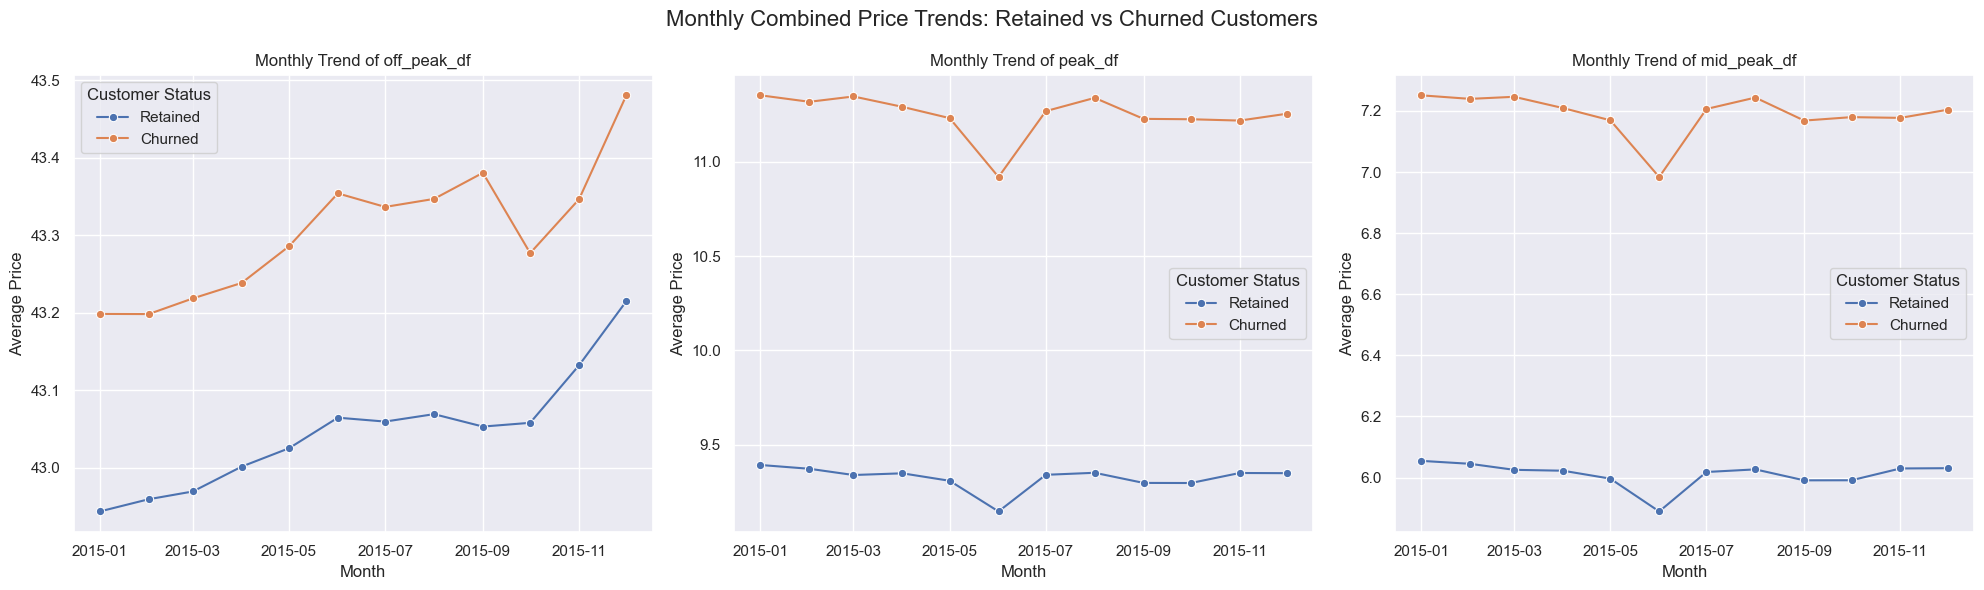

In [109]:
merged_price_right_df['off_peak_df'] = (
    merged_price_right_df['price_off_peak_var'] +
    merged_price_right_df['price_off_peak_fix']
)

merged_price_right_df['peak_df'] = (
    merged_price_right_df['price_peak_var'] +
    merged_price_right_df['price_peak_fix']
)

merged_price_right_df['mid_peak_df'] = (
    merged_price_right_df['price_mid_peak_var'] +
    merged_price_right_df['price_mid_peak_fix']
)


price_types = ['off_peak_df', 'peak_df', 'mid_peak_df']

price_trends = (
    merged_price_right_df
    .groupby(['price_date', 'churn'])[price_types]
    .mean()
    .reset_index()
)

price_trends['Customer Status'] = price_trends['churn'].map({
    0: 'Retained',
    1: 'Churned'
})

price_types = ['off_peak_df', 'peak_df', 'mid_peak_df']

fig, axs = plt.subplots(1, 3, figsize=(20, 6))

for i, col in enumerate(price_types):

    sns.lineplot(
        data=price_trends,
        x='price_date',
        y=col,
        hue='Customer Status',
        hue_order=['Retained', 'Churned'],
        marker='o',
        ax=axs[i]
    )

    axs[i].set_title(f'Monthly Trend of {col}')
    axs[i].set_xlabel('Month')
    axs[i].set_ylabel('Average Price')
    axs[i].legend(title='Customer Status')

plt.suptitle(
    'Monthly Combined Price Trends: Retained vs Churned Customers',
    fontsize=16
)

plt.tight_layout()
plt.show()

**Observations:**

- **Blue line:** Average combined price for retained customers.
- **Orange line:** Average combined price for churned customers.
- **X-axis:** Months in 2015.

* Churned customers consistently have higher average combined prices than retained customers across all three categories.
* **Off-Peak (low demand)** has the highest average combined price, followed by **Peak (high demand)** and **Mid-Peak (moderate demand)**.

**Conclusion:** Churned customers generally pay higher electricity prices than retained customers across all three pricing categories. This suggests that higher electricity prices may be associated with customer churn.

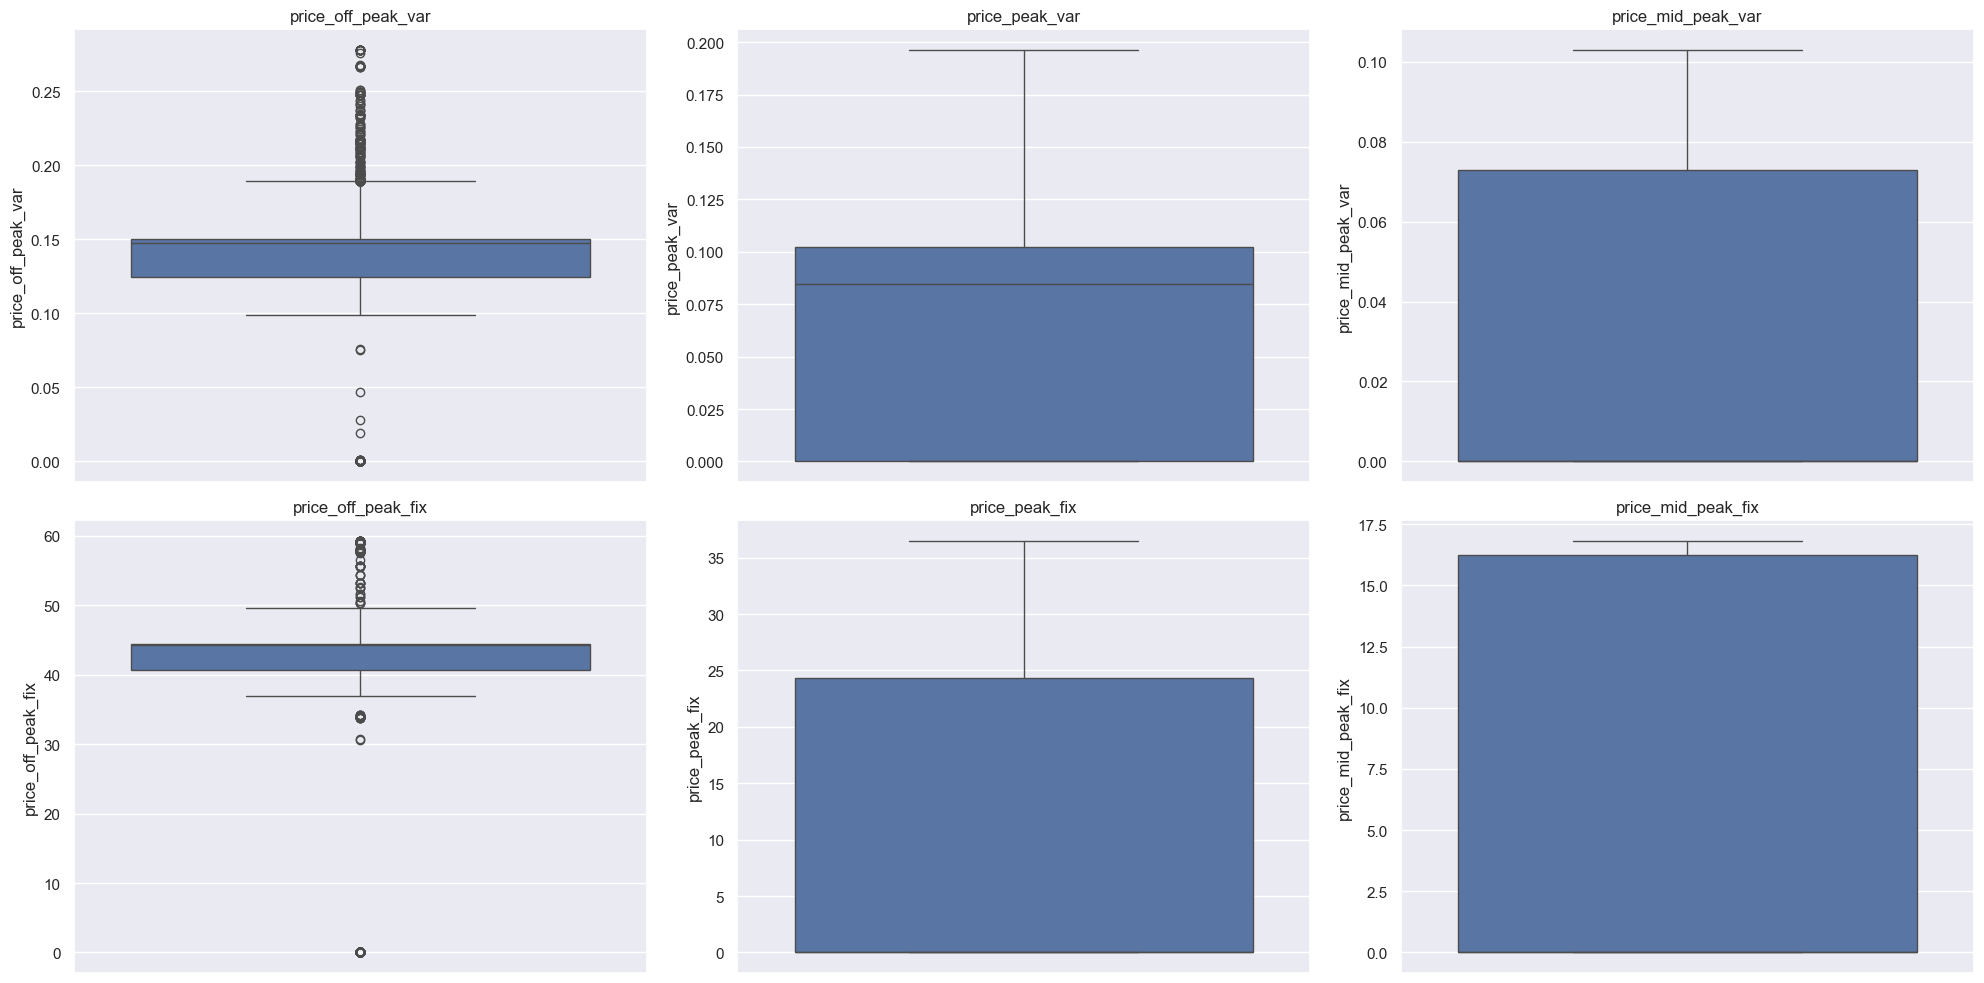

In [110]:
price_columns = [
    'price_off_peak_var',
    'price_peak_var',
    'price_mid_peak_var',
    'price_off_peak_fix',
    'price_peak_fix',
    'price_mid_peak_fix'
]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(price_columns):
    sns.boxplot(data=consumption_price, y=col, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

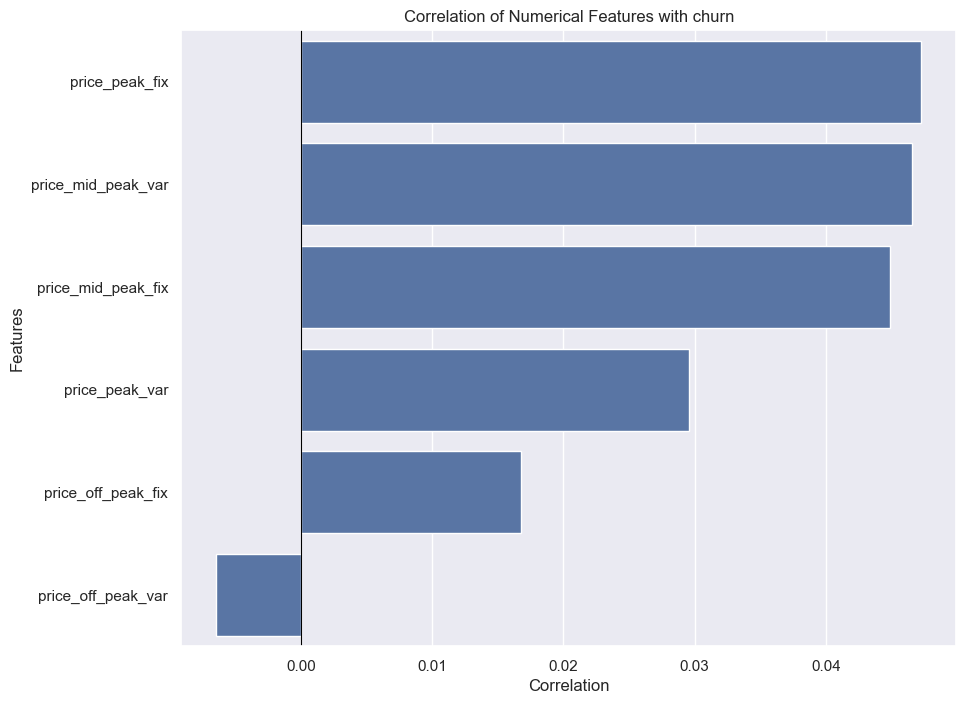

In [111]:
price_corr = plot_correlation(consumption_price, 'churn')

**Correlation: Average 2015 Pricing Features vs Churn (**`consumption_price`**)**

**Observations:**

- `price_peak_fix` shows the strongest positive correlation with churn (approximately 0.047).
- `price_mid_peak_var` and `price_mid_peak_fix` also show positive correlations.
- `price_peak_var` and `price_off_peak_fix` have weak positive correlations.
- `price_off_peak_var` shows a very weak negative correlation.
- Overall, all six pricing features have very weak linear correlations with churn.

**Conclusion:** Average 2015 pricing features do not show strong linear relationships with customer churn.

**Important Notes**

- Weak correlation does not mean a feature is unimportant. Features may have non-linear relationships or interactions with other features.
- Correlation does not establish causation.

**Next step:** Check correlations among numerical features themselves to identify potential multicollinearity.

**Key Takeaways – Exploratory Data Analysis**

**1. Customer Behaviour and Churn**

- **Churn imbalance:** The dataset contains 90.28% retained customers and 9.72% churned customers. Use Precision, Recall, F1-score and ROC-AUC rather than relying only on accuracy.
- **Customer tenure:** Customers with shorter tenure generally show higher churn rates. Churn is 13.52% for 3-year customers and decreases to 7.11% for 6-year customers. Most customers have 3–6 years of tenure.
- **Active products:** Most customers have 1–2 active products. Churn rates are relatively similar across customers with 1–4 products (approximately 8.51%–10%). Categories with more than 4 products have very few customers, making their churn rates unreliable.
- **Customer segment:** Electricity-only customers have a slightly higher churn proportion within their group than customers with both electricity and gas. Most churned customers belong to the electricity-only segment.
- **Gas subscription:** Customers without gas subscriptions have a slightly higher churn rate than customers with gas subscriptions.
- **Sales channels and campaigns:** `channel_sales` and `origin_up` show noticeable differences in churn rates, making them potentially useful predictive features.
- **Product modification:** Customers whose products were modified within one year show higher churn rates. Later modifications are generally associated with lower churn rates.
- **Margin-related features:** Churned customers tend to have slightly higher net margins than retained customers. Both gross and net power margins show similar distributions and should be checked for multicollinearity.

**2. Consumption and Numerical Features**

- **Skewness:** Many numerical features are highly right-skewed, indicating that most customers have relatively low values while a smaller number have very high values.
- **Zero-heavy features:** Several features contain substantial zero values, particularly `cons_gas_12m` (82.12%), `forecast_discount_energy` (96.49%), `forecast_cons_year` (42.09%), `imp_cons` (42.24%) and `cons_last_month` (34.12%). Zero consumption does not necessarily indicate missing data.
- **Extreme values:** Several numerical features contain potential outliers and extreme values. Investigate them and apply transformations selectively.
- **Feature relationships:** Strong relationships exist among consumption-related features and between `margin_gross_pow_ele` and `margin_net_pow_ele`.
- **Other potential churn indicators:** `forecast_meter_rent_12m`, `net_margin` and `pow_max` show differences in churn rates across their groups and may provide useful predictive signals.

**3. Categorical Features**

- **Missing categories:** `channel_sales` contains 3,725 records and `origin_up` contains 64 records represented by the literal category `"MISSING"`. These are categorical values, not actual null values.
- **Product count:** Most customers have 1–2 active products. Churn rates across the well-populated product-count categories are relatively similar.

**4. Date-Based Analysis**

- **Customer acquisition:** Customer acquisition increased significantly between 2009 and 2012, but retention gradually declined and churn rates generally increased between 2009 and 2013. The 2013 group had the highest churn rate (15.28%) and lowest retention (84.72%).
- **Monthly trend:** Retention and churn rates remain relatively stable throughout the year, mostly around 89–92% and 8–11%, respectively.
- **Product modification date:** Early product modification is associated with higher churn, while customers with later modifications generally show lower churn.

**5. Pricing Analysis**

- **Monthly pricing:** `price_date` contains 12 unique monthly dates from January to December 2015, with no missing values.
- **Price and churn:** Most pricing features show higher churn rates in their higher-price groups, particularly peak and mid-peak pricing.
- **Combined pricing:** Churned customers tend to have higher combined electricity prices (Off-Peak, Peak and Mid-Peak) than retained customers.
- **Price dataset matching:** There are 1,490 IDs in `price_df` that are not present in `client_df`, while all client IDs are present in `price_df`.
- **Price distributions:** Several pricing features are zero-heavy or non-normally distributed. Retain valid zero values and investigate extreme observations before applying transformations.

**Important Preprocessing Considerations**

1. **Multicollinearity:** Check the correlation between `margin_gross_pow_ele` and `margin_net_pow_ele` before retaining both.
2. **Consumption features:** Several consumption variables are strongly correlated. Check redundancy before feature selection.
3. **Categorical features:** Encode `channel_sales`, `origin_up` and `has_gas` appropriately.
4. **Price features:** Aggregate monthly prices by customer ID before merging into the customer-level modelling dataset.
5. **Target imbalance:** Use appropriate evaluation metrics and consider class weights.
6. **Zero-heavy features:** Retain valid zero values. Consider zero/non-zero indicators where useful, and compare model performance.
7. **High-cardinality features:** Use appropriate binning for EDA, but preserve useful numerical information when preparing model features.

**Important Features for Further Investigation**

Based on the EDA findings, these are the initial candidate features:

```
important_cols = ['num_years_antig', 'channel_sales', 'origin_up',    'margin_gross_pow_ele', 'margin_net_pow_ele',    'date_modif_prod', 'price_peak_var', 'price_mid_peak_var',    'price_peak_fix', 'forecast_meter_rent_12m', 'net_margin',    'pow_max', 'has_gas', 'cons_12m', 'cons_last_month',    'forecast_price_pow_off_peak', 'date_activ']
```

`nb_prod_act` and `forecast_discount_energy` are not prioritised because the well-populated groups show limited evidence of substantial churn differences.

**Overall EDA Conclusion**

The EDA indicates that customer tenure, sales channels, campaign origin, margin-related features, product modification dates and electricity pricing may provide useful signals for predicting churn. Churned customers generally have shorter tenure and tend to be associated with higher electricity prices and slightly higher net margins. The dataset also contains class imbalance, skewed numerical features, zero-heavy distributions and correlated variables. These findings should guide feature selection, preprocessing and model evaluation.

**Important:** These are observed associations, not proof that higher prices, margins or product modifications cause customers to churn. Validate these findings using model performance, feature importance, permutation importance or SHAP analysis.